# EDA เต็มรูปแบบ — สำรวจทุกคอลัมน์ ทุกที่มา และวิธีเทียบผลข้ามเปเปอร์

> เขียนให้คนที่**ไม่ได้เชี่ยวชาญโซลาร์เซลล์**อ่านรู้เรื่อง — ศัพท์ทุกคำอธิบายตอนใช้ครั้งแรก
> และทุกผลมี "อ่านยังไง" กำกับว่าตัวเลขนั้นแปลว่าอะไรในภาษาคน

ข้อมูล: **95 อุปกรณ์ · 31 เปเปอร์** ใน `processed/prepared_v2/` (10 ตาราง 257 คอลัมน์)
ทุกเครื่องเป็นเซลล์แสงอาทิตย์เพอรอฟสไกต์แบบ p-i-n ที่ใช้ NiOₓ เป็นชั้นนำโฮล

## โน้ตบุ๊กนี้ตอบอะไรบ้าง

| § | คำถาม | สิ่งที่ได้ |
|---|---|---|
| 1 | ข้อมูลหน้าตาเป็นยังไง | แผนที่ 10 ตาราง + ภาพรวม PCE รายเปเปอร์ |
| 2 | **แต่ละคอลัมน์คืออะไร ทำหน้าที่อะไร** | พจนานุกรมครบ 257 คอลัมน์ พร้อมบทบาทและจุดระวัง |
| 3 | **แต่ละคอลัมน์มีสถิติยังไง** | ตารางสถิติแยกตัวเลข/ข้อความ + การกระจาย |
| 4 | **แต่ละค่ามาจากเปเปอร์ไหน** | ตารางความครอบคลุม เปเปอร์ × ค่าที่วัด |
| 5 | ตัวแปรไหนใช้ได้จริง | ด่านคัดกรอง 3 ชั้น |
| 6 | **ความสัมพันธ์ระหว่างคอลัมน์** | naive vs ภายในเปเปอร์ + ความซ้ำซ้อน |
| 7 | **⭐ เทียบ PCE ข้ามเปเปอร์ยังไงให้พูดได้** | ตัวควบคุมที่ใช้ได้ + หน่วยเทียบ 5 แบบ |
| 8 | **เสถียรภาพ** | หน่วยเทียบที่ใช้ได้จริง + ผลของการดัดแปลง |
| 9 | **ขนาดผลึก** | ความครอบคลุม + ความสัมพันธ์กับ PCE |
| 10 | แต่ละเปเปอร์ต่างกันยังไง | โปรไฟล์รายเปเปอร์ 31 ฉบับ |
| 11 | แล้วยังไงต่อ | สรุปข้อเสนอ |

**ข้อกำหนดของงานนี้**: `VTFL` ถูก **ตัดออกจากทุกการวิเคราะห์** ตามที่กำหนดไว้
ยังคงอยู่ในพจนานุกรม §2 เพื่อความครบของเอกสารเท่านั้น — ตัวกลางที่ใช้แทนคือ
`trap_density` (13 เปเปอร์), **ขนาดเกรน** (6 เปเปอร์), ความขรุขระผิว AFM และมุมสัมผัส

> โน้ตบุ๊กนี้ **อ่านอย่างเดียว ไม่แก้ `prepared_v2/`** — ผลลัพธ์ทั้งหมดเขียนลง `processed/eda/`

## 0. ศัพท์ที่ต้องรู้ก่อน — อ่าน 3 นาทีแล้วอ่านทั้งเล่มรู้เรื่อง

**เซลล์คืออะไร** — เป็นแซนด์วิชของฟิล์มบางมาก ๆ 8 ชั้นซ้อนกัน แสงเข้าทางด้านบนแล้ววิ่งลงไปถึงชั้นกลาง:

```
ชั้น 1 ITO         ขั้วโปร่งแสง (แสงเข้าทางนี้)
ชั้น 2 NiOx        HTL — รับ "โฮล" (ประจุบวก) ส่งออกไปขั้ว
ชั้น 3 ─────────── เคลือบผิว HTL  ← ⭐ สิ่งที่เปเปอร์ส่วนใหญ่ในชุดนี้ศึกษา
ชั้น 4 perovskite  ชั้นดูดแสง — พระเอก
ชั้น 5 ─────────── เคลือบผิว perovskite (มักเป็น PEAI)
ชั้น 6 C60/PCBM    ETL — รับอิเล็กตรอน (ประจุลบ) ส่งไปอีกขั้ว
ชั้น 7 ─────────── เคลือบผิว ETL (มักเป็น BCP)
ชั้น 8 Ag/Au       ขั้วโลหะ
```

หลักการเดียวที่ต้องจำ: **แสง → ชั้น 4 สร้างประจุ → โฮลวิ่งลง, อิเล็กตรอนวิ่งขึ้น → ได้ไฟ**
ถ้าประจุวิ่งไปไม่ถึงขั้ว (ไปตายกลางทาง) พลังงานหายเป็นความร้อน
เกือบทุกอย่างในโน้ตบุ๊กนี้วนอยู่กับคำถามเดียว: **ทำยังไงให้ประจุไม่ตายกลางทาง**

| ศัพท์ | ภาษาคน |
|---|---|
| **PCE** (%) | ประสิทธิภาพ — แปลงแสงเป็นไฟได้กี่ % ของที่ตกลงมา · **ตัวชี้วัดหลัก** |
| **Voc** (V) | แรงดันสูงสุด — บอก "คุณภาพ" ของประจุ · ประจุตายเยอะ Voc ตก |
| **Jsc** (mA cm⁻²) | กระแสสูงสุด — บอก "ปริมาณ" แสงที่เก็บได้ |
| **FF** (%) | ความ "เหลี่ยม" ของกราฟ — บอกการสูญเสียจากความต้านทานภายใน |
| | **PCE = Voc × Jsc × FF ÷ 100** — สามตัวบนคูณกันได้ตัวแรกเป๊ะ ๆ |
| **defect / trap** | "หลุม" หรือรอยบกพร่องในผลึก ที่ดักประจุให้ตายก่อนถึงขั้ว · **ยิ่งน้อยยิ่งดี** |
| **passivation / การดัดแปลงผิว** | เอาสารบาง ๆ ไปทาปิดหลุมพวกนั้นที่ผิวรอยต่อ |
| **grain / เกรน** | เม็ดผลึกในฟิล์ม · เกรนใหญ่ = ขอบเกรนน้อย = ที่อยู่ของ defect น้อย |
| **antisolvent** | ตัวทำละลายที่ perovskite ไม่ละลาย · หยดระหว่างปั่นเพื่อบังคับให้ตกผลึกพร้อมกันทั้งแผ่น |
| **annealing / อบ** | อบฟิล์มให้ไล่ตัวทำละลายและให้เกรนโต |
| **retention** (%) | PCE เหลือกี่ % หลังทดสอบไประยะหนึ่ง · **ตัวชี้วัดเสถียรภาพ** |
| **ABX₃ / สูตรเคมี** | สูตรของ perovskite เช่น `(Cs₀.₀₅FA₀.₇₉MA₀.₁₆)Pb(I₀.₈₇Br₀.₁₃)₃` · A และ X ผสมได้หลายตัว รวมกันได้ 1 |
| **a_Cs / a_FA / x_Br** | สัดส่วนของแต่ละไอออนในสูตร · **กระทบผลลัพธ์โดยตรงทางฟิสิกส์ จึงต้องคุมเสมอ** |
| **champion vs average** | เปเปอร์รายงานทั้ง "เซลล์ตัวที่ดีที่สุด" และ "ค่าเฉลี่ยหลายเซลล์" — **ปนกันไม่ได้** |

**คำที่จะเจอบ่อยที่สุดในโน้ตบุ๊กนี้ — "ภายในเปเปอร์" vs "ข้ามเปเปอร์"**

จะรู้ว่าตัวแปร X มีผลจริงไหม ต้องมีตัวอย่างที่ **X ต่างกันแต่อย่างอื่นเหมือนกัน**
ในข้อมูลชุดนี้ "อย่างอื่นเหมือนกัน" มีทางเดียวคือ **อยู่ในเปเปอร์เดียวกัน** (แล็บเดียว คนเดียว เครื่องเดียว ล็อตสารเดียว)
การเทียบข้ามเปเปอร์จะปนกับความต่างของแล็บเสมอ — เราจะเรียกความต่างนี้ว่า **"ลายนิ้วมือแล็บ"** ตลอดทั้งเล่ม

In [1]:
from math import comb
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 200)

ROOT = Path.cwd() if (Path.cwd() / "processed" / "prepared_v2").exists() else Path.cwd().parent
V2 = ROOT / "processed" / "prepared_v2"
OUT = ROOT / "processed" / "eda"
OUT.mkdir(exist_ok=True)

TABLES = {n: pd.read_csv(V2 / f"{n}.csv") for n in [
    "target_table", "devices", "device_layer_flags", "layers", "materials",
    "process", "properties", "psk_composition", "stability", "vendors"]}
tt, devices, flags = TABLES["target_table"], TABLES["devices"], TABLES["device_layer_flags"]
layers, mats, proc = TABLES["layers"], TABLES["materials"], TABLES["process"]
prop, comp, stab, vend = TABLES["properties"], TABLES["psk_composition"], TABLES["stability"], TABLES["vendors"]

PAPER_OF = lambda s: s.str.rsplit("_Sample", n=1).str[0]
for name, df in TABLES.items():
    df["paper"] = PAPER_OF(df["device_id"])
tt["paper"] = PAPER_OF(tt["device_id"])
N_DEV, N_PAPER = tt.device_id.nunique(), tt.paper.nunique()


def paper_year(p):
    """ปีตีพิมพ์ อ่านจากรูปแบบ DOI ของแต่ละสำนักพิมพ์ -- ไม่มีคอลัมน์ปีในข้อมูลดิบ"""
    s = str(p).replace("_", ".").lower()
    for pat, base in [(r"(?:admi|adfm|solr|adma|aenm|smll|advs|eem)\.?(20\d\d)\d{5}", None),
                      (r"ccschem\.\d+\.(20\d\d)\d{5}", None),
                      (r"acs[a-z]*\.?(\d)c\d{5}", 2020),
                      (r"\bd(\d)[a-z]{2}\d{5}", 2020),
                      (r"s\d{4,5}-0?(\d{2})-", 2000),
                      (r"\.(?:19|20)(\d\d)\.", 1900),
                      (r"[._](20\d\d)[._]", None)]:
        m = re.search(pat, s)
        if m:
            v = int(m.group(1))
            if base is None:
                return v
            if base == 1900:
                return (1900 + v) if v > 50 else (2000 + v)
            return base + v
    return np.nan


YEAR = {p: paper_year(p) for p in tt.paper.unique()}
tt["year"] = tt.paper.map(YEAR)

_have = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Leelawadee UI", "Sarabun", "Thonburi", "Tahoma", "Ayuthaya", "DejaVu Sans"] if f in _have),
            "DejaVu Sans")
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
DIV = LinearSegmentedColormap.from_list("div", [C2, "#ffffff", C1])
SEQ = LinearSegmentedColormap.from_list("seq", ["#ffffff", C1])
plt.rcParams.update({
    "font.family": [FONT, "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.dpi": 110, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titlesize": 11, "font.size": 9.5})


def spearman(x, y):
    """rho, n -- สหสัมพันธ์อันดับ เขียนเองเพื่อไม่พึ่ง scipy (โปรเจกต์นี้ไม่ได้ติดตั้ง)"""
    x, y = pd.Series(np.asarray(x, dtype=float)), pd.Series(np.asarray(y, dtype=float))
    m = x.notna() & y.notna()
    if m.sum() < 3:
        return np.nan, int(m.sum())
    xr, yr = x[m].rank(), y[m].rank()
    if xr.nunique() < 2 or yr.nunique() < 2:
        return np.nan, int(m.sum())
    return float(np.corrcoef(xr, yr)[0, 1]), int(m.sum())


def sign_test(vals):
    """p สองด้านแบบ exact binomial -> (p, k_pos, n) · ทิ้งค่า 0 และ NaN"""
    v = [x for x in vals if pd.notna(x) and x != 0]
    n, k = len(v), sum(1 for x in v if x > 0)
    if n == 0:
        return np.nan, 0, 0
    pmf = [comb(n, i) * 0.5 ** n for i in range(n + 1)]
    return min(1.0, sum(q for q in pmf if q <= pmf[k] + 1e-12)), k, n


def ols(y, *cols):
    """R² และสัมประสิทธิ์ของ least squares -- ใช้แทน statsmodels ที่ไม่ได้ติดตั้ง"""
    y = np.asarray(y, dtype=float)
    X = np.column_stack([np.ones(len(y))] + [np.asarray(c, dtype=float) for c in cols])
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    pred = X @ b
    ss_res, ss_tot = ((y - pred) ** 2).sum(), ((y - y.mean()) ** 2).sum()
    return (1 - ss_res / ss_tot if ss_tot > 0 else np.nan), b, pred


def short(s, n=26):
    s = str(s)
    return s if len(s) <= n else s[:n - 1] + "…"


def pname(p, n=22):
    """ชื่อเปเปอร์แบบสั้นพออ่านบนแกนกราฟ"""
    s = str(p).replace("10.", "").replace("10_", "").lstrip("_.")
    return short(s, n)


print(f"อุปกรณ์ {N_DEV} · เปเปอร์ {N_PAPER} · ตาราง {len(TABLES)} · ฟอนต์กราฟ {FONT}")
print(f"ปีตีพิมพ์อ่านได้ {sum(pd.notna(v) for v in YEAR.values())}/{N_PAPER} เปเปอร์"
      f" · อ่านไม่ได้: {[pname(p) for p, v in YEAR.items() if pd.isna(v)] or 'ไม่มี'}")

อุปกรณ์ 95 · เปเปอร์ 31 · ตาราง 10 · ฟอนต์กราฟ Sarabun
ปีตีพิมพ์อ่านได้ 30/31 เปเปอร์ · อ่านไม่ได้: ['1126_science_ade9637']


## 1. ข้อมูลหน้าตาเป็นยังไง

10 ตารางผูกกันด้วย `device_id` เดียวกัน แต่ **"1 แถว" ของแต่ละตารางหมายถึงคนละอย่าง** —
เป็นสาเหตุอันดับหนึ่งของบั๊กตอน join ถ้าไม่รู้

In [2]:
UNIT_OF = {
    "target_table": "1 แถว = 1 อุปกรณ์ ⭐ ตารางหลักสำหรับโมเดล",
    "devices": "1 แถว = 1 อุปกรณ์ (ทะเบียน + ธงสถาปัตยกรรม)",
    "device_layer_flags": "1 แถว = 1 อุปกรณ์ (ธงซ้ำ ไว้ join เบา ๆ)",
    "layers": "1 แถว = 1 วัสดุใน 1 ชั้น — ⚠️ ชั้นเดียวมีได้หลายวัสดุ",
    "materials": "1 แถว = 1 สารตั้งต้นใน 1 ชั้น",
    "process": "1 แถว = 1 ขั้นตอนการผลิต ของ 1 ชั้น",
    "properties": "1 แถว = 1 ค่าที่เปเปอร์รายงาน — ⚠️ หลายแถวต่ออุปกรณ์",
    "psk_composition": "1 แถว = 1 อุปกรณ์ (สูตรเคมีของชั้นดูดแสง)",
    "stability": "1 แถว = 1 การทดสอบ — ⚠️ อุปกรณ์เดียวมีได้หลายแถว",
    "vendors": "1 แถว = 1 สาร ต่อ 1 ผู้ขาย",
}
inv = pd.DataFrame([{
    "ตาราง": n, "แถว": len(df), "คอลัมน์": df.shape[1] - 1,
    "อุปกรณ์": df.device_id.nunique(), "เปเปอร์": df.paper.nunique(),
    "แถวต่ออุปกรณ์": round(len(df) / df.device_id.nunique(), 1),
    "1 แถวหมายถึงอะไร": UNIT_OF[n]} for n, df in TABLES.items()])
print("10 ตารางใน processed/prepared_v2/ — ผูกกันด้วย device_id เดียวกัน")
print(inv.to_string(index=False))
print(f"\nรวม {inv.คอลัมน์.sum()} คอลัมน์ · ทุกตารางครอบคลุมครบ {N_DEV} อุปกรณ์ ยกเว้น stability ({TABLES['stability'].device_id.nunique()})")
print("\n⚠️ กับดักที่พบบ่อยที่สุด: join ตารางที่ 'แถวต่ออุปกรณ์' > 1 เข้ากับ target_table ตรง ๆ")
print("   จะทำให้แถวพองและถ่วงน้ำหนักอุปกรณ์ที่มีหลายแถวเกินจริง — ต้อง aggregate ก่อนเสมอ")

10 ตารางใน processed/prepared_v2/ — ผูกกันด้วย device_id เดียวกัน
             ตาราง  แถว  คอลัมน์  อุปกรณ์  เปเปอร์  แถวต่ออุปกรณ์                                      1 แถวหมายถึงอะไร
      target_table   95       45       95       31            1.0              1 แถว = 1 อุปกรณ์ ⭐ ตารางหลักสำหรับโมเดล
           devices   95       13       95       31            1.0           1 แถว = 1 อุปกรณ์ (ทะเบียน + ธงสถาปัตยกรรม)
device_layer_flags   95       10       95       31            1.0              1 แถว = 1 อุปกรณ์ (ธงซ้ำ ไว้ join เบา ๆ)
            layers  760       11       95       31            8.0 1 แถว = 1 วัสดุใน 1 ชั้น — ⚠️ ชั้นเดียวมีได้หลายวัสดุ
         materials 1205       16       95       31           12.7                         1 แถว = 1 สารตั้งต้นใน 1 ชั้น
           process 1417      104       95       31           14.9                   1 แถว = 1 ขั้นตอนการผลิต ของ 1 ชั้น
        properties 1119       16       95       31           11.8  1 แถว = 1 ค่าที่เปเปอร์รายง

In [3]:
F = tt.set_index("device_id").copy()

_l2 = layers[layers.layer_id == 2].groupby("device_id")["material"].first()
F["htl_material"] = _l2


def htl_dope(m):
    if not isinstance(m, str):
        return np.nan
    hit = re.match(r"\s*([A-Z][a-z]?)\s*:\s*NiO", m)
    if hit:
        return hit.group(1)
    return "TTTS" if "TTTS" in m else "ไม่เจือ"


def htl_route(m):
    if not isinstance(m, str):
        return np.nan
    s = m.lower()
    if "sputter" in s:
        return "สปัตเตอร์"
    if "ebe" in s or "e-beam" in s:
        return "ลำอิเล็กตรอน"
    if "np" in s or "nanoparticle" in s:
        return "อนุภาคนาโน"
    return "สารละลาย"


F["htl_dope"] = F["htl_material"].map(htl_dope)
F["htl_route"] = F["htl_material"].map(htl_route)

_l3 = (layers[layers.layer_id == 3].groupby("device_id")["material"]
       .apply(lambda s: " + ".join(sorted(s.dropna().unique()))).replace("", np.nan))
F["htl_mod_material"] = _l3
F["htl_mod"] = F["htl_mod_kind"].notna()


def mod_class(mat):
    if not isinstance(mat, str) or not mat:
        return "ไม่ดัดแปลง"
    m = mat.upper()
    if any(k in m for k in ("PACZ", "PADBC", "PADMAC", "SAM")):
        return "SAM (คาร์บาโซล)"
    if any(k in m for k in ("PF6", "CSI", "EMIMI", "KI", "NAI", "RBI")):
        return "เกลือไอออน"
    if any(k in m for k in ("AL2O3", "TIO2", "SIO2", "MGO", "ZRO2")):
        return "ออกไซด์"
    return "โมเลกุลอินทรีย์"


F["htl_mod_class"] = F["htl_mod_material"].map(mod_class)
_m3 = mats[mats.layer_id == 3].copy()
_m3["amt"] = pd.to_numeric(_m3["amount_parsed"], errors="coerce")
F["htl_dose"] = _m3.dropna(subset=["amt"]).groupby("device_id")["amt"].max()
_th = layers.assign(thk=pd.to_numeric(layers["thickness_nm_parsed"], errors="coerce"))
F["htl_thick"] = _th[_th.layer_id == 2].groupby("device_id")["thk"].first()
F["psk_thick"] = _th[_th.layer_id == 4].groupby("device_id")["thk"].first()

# ---- ตัวกลางจาก properties ที่ target_table ไม่ได้ดึงมา ----
_P = prop.dropna(subset=["value_parsed"])
F["grain_nm"] = (_P[_P.base_property.isin(["Grain size", "Grain Size (Top)", "Grain Size (Bottom)"])]
                 .groupby("device_id")["value_parsed"].mean())
F["afm_rms_nm"] = _P[_P.base_property == "AFM rms"].groupby("device_id")["value_parsed"].mean()
F["contact_angle_deg"] = _P[_P.base_property == "Contact angle"].groupby("device_id")["value_parsed"].mean()
F["bandgap_eV"] = _P[_P.base_property == "optical band gap"].groupby("device_id")["value_parsed"].mean()
F["hysteresis_pct"] = _P[_P.base_property == "HI"].groupby("device_id")["value_parsed"].mean()
# trap density กระจายข้ามสเกล 10^14-10^17 -- ใช้ log10 ทุกที่ ไม่งั้นตัวเลขอ่านไม่ออกและ mean ถูกค่าสุดโต่งลาก
F["trap_log"] = np.log10(pd.to_numeric(F["trap_density"], errors="coerce").where(lambda s: s > 0))
F = F.reset_index()

TARGET = ["pce", "voc", "jsc", "ff"]
MEDIATOR = ["grain_nm", "trap_log", "rs", "rrec", "afm_rms_nm", "hysteresis_pct"]   # VTFL ถูกตัดออกตามที่กำหนด
STABILITY = ["retention_25c", "degradation_rate"]
FEATURES = {
    "ดัดแปลงผิว HTL": ["htl_mod", "htl_mod_kind", "htl_mod_class", "coat_htl", "n_coating_layers", "htl_dose"],
    "ตัว HTL เอง": ["htl_dope", "htl_route", "htl_thick"],
    "สถาปัตยกรรมอื่น": ["coat_psk", "psk_mod_kind", "etl_family", "psk_thick"],
    "สูตรเคมี (ตัวควบคุม)": ["a_Cs", "a_FA", "x_Br", "bandgap_eV"],
    "พารามิเตอร์เชิงตัวเลข": ["psk_spin_rpm", "psk_anneal_C", "psk_anneal_time_s", "psk_spin_total_s",
                              "htl_anneal_C", "antisolvent_vol_uL", "antisolvent_drop_frac_of_total"],
    "โปรโตคอลการวัด": ["jv_variant", "jv_scan", "year"],
}
ALL_FEAT = [c for v in FEATURES.values() for c in v]
GROUP_OF = {c: g for g, v in FEATURES.items() for c in v}


def kind_of(c, df=None):
    s = (df if df is not None else F)[c]
    if s.dropna().isin([True, False, 0, 1]).all() and s.nunique(dropna=True) <= 2:
        return "ทวิภาค"
    return "ต่อเนื่อง" if pd.api.types.is_numeric_dtype(s) else "จัดกลุ่ม"


def papers_varying(c, df=None):
    """จำนวนเปเปอร์ที่ค่าคอลัมน์นี้ 'ไม่เท่ากัน' ระหว่างอุปกรณ์ของตัวเอง"""
    df = df if df is not None else F
    s = df[c].fillna("∅") if not pd.api.types.is_numeric_dtype(df[c]) else df[c]
    g = pd.DataFrame({"v": s, "p": df.paper}).dropna(subset=["v"])
    return int((g.groupby("p").v.nunique() > 1).sum())


print(f"ตัวแปรที่พิจารณา {len(ALL_FEAT)} ตัว · ผลลัพธ์ {len(TARGET)} · ตัวกลาง {len(MEDIATOR)} (ไม่รวม VTFL) · เสถียรภาพ {len(STABILITY)}")
_new = ["grain_nm", "afm_rms_nm", "contact_angle_deg", "bandgap_eV", "hysteresis_pct",
        "htl_dope", "htl_route", "htl_mod_material", "htl_mod_class", "htl_dose", "htl_thick", "psk_thick"]
print("ตัวแปรที่โน้ตบุ๊กนี้สร้างเพิ่มจากตารางอื่น (ไม่มีใน target_table):")
print(pd.DataFrame({"ตัวแปร": _new,
                    "มีค่า (เครื่อง)": [F[c].notna().sum() for c in _new],
                    "เปเปอร์": [F.loc[F[c].notna(), "paper"].nunique() for c in _new],
                    "แปรในเปเปอร์": [papers_varying(c) for c in _new]}).to_string(index=False))

ตัวแปรที่พิจารณา 27 ตัว · ผลลัพธ์ 4 · ตัวกลาง 6 (ไม่รวม VTFL) · เสถียรภาพ 2
ตัวแปรที่โน้ตบุ๊กนี้สร้างเพิ่มจากตารางอื่น (ไม่มีใน target_table):
           ตัวแปร  มีค่า (เครื่อง)  เปเปอร์  แปรในเปเปอร์
         grain_nm               15        6             6
       afm_rms_nm               28       14            13
contact_angle_deg               34       14            13
       bandgap_eV                9        5             2
   hysteresis_pct               18        7             7
         htl_dope               95       31             4
        htl_route               95       31             6
 htl_mod_material               56       25            24
    htl_mod_class               95       31            22
         htl_dose               49       23             5
        htl_thick               30       10             1
        psk_thick               27        9             0


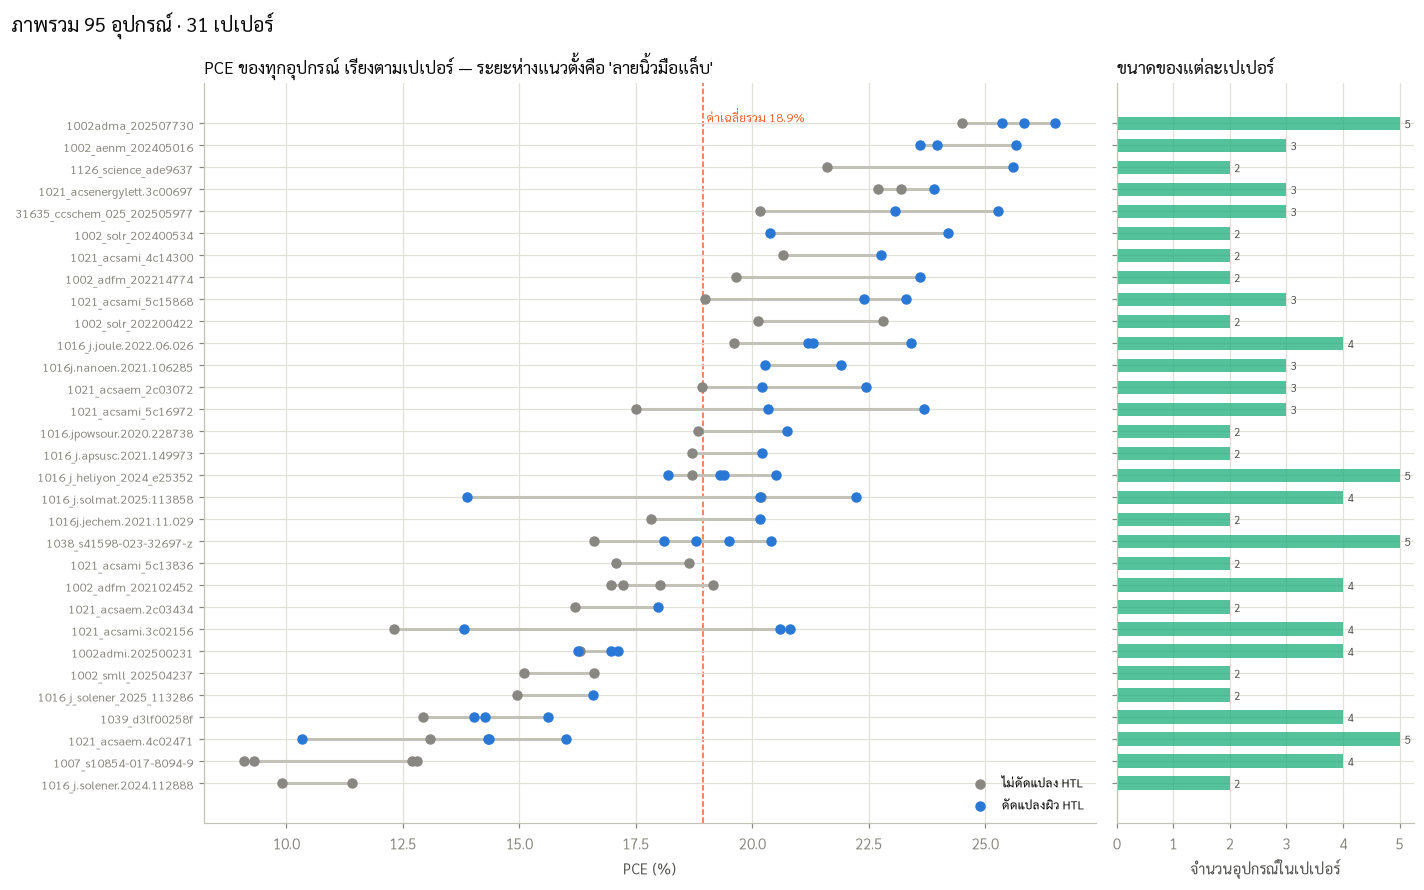

เปเปอร์เล็กสุด 2 เครื่อง · ใหญ่สุด 5 เครื่อง · มัธยฐาน 3 เครื่อง


In [4]:
_ord = F.groupby("paper").pce.mean().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(13, 8.2), gridspec_kw={"width_ratios": [3, 1]}, sharey=True)
for i, p in enumerate(_ord):
    g = F[F.paper == p].dropna(subset=["pce"])
    if g.empty:
        continue
    ax[0].plot([g.pce.min(), g.pce.max()], [i, i], color=BASE, lw=2, zorder=1)
    ax[0].scatter(g[~g.htl_mod].pce, [i] * (~g.htl_mod).sum(), s=34, color=MUTED,
                  zorder=3, label="ไม่ดัดแปลง HTL" if i == 0 else None)
    ax[0].scatter(g[g.htl_mod].pce, [i] * g.htl_mod.sum(), s=34, color=C1,
                  zorder=3, label="ดัดแปลงผิว HTL" if i == 0 else None)
ax[0].set_yticks(range(len(_ord)))
ax[0].set_yticklabels([pname(p, 30) for p in _ord], fontsize=8)
ax[0].axvline(F.pce.mean(), color=C2, ls="--", lw=1, zorder=0)
ax[0].text(F.pce.mean(), len(_ord) - 0.3, f" ค่าเฉลี่ยรวม {F.pce.mean():.1f}%", color=C2, fontsize=8, va="top")
ax[0].set_xlabel("PCE (%)")
ax[0].set_title("PCE ของทุกอุปกรณ์ เรียงตามเปเปอร์ — ระยะห่างแนวตั้งคือ 'ลายนิ้วมือแล็บ'", loc="left")
ax[0].legend(frameon=False, fontsize=8, loc="lower right")
cnt = F.groupby("paper").size().reindex(_ord)
ax[1].barh(range(len(_ord)), cnt.values, color=C3, alpha=.75, height=.6)
for i, v in enumerate(cnt.values):
    ax[1].text(v + .08, i, str(v), va="center", fontsize=7.5, color=INK2)
ax[1].set_xlabel("จำนวนอุปกรณ์ในเปเปอร์")
ax[1].set_title("ขนาดของแต่ละเปเปอร์", loc="left")
fig.suptitle(f"ภาพรวม {N_DEV} อุปกรณ์ · {N_PAPER} เปเปอร์", x=.008, ha="left", fontsize=13, color=INK)
fig.tight_layout()
plt.show()
print(f"เปเปอร์เล็กสุด {cnt.min()} เครื่อง · ใหญ่สุด {cnt.max()} เครื่อง · มัธยฐาน {cnt.median():.0f} เครื่อง")

**อ่านกราฟยังไง**

กราฟซ้ายคือ PCE ของทุกเครื่อง เรียงเป็นแถวตามเปเปอร์ · จุดเทา = เครื่องควบคุม (ไม่ดัดแปลง HTL) · จุดน้ำเงิน = เครื่องที่ดัดแปลง

สองอย่างที่ต้องเห็น:
1. **ความยาวของแต่ละเส้นแนวนอน** = ช่วงที่เปเปอร์ฉบับนั้นทำได้เอง (สั้น ๆ 1-3 จุด)
2. **ระยะห่างแนวตั้งระหว่างเส้น** = ความต่างระหว่างแล็บ — **ใหญ่กว่าความยาวเส้นมาก**

ข้อ 2 คือหัวใจของปัญหาทั้งหมดในโน้ตบุ๊กนี้ และเป็นเหตุผลที่ §7 ต้องมีอยู่

## 2. พจนานุกรมคอลัมน์ — 257 คอลัมน์ ทุกตัวทำหน้าที่อะไร

ตารางด้านล่างคือคำตอบของคำถาม *"แต่ละคอลัมน์มีอะไรบ้าง ทำหน้าที่อะไรยังไง"* แบบครบทุกตัว

**บทบาท 10 แบบ** ที่ใช้จัดหมวด:

| บทบาท | หมายความว่า | เอาไปทำอะไร |
|---|---|---|
| **คีย์** | ใช้ระบุตัวหรือ join | ห้ามใส่เป็น feature |
| **ผลลัพธ์ Y** | สิ่งที่เราอยากทำนาย | เป้าหมายของโมเดล |
| **ตัวกลาง** | ปริมาณกายภาพที่คั่นระหว่าง process กับ Y | ใช้อธิบาย "ทำไมถึงดีขึ้น" |
| **ตัวแปรต้น X** | ปุ่มที่ห้องแล็บหมุนได้ | ตัวแปรที่อยากรู้ผล |
| **ตัวควบคุม** | สิ่งที่กระทบ Y แต่ไม่ใช่สิ่งที่เราศึกษา | ต้องใส่โมเดลเพื่อกันสรุปผิด |
| **เสถียรภาพ** | ผลการทดสอบความทนทาน | Y ตัวที่สอง |
| **ร่องรอยการคลีน** | บันทึกว่าค่านี้ถูกแก้อะไรไปบ้าง | ตรวจย้อนกลับ ไม่ใช่ feature |
| **ที่มา/หลักฐาน** | บอกว่าตัวเลขมาจากไหน | เขียน methods / ตอบ reviewer |
| **ธงคุณภาพ** | บอกว่าค่านี้เอาไปเทียบข้ามเปเปอร์ได้ไหม | กรองก่อนวิเคราะห์ |
| **ค่าดิบ** | ข้อความตามที่เปเปอร์เขียน ยังไม่ได้แปลง | อย่าใช้ตรง ๆ — ใช้คู่ `_parsed` แทน |

> เปิดดูได้ทั้งหมดที่ `processed/eda/column_catalog.csv` (กรองใน Excel สะดวกกว่าเลื่อนในโน้ตบุ๊ก)

In [5]:
# ---------- บทบาทของคอลัมน์ (ใช้ซ้ำทุกหัวข้อถัดไป) ----------
KEY, Y, MED, X, CTRL, STAB, TRACE, PROV, FLAG, RAW = (
    "คีย์", "ผลลัพธ์ Y", "ตัวกลาง", "ตัวแปรต้น X", "ตัวควบคุม",
    "เสถียรภาพ", "ร่องรอยการคลีน", "ที่มา/หลักฐาน", "ธงคุณภาพ", "ค่าดิบ")

D = {}

D["target_table"] = {
 "device_id": (KEY, "รหัสอุปกรณ์ = DOI ของเปเปอร์ + หมายเลข Sample · ตัดที่ `_Sample` ได้ชื่อเปเปอร์ ใช้เป็น group ใน LOPO"),
 "is_coated": (FLAG, "มีชั้นเคลือบผิวอย่างน้อย 1 ชั้นไหม — **True ทั้ง 95 เครื่อง** (ทุกเครื่องมี BCP ที่ L7) variance 0 ใช้เป็นตัวแปรไม่ได้"),
 "n_coating_layers": (X, "นับชั้นเคลือบผิวจริง (L3/L5/L7) 0-3 ชั้น — เกือบทั้งหมดขยับตาม coat_htl"),
 "coat_htl": (X, "เคลือบผิว HTL (L3) ไหม — ฟิล์มบางทับผิว NiOx ก่อนวาง perovskite เพื่ออุด defect ที่ 'รอยต่อฝังใต้ดิน'"),
 "coat_psk": (X, "เคลือบผิว perovskite (L5) ไหม — เกือบทั้งหมดคือ PEAI ที่สร้างชั้น 2D บาง ๆ ทับหน้า"),
 "coat_etl": (FLAG, "เคลือบผิว ETL (L7) ไหม — True ทั้ง 95 เครื่อง variance 0 เก็บไว้ sanity check เท่านั้น"),
 "anneal_htl": (X, "มีขั้นอบ HTL ไหม (NiOx อบ 270-450 °C)"),
 "anneal_psk": (X, "มีขั้นอบ perovskite ไหม (อบ 100-150 °C ร้อนกว่านี้สารอินทรีย์สลาย)"),
 "htl_mod_kind": (X, "ชนิดการดัดแปลง HTL: `coating` เคลือบทับเป็นชั้นแยก / `additive` ผสมในน้ำหมึกแล้ว spin ครั้งเดียว / ว่าง = ไม่ดัดแปลง ⭐ ตัวแปรต้นที่ดีที่สุดของชุดนี้"),
 "psk_mod_kind": (X, "ชนิดการดัดแปลงผิว perovskite — coating ทั้งหมด ไม่มี additive"),
 "jv_variant": (PROV, "ค่า J-V ชุดไหน: `champion` เซลล์ดีที่สุด / `average` เฉลี่ยหลายเซลล์ / `plain` ไม่ระบุ — **ปนกันไม่ได้** เพราะ champion สูงกว่า average เป็นระบบ"),
 "jv_scan": (PROV, "ทิศทางการสแกนวัด: `RS` reverse scan / `-` ไม่ระบุ — reverse scan ให้ค่าสูงกว่า forward เป็นระบบ (hysteresis)"),
 "pce": (Y, "**ประสิทธิภาพรวม (%)** = Voc × Jsc × FF / 100 · แปลงแสงเป็นไฟได้กี่ % ของที่ตกกระทบ · ตัวชี้วัดหลักของทั้งงาน"),
 "voc": (Y, "แรงดันวงจรเปิด (V) — แรงดันสูงสุดตอนไม่จ่ายกระแส บอก 'คุณภาพ' ของประจุ · defect เยอะ Voc ตก"),
 "jsc": (Y, "กระแสลัดวงจร (mA cm⁻²) — กระแสสูงสุดตอนลัดวงจร บอก 'ปริมาณ' แสงที่เก็บได้ · ขึ้นกับ bandgap และความหนา PSK"),
 "ff": (Y, "ฟิลล์แฟกเตอร์ (%) — ความ 'เหลี่ยม' ของกราฟ J-V บอกการสูญเสียจากความต้านทานภายในและกระแสรั่ว"),
 "rrec": (MED, "ความต้านทาน recombination (Ω) จากการวัดอิมพีแดนซ์ — **สูง = ดี** (ประจุตายยาก) · n น้อยและสเกลข้ามเปเปอร์ไม่ตรงกัน"),
 "rs": (MED, "ความต้านทานอนุกรม (Ω cm²) — **ต่ำ = ดี** · กินค่า FF โดยตรง"),
 "vtfl": (MED, "⛔ **ตัดออกจากการวิเคราะห์ในโน้ตบุ๊กนี้ตามที่ผู้ใช้กำหนด** — แรงดันจุด trap-filled limit จาก SCLC · เก็บไว้ในพจนานุกรมเพื่อความครบเท่านั้น"),
 "trap_density": (MED, "ความหนาแน่นของ trap ฝั่งโฮล (cm⁻³) — **ต่ำ = ดี** · trap คือ 'หลุม' ในผลึกที่ดักประจุให้ตายก่อนถึงขั้ว · ตัวกลางหลักที่ใช้แทน VTFL"),
 "trap_density_electron": (MED, "trap ฝั่งอิเล็กตรอน — มีแค่ 3 เครื่องจากเปเปอร์เดียว ใช้วิเคราะห์ไม่ได้"),
 "defect_density_reported": (MED, "ค่า defect density ที่เปเปอร์รายงานเอง (คนละนิยามกับ trap_density) — 2 เครื่อง"),
 "trap_implied_thickness_nm": (FLAG, "ความหนาที่ย้อนคำนวณได้จากสูตร trap↔VTFL — ใช้ตรวจว่าค่า trap ของเปเปอร์นั้นอยู่สเกลเดียวกับคนอื่นไหม"),
 "trap_scale_flag": (FLAG, "`ok` / `scale_suspect` (สเกลน่าสงสัย เทียบข้ามเปเปอร์ไม่ได้) / `no_vtfl` — **ไม่ใช่ feature** เป็นใบอนุญาตว่าค่าไหนเอาไปเทียบได้"),
 "rrec_scale_flag": (FLAG, "เหมือน trap_scale_flag แต่ของ Rrec"),
 "sheet_resistance_htl": (PROV, "ความต้านทานแผ่นของ HTL (Ω/sq) — ย้ายออกจาก rs เพราะคนละปริมาณ · 2 เครื่อง"),
 "retention_25c": (STAB, "PCE เหลือกี่ % หลังทดสอบที่อุณหภูมิห้อง — **ปัญหา: รวมหลาย timescale และหลายบรรยากาศเข้าด้วยกัน** §8 เสนอหน่วยเทียบที่ดีกว่า"),
 "degradation_rate": (STAB, "อัตราการเสื่อม (% ต่อชั่วโมง) — เทียบข้าม timescale ตรง ๆ ไม่ได้ เพราะการเสื่อมไม่เป็นเส้นตรง (ช่วงแรกตกเร็ว)"),
 "psk_spin_rpm": (X, "ความเร็วปั่นเคลือบชั้น perovskite (RPM) — เร็วขึ้น ฟิล์มบางลง/แห้งเร็วขึ้น กระทบจังหวะเกิดผลึก"),
 "psk_anneal_C": (X, "อุณหภูมิอบ perovskite (°C) ใช้ค่าสูงสุดของทุกขั้น"),
 "psk_anneal_time_s": (X, "เวลารวมของทุกขั้นอบ perovskite (วินาที) — ⚠️ เครื่องที่อบสองขั้นจะรวมเวลาขั้นอุ่นต่ำเข้ามาด้วย"),
 "antisolvent_vol_uL": (X, "ปริมาณ antisolvent ที่หยด (µL) — ตัวทำละลายที่ perovskite ไม่ละลาย หยดลงไประหว่างปั่นเพื่อบังคับให้ตกผลึกพร้อมกันทั้งแผ่น"),
 "antisolvent_timing_s": (RAW, "จังหวะหยดตามที่เปเปอร์เขียน — ⚠️ ยังมี 2 จุดอ้างอิงปนกัน (บวก = หลังเริ่มปั่น, ลบ = ก่อนหยุดปั่น) อย่าใช้ตรง ๆ"),
 "antisolvent_timing_ref": (PROV, "จุดอ้างอิงของค่าข้างบน: `after_start` / `before_end`"),
 "htl_anneal_C": (X, "อุณหภูมิอบ HTL (°C) — คนละกลไกกับ psk_anneal_C ห้ามรวมคอลัมน์"),
 "psk_spin_last_s": (X, "ความยาวของขั้นปั่นสุดท้าย (วินาที)"),
 "antisolvent_drop_s": (X, "จังหวะหยดที่แปลงให้อยู่แกนเดียวกันหมดแล้ว (วินาทีนับจากเริ่มปั่นขั้นสุดท้าย)"),
 "antisolvent_drop_frac_of_last": (X, "จังหวะหยดเป็นสัดส่วนของขั้นปั่นสุดท้าย 0-1"),
 "psk_spin_total_s": (X, "ความยาวโปรแกรมปั่นทั้งหมด (วินาที)"),
 "antisolvent_drop_frac_of_total": (X, "จังหวะหยดเป็นสัดส่วนของโปรแกรมปั่นทั้งหมด 0-1 — ⚠️ อย่าใส่คู่กับ timing_s/drop_s เพราะเป็นข้อมูลชุดเดียวกัน"),
 "a_Cs": (CTRL, "สัดส่วนซีเซียมใน A-site (0-1) — อะตอมเล็กช่วยล็อกโครงผลึกให้เสถียร นิยม 5-15%"),
 "a_FA": (CTRL, "สัดส่วน formamidinium ใน A-site — bandgap แคบ ดูดแสงกว้าง Jsc ดี แต่เสถียรภาพแย่ถ้าใช้ล้วน"),
 "x_Br": (CTRL, "สัดส่วนโบรไมด์ใน X-site — **bandgap กว้างขึ้น → Voc สูงขึ้น แต่ Jsc ลด** ⭐ ตัวควบคุมข้ามเปเปอร์ที่ทรงพลังที่สุด (§7)"),
 "etl_family": (CTRL, "ตระกูลวัสดุ ETL: PCBM / C60 / SnO2 / BCP — กระทบการเก็บอิเล็กตรอนที่รอยต่อ"),
}

D["devices"] = {
 "device_id": (KEY, "รหัสอุปกรณ์"),
 "doi_raw": (PROV, "DOI ของเปเปอร์ตามที่ปรากฏในชื่อไฟล์"),
 "sample_no": (PROV, "หมายเลข Sample ภายในเปเปอร์"),
 "source_file": (PROV, "ชื่อไฟล์ Excel ต้นทางใน `Raw Data/` — ใช้ย้อนกลับไปดูต้นฉบับ"),
}
for c in ["is_coated", "n_coating_layers", "coat_htl", "coat_psk", "coat_etl",
          "anneal_htl", "anneal_psk", "htl_mod_kind", "psk_mod_kind"]:
    D["devices"][c] = (D["target_table"][c][0], "ซ้ำกับใน target_table โดยตั้งใจ")
D["device_layer_flags"] = {"device_id": (KEY, "รหัสอุปกรณ์")}
for c in ["is_coated", "n_coating_layers", "coat_htl", "coat_psk", "coat_etl",
          "anneal_htl", "anneal_psk", "htl_mod_kind", "psk_mod_kind"]:
    D["device_layer_flags"][c] = (D["target_table"][c][0], "ซ้ำกับใน devices/target_table — ไฟล์นี้มีไว้ join เบา ๆ")

D["layers"] = {
 "device_id": (KEY, "รหัสอุปกรณ์"),
 "layer_id": (KEY, "เลขชั้น 1-8 จากล่างขึ้นบน: 1 ขั้วโปร่งแสง · 2 HTL · **3 เคลือบ HTL** · 4 perovskite · **5 เคลือบ PSK** · 6 ETL · **7 เคลือบ ETL** · 8 ขั้วโลหะ"),
 "layer_type": (PROV, "ชื่อชั้นตามที่เปเปอร์เรียก เช่น 'ETL treatment (1)/(2)' ตอนชั้นเดียวมี 2 วัสดุ"),
 "material": (X, "ชื่อวัสดุของชั้นนั้น — ชั้น 4 จะเป็นสูตรเคมี ABX₃ เต็ม ๆ"),
 "thickness_nm": (RAW, "ความหนาตามที่เปเปอร์เขียน (ยังเป็นข้อความ อาจเป็นช่วง)"),
 "thickness_nm_parsed": (X, "ความหนาที่แปลงเป็นตัวเลข nm แล้ว (แปลง Å → nm ให้แล้ว) — ใช้ตัวนี้"),
 "thickness_nm_min": (TRACE, "ขอบล่างถ้าเปเปอร์เขียนเป็นช่วง"),
 "thickness_nm_max": (TRACE, "ขอบบนถ้าเปเปอร์เขียนเป็นช่วง"),
 "thickness_nm_note": (TRACE, "เหตุผลที่ค่าที่แปลงต่างจากค่าดิบ"),
 "material_family": (CTRL, "ตระกูลวัสดุ — ⚠️ ว่างเยอะโดยตั้งใจ: ชั้น 4 ใช้ psk_composition แทน ส่วนชั้น 1/2/8 ทุกเครื่องเหมือนกันหมด"),
 "layer_kind": (FLAG, "`main` ชั้นหลัก / `coating` เคลือบทับจริง / `additive` ผสมในน้ำหมึก ไม่ได้เป็นชั้นแยก"),
}

D["materials"] = {
 "device_id": (KEY, "รหัสอุปกรณ์"), "layer_id": (KEY, "ชั้นที่สารนี้ถูกใช้"),
 "material": (X, "ชื่อสารตั้งต้น (precursor) เช่น PbI₂, FAI, CsI หรือตัวทำละลาย"),
 "type": (PROV, "บทบาทของสาร: Solution / Additive / Solvent ฯลฯ"),
 "solvent": (RAW, "ตัวทำละลายตามที่เปเปอร์เขียน (อาจเป็นระบบผสม 'DMF:DMSO 4:1')"),
 "amount": (RAW, "ปริมาณตามที่เปเปอร์เขียน"), "unit": (RAW, "หน่วยของปริมาณ (M, mg/ml, mmol ...)"),
 "amount_parsed": (X, "ปริมาณที่แปลงเป็นตัวเลขแล้ว — ใช้ตัวนี้ · เป็นฐานคำนวณสูตรเคมีจาก precursor"),
 "amount_ratio": (X, "กรณีเปเปอร์ให้เป็นอัตราส่วนแทนปริมาณสัมบูรณ์"),
 "amount_note": (TRACE, "เหตุผลที่ค่าที่แปลงต่างจากค่าดิบ"),
 "material_family": (CTRL, "ตระกูลวัสดุ — ว่างเป็นปกติ สารในตารางนี้ส่วนใหญ่เป็น precursor/solvent ที่ไม่มี 'ตระกูล'"),
 "solvent_1": (X, "ตัวทำละลายหลักหลัง normalize"), "solvent_2": (X, "ตัวทำละลายรอง"),
 "solvent_ratio": (X, "อัตราส่วนผสมของสองตัว"),
 "solvent_system": (X, "ระบบตัวทำละลายแบบ normalize แล้ว (ยุบจาก 27 แบบเหลือ 16)"),
 "solvent_note": (TRACE, "ร่องรอยการ normalize ตัวทำละลาย"),
}

D["properties"] = {
 "device_id": (KEY, "รหัสอุปกรณ์"),
 "property": (RAW, "ชื่อค่าที่วัด ตามที่เปเปอร์เขียนเต็ม ๆ เช่น 'PCE (Champion, RS)'"),
 "value": (RAW, "ค่าตามที่เปเปอร์เขียน (ยังเป็นข้อความ)"), "error": (RAW, "ค่าความคลาดเคลื่อน ± ถ้าเปเปอร์ให้"),
 "unit": (RAW, "หน่วยตามที่เปเปอร์เขียน"), "remarks": (PROV, "หมายเหตุจากผู้กรอก เช่น 'From SEM', 'Figure S8b' — **มีค่ามากตอนตามรอยว่าตัวเลขมาจากรูปไหน**"),
 "unit_corrected": (TRACE, "หน่วยหลังแก้ (เช่น ติดป้าย % ผิดเป็น V)"),
 "value_after_unit_fix": (TRACE, "ค่าหลังแก้หน่วย"), "unit_fix_note": (TRACE, "เหตุผลที่แก้หน่วย"),
 "base_property": (KEY, "ชื่อค่าที่วัดแบบล้วน ๆ หลังถอดวงเล็บออก เช่น `PCE`, `Grain size`, `VTFL` ⭐ ใช้ตัวนี้กรอง"),
 "stat": (KEY, "Champion / Average / ว่าง — แตกมาจากชื่อ property"),
 "scan": (KEY, "RS (reverse) / FS (forward) / ว่าง"),
 "layer": (KEY, "ชั้นที่ค่านี้วัด (บางค่าวัดเฉพาะชั้น เช่น contact angle ของผิว HTL)"),
 "carrier": (KEY, "พาหะที่ค่านี้เกี่ยวข้อง (hole/electron) — สำคัญกับ trap density"),
 "value_parsed": (Y, "**ค่าตัวเลขสุดท้ายที่ควรใช้เสมอ** ผ่านการแก้หน่วยและ parse แล้ว"),
 "value_note": (TRACE, "เหตุผลทุกครั้งที่ value_parsed ต่างจาก value_after_unit_fix"),
}

D["psk_composition"] = {
 "device_id": (KEY, "รหัสอุปกรณ์"),
 "comp_source": (PROV, "สูตรมาจากไหน: `formula` อ่านจากชื่อชั้น / `precursor` คำนวณย้อนจากเกลือที่ชั่ง"),
 "cross_check": (PROV, "⭐ เทียบ 2 แหล่งอิสระแล้วตรงกันไหม — `ตรง` = มั่นใจสูงสุด / ว่าง = ไม่มีแหล่งที่สอง / `ต่าง:` = ขัดกัน ควรเปิดเปเปอร์ก่อนอ้าง"),
 "b_site": (CTRL, "โลหะใน B-site — เป็น Pb ทั้งหมดในชุดนี้ variance 0"),
 "layer_material": (PROV, "ข้อความสูตรดิบจากชั้น 4 ที่ใช้ parse"),
 "precursor_status": (PROV, "เหตุผลที่คำนวณฝั่ง precursor ได้/ไม่ได้ เช่น 'ตกหล่น: MABr'"),
 "a_Cs": (CTRL, "ซีเซียมใน A-site"), "a_FA": (CTRL, "formamidinium ใน A-site"),
 "a_MA": (CTRL, "methylammonium ใน A-site — **ไม่ได้ถูกดึงเข้า target_table** ต้องมาเอาจากไฟล์นี้"),
 "x_I": (CTRL, "ไอโอไดด์ใน X-site — ไม่ได้ถูกดึงเข้า target_table (= 1 − x_Br)"),
 "x_Br": (CTRL, "โบรไมด์ใน X-site"),
 "a_Rb": (CTRL, "รูบิเดียมใน A-site — พบน้อยมาก"),
}

D["stability"] = {
 "device_id": (KEY, "รหัสอุปกรณ์ — **หนึ่งเครื่องมีได้หลายแถว** ถ้าทดสอบหลายเงื่อนไข"),
 "environment": (KEY, "บรรยากาศ/โปรโตคอลตามที่เปเปอร์เขียน — 22 แบบ เขียนไม่เหมือนกันเลย"),
 "encapsulation": (CTRL, "ห่อหุ้มกันอากาศไหม Y/N — **ตัวควบคุมสำคัญ** เครื่องที่ห่อย่อมทนกว่าโดยไม่เกี่ยวกับคุณภาพฟิล์ม"),
 "temperature_c": (RAW, "อุณหภูมิทดสอบตามที่เปเปอร์เขียน"), "humidity_pct": (RAW, "ความชื้นสัมพัทธ์ตามที่เปเปอร์เขียน"),
 "time_hr": (KEY, "⭐ ระยะเวลาทดสอบ (ชั่วโมง) — **ตัวแปรที่ทำให้เทียบข้ามเปเปอร์ไม่ได้มากที่สุด** ชุดนี้กว้าง 0.83-5000 ชม."),
 "retention_pct": (RAW, "PCE ที่เหลือ (%) ตามที่เปเปอร์เขียน"),
 "t80_hr": (STAB, "เวลาที่ PCE ตกถึง 80% — มาตรฐานวงการ แต่ชุดนี้มีแค่ 2 แถว ใช้ไม่ได้"),
 "initial_pce": (STAB, "PCE ก่อนทดสอบ"), "final_pce": (STAB, "PCE หลังทดสอบ"),
 "temperature_c_parsed": (STAB, "อุณหภูมิที่แปลงเป็นตัวเลขแล้ว — ใช้ตัวนี้"),
 "temperature_c_note": (TRACE, "ร่องรอยการแปลงอุณหภูมิ"),
 "humidity_pct_parsed": (STAB, "ความชื้นที่แปลงแล้ว (กลางช่วงถ้าเปเปอร์ให้เป็นช่วง)"),
 "humidity_pct_min": (TRACE, "ขอบล่างของช่วงความชื้น"), "humidity_pct_max": (TRACE, "ขอบบนของช่วงความชื้น"),
 "humidity_pct_note": (TRACE, "ร่องรอยการแปลงความชื้น"),
 "t80_hr_parsed": (STAB, "T80 ที่แปลงแล้ว"), "t80_hr_censor": (FLAG, "ค่า censored เช่น '>1000'"),
 "t80_hr_note": (TRACE, "ร่องรอย T80"),
 "retention_pct_parsed": (STAB, "⭐ **ค่า retention ที่ควรใช้** — ตัวเลขที่ parse แล้ว"),
 "retention_pct_censor": (FLAG, "ค่า censored เช่น '<55'"), "retention_pct_note": (TRACE, "ร่องรอย retention เช่น เกิน 100% จาก light-soaking"),
 "stability_group_placeholder": (STAB, ""),
 "stress_group": (KEY, "⭐ **ยุบ environment 22 แบบเหลือ 6 กลุ่ม**: light/operational · ambient air · inert (N2) · thermal · dark storage · other — §8 ใช้ตัวนี้เป็นหน่วยเทียบ"),
}
D["stability"].pop("stability_group_placeholder")

D["vendors"] = {
 "device_id": (KEY, "รหัสอุปกรณ์"), "material": (KEY, "ชื่อสาร"),
 "purity": (RAW, "ความบริสุทธิ์ตามที่เปเปอร์เขียน"), "vendor": (PROV, "ผู้ขาย/ยี่ห้อ — ⭐ ตัวแทนของ 'ล็อตสารเดียวกันไหม' ซึ่งเป็นส่วนหนึ่งของลายนิ้วมือแล็บ"),
 "purity_pct": (PROV, "ความบริสุทธิ์เป็นตัวเลข %"), "purity_qualifier": (PROV, "คำขยาย เช่น '≥', 'anhydrous'"),
 "purity_kind": (PROV, "ชนิดของค่าที่ให้มา (%, เกรด, ความต้านทานแผ่น)"),
 "material_family": (CTRL, "ตระกูลวัสดุ"),
}

D["process"] = {
 "device_id": (KEY, "รหัสอุปกรณ์"),
 "source_sheet": (FLAG, "⚠️ **ต้องกรองก่อนใช้เสมอ** `Process` = ขั้นตอนสร้างเซลล์จริง / `NiOx synthesis` = สูตรสังเคราะห์ผง NiOx ของเปเปอร์เดียว **ห้ามใช้เป็น feature**"),
 "layer_id": (KEY, "ชั้นที่ขั้นตอนนี้ทำกับมัน — ⚠️ `Annealing__C` ปนทุกชั้น ต้องกรอง layer_id ก่อน"),
 "step_order": (KEY, "ลำดับขั้นตอนภายในชั้น"),
 "process_type": (X, "ชนิดขั้นตอน เช่น Spin coating / Annealing / AntiSolvent — ⚠️ ว่าง = แถว placeholder ของ template ต้องกรอง `.notna()` ทิ้ง"),
 "description": (PROV, "รายละเอียดที่เปเปอร์เขียน เช่น ชื่อ antisolvent ที่ใช้"),
 "parameter": (RAW, "ค่าพารามิเตอร์ดิบ — หลายค่าคั่นด้วยจุลภาค จับคู่กับ unit ตามตำแหน่ง"),
 "unit": (RAW, "หน่วยของพารามิเตอร์ดิบ"), "note": (PROV, "หมายเหตุจากผู้กรอก"),
 "param_fixed": (TRACE, "ธงว่าแถวนี้ถูกแก้ค่าที่กรอกติดกัน (เช่น `100108000` → 100 °C, 1800 s)"),
 "param_recovered": (TRACE, "ธงว่าค่ากู้มาจากช่องที่กรอกผิดคอลัมน์"),
 "param_note": (TRACE, "เหตุผลของการแก้"),
}

D["target_table"]["year"] = (CTRL, "ปีตีพิมพ์ที่อ่านจากรูปแบบ DOI (โน้ตบุ๊กนี้เติมเอง ไม่มีในไฟล์) — ใช้ทดสอบว่า 'ยุคของงาน' อธิบายความต่างข้ามเปเปอร์ได้ไหม")

UNIT_TH = {"C": "องศาเซลเซียส", "hr": "ชั่วโมง", "min": "นาที", "sec": "วินาที", "RPM": "รอบต่อนาที",
           "RPM/s": "อัตราเร่งรอบ", "W": "วัตต์", "V": "โวลต์", "M": "โมลาร์", "Pa": "ปาสคาล",
           "Torr": "ทอร์", "mbar": "มิลลิบาร์", "mtorr": "มิลลิทอร์", "Å/s": "อังสตรอมต่อวินาที",
           "mm/sec": "มิลลิเมตรต่อวินาที", "µm": "ไมโครเมตร", "MPa": "เมกะปาสคาล", "ml": "มิลลิลิตร",
           "uL": "ไมโครลิตร", "Μl": "ไมโครลิตร (ตัวอักษรกรีกพิมพ์ผิดจากต้นฉบับ)", "times": "จำนวนครั้ง"}


def knob_desc(col):
    """คำอธิบายของ 92 คอลัมน์ knob ใน process.csv ที่ชื่อเป็นรูปแบบ ProcessType__unit"""
    if "__" not in col:
        return None
    ptype, u = col.split("__", 1)
    if u == "time_s":
        return (X, f"เวลารวมของขั้น **{ptype}** (วินาที) — รวม sec/min/hr ให้เป็นหน่วยเดียวแล้ว ⭐ ใช้ตัวนี้แทนคอลัมน์ sec/min/hr แยก")
    if col.startswith("AntiSolvent__vol"):
        return (X, "ปริมาณ antisolvent รวมหน่วยแล้ว (µL)")
    if col.startswith("AntiSolvent__timing_ref"):
        return (PROV, "จุดอ้างอิงของจังหวะหยด: after_start / before_end")
    if col.startswith("AntiSolvent__timing"):
        return (X, "จังหวะหยด antisolvent (วินาที) — ยังมี 2 จุดอ้างอิง ดู timing_ref ประกอบ")
    return (X, f"พารามิเตอร์ของขั้น **{ptype}** หน่วย {u} ({UNIT_TH.get(u, u)})")


def build_catalog():
    rows = []
    for tname, df in TABLES.items():
        n_rows = len(df)
        for c in df.columns:
            if c == "paper":
                continue
            role, desc = D.get(tname, {}).get(c, (None, None)) or (None, None)
            if role is None:
                role, desc = knob_desc(c) or (RAW, "—")
            s = df[c]
            nn = s.notna()
            sub = df.loc[nn]
            rows.append({
                "ตาราง": tname, "คอลัมน์": c, "บทบาท": role,
                "ชนิด": ("ทวิภาค" if s.dropna().isin([True, False, 0, 1]).all() and s.nunique(dropna=True) <= 2
                         else "ตัวเลข" if pd.api.types.is_numeric_dtype(s) else "ข้อความ/กลุ่ม"),
                "มีค่า": int(nn.sum()), "%มีค่า": round(100 * nn.sum() / n_rows, 1),
                "ค่าไม่ซ้ำ": int(s.nunique(dropna=True)),
                "อุปกรณ์": int(sub.device_id.nunique()) if "device_id" in df.columns else np.nan,
                "เปเปอร์": int(sub.paper.nunique()) if "paper" in df.columns else np.nan,
                "คำอธิบาย": desc})
    return pd.DataFrame(rows)


CAT = build_catalog()
CAT.to_csv(OUT / "column_catalog.csv", index=False, encoding="utf-8-sig")
print(f"พจนานุกรมคอลัมน์ {len(CAT)} คอลัมน์ จาก {CAT.ตาราง.nunique()} ตาราง → processed/eda/column_catalog.csv")
print(CAT.groupby("บทบาท").size().sort_values(ascending=False).to_string())

พจนานุกรมคอลัมน์ 258 คอลัมน์ จาก 10 ตาราง → processed/eda/column_catalog.csv
บทบาท
ตัวแปรต้น X       132
คีย์               23
ที่มา/หลักฐาน      21
ร่องรอยการคลีน     18
ตัวควบคุม          16
ค่าดิบ             15
ธงคุณภาพ           13
เสถียรภาพ           9
ตัวกลาง             6
ผลลัพธ์ Y           5


In [6]:
# ดูพจนานุกรมทีละตาราง — เปลี่ยนชื่อตารางในตัวแปร SHOW แล้วรันซ้ำได้
SHOW = "target_table"
_v = CAT[CAT["ตาราง"] == SHOW].drop(columns=["ตาราง"])
print(f"{SHOW} — {len(_v)} คอลัมน์")
display(_v.style.hide(axis="index")
        .set_properties(subset=["คำอธิบาย"], **{"text-align": "left", "white-space": "normal", "width": "620px"})
        .set_properties(subset=["คอลัมน์", "บทบาท"], **{"font-weight": "600"}))

target_table — 45 คอลัมน์


คอลัมน์,บทบาท,ชนิด,มีค่า,%มีค่า,ค่าไม่ซ้ำ,อุปกรณ์,เปเปอร์,คำอธิบาย
device_id,คีย์,ข้อความ/กลุ่ม,95,100.000000,95,95,31,รหัสอุปกรณ์ = DOI ของเปเปอร์ + หมายเลข Sample · ตัดที่ `_Sample` ได้ชื่อเปเปอร์ ใช้เป็น group ใน LOPO
is_coated,ธงคุณภาพ,ทวิภาค,95,100.000000,2,95,31,มีชั้นเคลือบผิวอย่างน้อย 1 ชั้นไหม — **True ทั้ง 95 เครื่อง** (ทุกเครื่องมี BCP ที่ L7) variance 0 ใช้เป็นตัวแปรไม่ได้
n_coating_layers,ตัวแปรต้น X,ตัวเลข,95,100.000000,4,95,31,นับชั้นเคลือบผิวจริง (L3/L5/L7) 0-3 ชั้น — เกือบทั้งหมดขยับตาม coat_htl
coat_htl,ตัวแปรต้น X,ทวิภาค,95,100.000000,2,95,31,เคลือบผิว HTL (L3) ไหม — ฟิล์มบางทับผิว NiOx ก่อนวาง perovskite เพื่ออุด defect ที่ 'รอยต่อฝังใต้ดิน'
coat_psk,ตัวแปรต้น X,ทวิภาค,95,100.000000,2,95,31,เคลือบผิว perovskite (L5) ไหม — เกือบทั้งหมดคือ PEAI ที่สร้างชั้น 2D บาง ๆ ทับหน้า
coat_etl,ธงคุณภาพ,ทวิภาค,95,100.000000,2,95,31,เคลือบผิว ETL (L7) ไหม — True ทั้ง 95 เครื่อง variance 0 เก็บไว้ sanity check เท่านั้น
anneal_htl,ตัวแปรต้น X,ทวิภาค,95,100.000000,2,95,31,มีขั้นอบ HTL ไหม (NiOx อบ 270-450 °C)
anneal_psk,ตัวแปรต้น X,ทวิภาค,95,100.000000,2,95,31,มีขั้นอบ perovskite ไหม (อบ 100-150 °C ร้อนกว่านี้สารอินทรีย์สลาย)
htl_mod_kind,ตัวแปรต้น X,ข้อความ/กลุ่ม,56,58.900000,2,56,25,ชนิดการดัดแปลง HTL: `coating` เคลือบทับเป็นชั้นแยก / `additive` ผสมในน้ำหมึกแล้ว spin ครั้งเดียว / ว่าง = ไม่ดัดแปลง ⭐ ตัวแปรต้นที่ดีที่สุดของชุดนี้
psk_mod_kind,ตัวแปรต้น X,ข้อความ/กลุ่ม,41,43.200000,1,41,14,ชนิดการดัดแปลงผิว perovskite — coating ทั้งหมด ไม่มี additive


In [7]:
# ตารางที่เหลืออีก 9 ตาราง — ย่อคำอธิบายให้พอดีหน้าจอ
for t in [k for k in TABLES if k != "target_table"]:
    _v = CAT[CAT["ตาราง"] == t]
    print(f"\n{'='*100}\n{t}  ({len(_v)} คอลัมน์)  —  {UNIT_OF[t]}\n{'='*100}")
    if t == "process":
        _core = _v[~_v["คอลัมน์"].str.contains("__")]
        print(_core[["คอลัมน์", "บทบาท", "ชนิด", "มีค่า", "เปเปอร์", "คำอธิบาย"]]
              .assign(คำอธิบาย=lambda d: d["คำอธิบาย"].map(lambda s: short(s, 88))).to_string(index=False))
        _knob = _v[_v["คอลัมน์"].str.contains("__")].sort_values("มีค่า", ascending=False)
        print(f"\n  + อีก {len(_knob)} คอลัมน์ knob รูปแบบ ProcessType__unit (แตกมาจาก parameter/unit อัตโนมัติ)")
        print("  10 ตัวที่มีข้อมูลมากที่สุด:")
        print("    " + " · ".join(f"{r['คอลัมน์']} ({r['มีค่า']})" for _, r in _knob.head(10).iterrows()))
        print(f"    ที่เหลือมีข้อมูล ≤ {_knob['มีค่า'].iloc[10]} แถว — ส่วนใหญ่เป็นขั้นตอนเฉพาะของไม่กี่เปเปอร์")
    else:
        print(_v[["คอลัมน์", "บทบาท", "ชนิด", "มีค่า", "เปเปอร์", "คำอธิบาย"]]
              .assign(คำอธิบาย=lambda d: d["คำอธิบาย"].map(lambda s: short(s, 88))).to_string(index=False))


devices  (13 คอลัมน์)  —  1 แถว = 1 อุปกรณ์ (ทะเบียน + ธงสถาปัตยกรรม)
         คอลัมน์         บทบาท          ชนิด  มีค่า  เปเปอร์                                                     คำอธิบาย                                                    คําอธิบาย
       device_id          คีย์ ข้อความ/กลุ่ม     95       31                                                  รหัสอุปกรณ์                                                  รหัสอุปกรณ์
         doi_raw ที่มา/หลักฐาน ข้อความ/กลุ่ม     95       31                          DOI ของเปเปอร์ตามที่ปรากฏในชื่อไฟล์                          DOI ของเปเปอร์ตามที่ปรากฏในชื่อไฟล์
       sample_no ที่มา/หลักฐาน        ตัวเลข     95       31                                  หมายเลข Sample ภายในเปเปอร์                                  หมายเลข Sample ภายในเปเปอร์
     source_file ที่มา/หลักฐาน ข้อความ/กลุ่ม     95       31 ชื่อไฟล์ Excel ต้นทางใน `Raw Data/` — ใช้ย้อนกลับไปดูต้นฉบับ ชื่อไฟล์ Excel ต้นทางใน `Raw Data/` — ใช้ย้อนกลับไปดูต้นฉบับ
       is_coat

**ข้อควรระวัง 5 ข้อที่กินเวลาดีบั๊กมากที่สุด** — สรุปจากตารางข้างบน

1. `process.csv` — ต้องกรอง `source_sheet == "Process"` และ `process_type.notna()` **ทุกครั้ง**
   (ชีต `NiOx synthesis` เป็นสูตรสังเคราะห์ผงของเปเปอร์เดียว ถ้าหลุดเข้าโมเดลจะกลายเป็นลายนิ้วมือเปเปอร์นั้น
   ส่วนแถว `process_type` ว่างคือช่องว่างของ template ไม่ใช่ข้อมูล)
2. `Annealing__C` **ปนทุกชั้น** — HTL อบ 270-450 °C ส่วน perovskite อบ 100-150 °C คนละกลไกโดยสิ้นเชิง ต้องกรอง `layer_id` ก่อน
3. `properties.csv` มี**หลายแถวต่อหนึ่งเครื่อง** (champion/average/ทิศสแกน) — pivot เองต้องเลือก variant ให้ตรงกันทั้ง 4 ค่า
4. ใช้คอลัมน์ `*_parsed` เสมอ ไม่ใช่คอลัมน์ดิบ
5. `is_coated` และ `coat_etl` เป็น True ทั้ง 95 เครื่อง — **variance ศูนย์ ใส่เป็น feature ไม่ได้**

## 3. สถิติรายคอลัมน์

สองตารางข้างล่างตอบว่า *"แต่ละคอลัมน์มีข้อมูลทางสถิติจาก dataset ยังไง"*

**คอลัมน์ที่ต้องดูเป็นพิเศษคือคอลัมน์สุดท้าย `SD ในเปเปอร์ ÷ SD รวม`** — อ่านว่า
"ความผันผวนภายในแล็บเดียวกัน เป็นกี่เท่าของความผันผวนทั้งชุด"

- ค่าใกล้ **0.00** = ค่านี้ **ไม่ขยับเลยภายในเปเปอร์** → มันคือ *ค่าตั้งของแล็บ* ไม่ใช่ตัวแปร
- ค่าใกล้ **0.3-0.6** = ขยับพอสมควรภายในเปเปอร์ → เป็นตัวแปรที่เอามาวัดผลได้

จะเห็นทันทีว่าพารามิเตอร์เชิงตัวเลขทุกตัว (RPM, อุณหภูมิ, เวลา, antisolvent) ได้ **0.00** ทั้งแถว
ส่วนผลลัพธ์ (PCE/Voc/Jsc/FF) ได้ 0.3 กว่า ๆ — ความต่างนี้คือเรื่องทั้งหมดของ §5 และ §7

In [8]:
STAT_COLS = TARGET + MEDIATOR + ["contact_angle_deg", "retention_25c", "degradation_rate"] + \
            [c for c in ALL_FEAT if c in F.columns and pd.api.types.is_numeric_dtype(F[c]) and F[c].nunique() > 2]
STAT_COLS = list(dict.fromkeys(STAT_COLS))
rows = []
for c in STAT_COLS:
    s = pd.to_numeric(F[c], errors="coerce")
    d = s.dropna()
    if d.empty:
        continue
    rows.append({"คอลัมน์": c, "บทบาท": ("ผลลัพธ์ Y" if c in TARGET else "ตัวกลาง" if c in MEDIATOR
                                        else "เสถียรภาพ" if c in STABILITY else GROUP_OF.get(c, "อื่น ๆ")),
                 "n": len(d), "เปเปอร์": int(F.loc[s.notna(), "paper"].nunique()),
                 "ขาด %": round(100 * (1 - len(d) / len(F)), 1),
                 "ต่ำสุด": d.min(), "Q1": d.quantile(.25), "มัธยฐาน": d.median(),
                 "Q3": d.quantile(.75), "สูงสุด": d.max(), "เฉลี่ย": d.mean(), "SD": d.std(),
                 "เบ้": d.skew(), "ค่าไม่ซ้ำ": d.nunique(),
                 "SD ในเปเปอร์ ÷ SD รวม": round(F.groupby("paper")[c].std().median() / d.std(), 2) if d.std() else np.nan})
NUMSTAT = pd.DataFrame(rows)
for c in ["ต่ำสุด", "Q1", "มัธยฐาน", "Q3", "สูงสุด", "เฉลี่ย", "SD", "เบ้"]:
    NUMSTAT[c] = NUMSTAT[c].map(lambda v: f"{v:,.4g}")
NUMSTAT.to_csv(OUT / "numeric_stats.csv", index=False, encoding="utf-8-sig")
print("สถิติรายคอลัมน์ — ตัวเลข (→ processed/eda/numeric_stats.csv)")
print("คอลัมน์ 'SD ในเปเปอร์ ÷ SD รวม' ใกล้ 0 = ค่านี้แทบไม่ขยับภายในเปเปอร์ (คือค่าคงที่ของแล็บ)")
print(NUMSTAT.to_string(index=False))

CATC = [c for c in ALL_FEAT + ["jv_variant", "jv_scan", "trap_scale_flag", "htl_mod_material"]
        if c in F.columns and not pd.api.types.is_numeric_dtype(F[c])]
rows = []
for c in dict.fromkeys(CATC):
    s = F[c].fillna("(ไม่มีค่า)")
    vc = s.value_counts()
    rows.append({"คอลัมน์": c, "ระดับ": int(F[c].nunique()), "มีค่า": int(F[c].notna().sum()),
                 "เปเปอร์ที่แปรค่า": papers_varying(c),
                 "การกระจาย": " · ".join(f"{short(k, 18)} {v}" for k, v in vc.head(6).items())
                              + (f" · (+อีก {len(vc)-6})" if len(vc) > 6 else "")})
CATSTAT = pd.DataFrame(rows)
CATSTAT.to_csv(OUT / "categorical_stats.csv", index=False, encoding="utf-8-sig")
print("\nสถิติรายคอลัมน์ — ข้อความ/กลุ่ม (→ processed/eda/categorical_stats.csv)")
print(CATSTAT.to_string(index=False))

สถิติรายคอลัมน์ — ตัวเลข (→ processed/eda/numeric_stats.csv)
คอลัมน์ 'SD ในเปเปอร์ ÷ SD รวม' ใกล้ 0 = ค่านี้แทบไม่ขยับภายในเปเปอร์ (คือค่าคงที่ของแล็บ)
                       คอลัมน์                 บทบาท  n  เปเปอร์  ขาด %     ต่ำสุด     Q1   มัธยฐาน        Q3  สูงสุด    เฉลี่ย        SD     เบ้  ค่าไม่ซ้ำ  SD ในเปเปอร์ ÷ SD รวม
                           pce             ผลลัพธ์ Y 93       31    2.1        9.1  16.59      19.4      21.9    26.5     18.95     4.053 -0.3966         90                   0.36
                           voc             ผลลัพธ์ Y 94       31    1.1       0.85   1.02      1.07     1.142    1.23     1.075   0.08045 -0.3468         47                   0.35
                           jsc             ผลลัพธ์ Y 94       31    1.1      17.73  21.59     22.98     24.38   26.55     22.87     2.028 -0.4476         83                   0.31
                            ff             ผลลัพธ์ Y 94       31    1.1         51  72.25     78.46     81.07   86.35     75.98 

## 4. แต่ละค่ามาจากเปเปอร์ไหน

ตอบคำถาม *"แต่ละ column มี source จาก paper จากไหน"* — สองมุม:
ภาพรวมว่าเปเปอร์ไหนรายงานอะไรไว้บ้าง (heatmap) และสรุปรายค่าว่ามาจากกี่เปเปอร์ (ตาราง)

**ทำไมเรื่องนี้สำคัญ** — ค่าที่มาจากเปเปอร์น้อย ๆ แม้จะมีตัวเลขเยอะก็ใช้สรุปอะไรไม่ได้
เช่นถ้าค่าหนึ่งมาจากเปเปอร์เดียว 5 เครื่อง โมเดลจะเรียนได้แค่ว่า "นี่คือเปเปอร์นั้น" ไม่ใช่กลไกจริง
เกณฑ์ที่ใช้ทั้งเล่ม: **อย่างน้อย 3 เปเปอร์อิสระ** ถึงจะพูดถึงได้

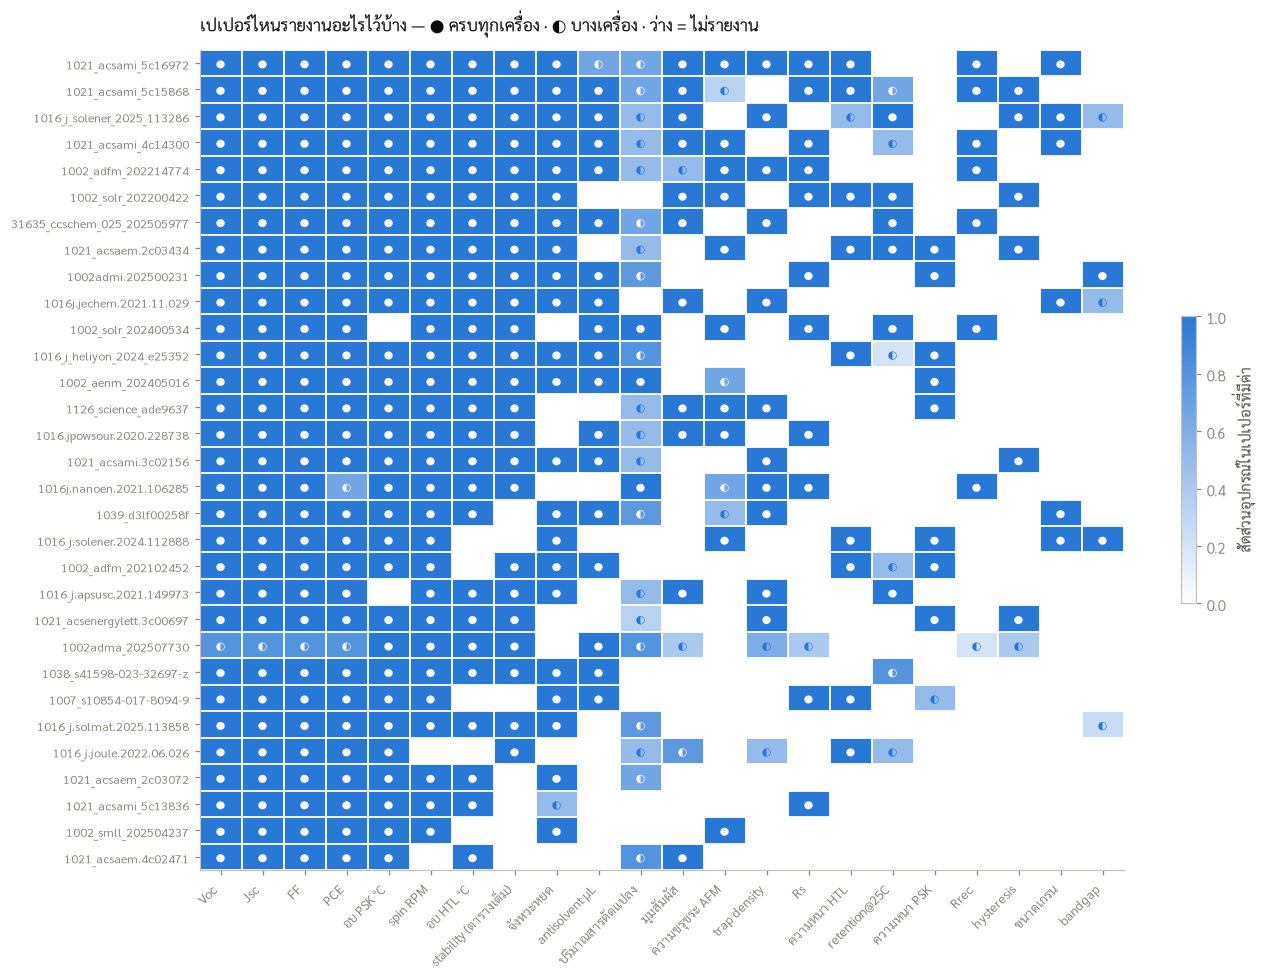

ที่มาของแต่ละค่า — รายงานโดยเปเปอร์กี่ฉบับ (→ processed/eda/measurement_sources.csv)
       ค่าที่วัด  อุปกรณ์ที่มีค่า  เปเปอร์ที่รายงาน  % ของเปเปอร์  เปเปอร์ที่แปรค่าในตัวเอง
             PCE               93                31           100                        31
             Voc               94                31           100                        31
             Jsc               94                31           100                        31
              FF               94                31           100                        31
       อบ PSK °C               91                29            94                         0
        spin RPM               86                29            94                         0
       อบ HTL °C               79                26            84                         0
       จังหวะหยด               68                23            74                         0
ปริมาณสารดัดแปลง               49                23            74                      

In [9]:
MEASURE_COLS = {
    "pce": "PCE", "voc": "Voc", "jsc": "Jsc", "ff": "FF",
    "trap_log": "trap density", "grain_nm": "ขนาดเกรน", "afm_rms_nm": "ความขรุขระ AFM",
    "contact_angle_deg": "มุมสัมผัส", "rs": "Rs", "rrec": "Rrec", "hysteresis_pct": "hysteresis",
    "bandgap_eV": "bandgap", "retention_25c": "retention@25C",
    "psk_spin_rpm": "spin RPM", "psk_anneal_C": "อบ PSK °C", "htl_anneal_C": "อบ HTL °C",
    "antisolvent_vol_uL": "antisolvent µL", "antisolvent_drop_frac_of_total": "จังหวะหยด",
    "htl_thick": "ความหนา HTL", "psk_thick": "ความหนา PSK", "htl_dose": "ปริมาณสารดัดแปลง",
}
_stab_paper = set(stab.dropna(subset=["retention_pct_parsed"]).paper)
cov = pd.DataFrame({lab: F.groupby("paper")[c].apply(lambda s: s.notna().mean())
                    for c, lab in MEASURE_COLS.items()})
cov["stability (ตารางเต็ม)"] = [1.0 if p in _stab_paper else 0.0 for p in cov.index]
cov = cov.loc[cov.mean(axis=1).sort_values(ascending=False).index]
cov = cov[cov.mean().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12.5, 9))
im = ax.imshow(cov.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(cov.shape[1]))
ax.set_xticklabels(cov.columns, rotation=45, ha="right", fontsize=8.5)
ax.set_yticks(range(cov.shape[0]))
ax.set_yticklabels([pname(p, 30) for p in cov.index], fontsize=8)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        v = cov.values[i, j]
        if v > 0:
            ax.text(j, i, "●" if v == 1 else "◐", ha="center", va="center",
                    fontsize=7, color="white" if v > .6 else C1)
ax.set_xticks(np.arange(-.5, cov.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, cov.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", lw=1.2)
ax.grid(False)
ax.tick_params(which="minor", length=0)
ax.set_title("เปเปอร์ไหนรายงานอะไรไว้บ้าง — ● ครบทุกเครื่อง · ◐ บางเครื่อง · ว่าง = ไม่รายงาน",
             loc="left", pad=12)
fig.colorbar(im, ax=ax, shrink=.35, label="สัดส่วนอุปกรณ์ในเปเปอร์ที่มีค่า")
fig.tight_layout()
plt.show()

src = pd.DataFrame({
    "ค่าที่วัด": list(MEASURE_COLS.values()),
    "อุปกรณ์ที่มีค่า": [int(F[c].notna().sum()) for c in MEASURE_COLS],
    "เปเปอร์ที่รายงาน": [int(F.loc[F[c].notna(), "paper"].nunique()) for c in MEASURE_COLS],
    "% ของเปเปอร์": [round(100 * F.loc[F[c].notna(), "paper"].nunique() / N_PAPER) for c in MEASURE_COLS],
    "เปเปอร์ที่แปรค่าในตัวเอง": [papers_varying(c) for c in MEASURE_COLS],
}).sort_values("เปเปอร์ที่รายงาน", ascending=False)
src.to_csv(OUT / "measurement_sources.csv", index=False, encoding="utf-8-sig")
print("ที่มาของแต่ละค่า — รายงานโดยเปเปอร์กี่ฉบับ (→ processed/eda/measurement_sources.csv)")
print(src.to_string(index=False))

**อ่านตารางยังไง**

- คอลัมน์ `เปเปอร์ที่รายงาน` = มีกี่แล็บอิสระที่วัดค่านี้ไว้ — **ตัวเลขนี้สำคัญกว่าจำนวนอุปกรณ์**
- คอลัมน์ `เปเปอร์ที่แปรค่าในตัวเอง` = มีกี่แล็บที่ค่านี้ *ไม่เท่ากัน* ระหว่างเครื่องของตัวเอง

**สิ่งที่ตารางนี้เปิดเผย**: ค่าฝั่ง J-V (PCE/Voc/Jsc/FF) ครบ 31/31 เปเปอร์ และแปรค่าครบ 31/31
แต่พารามิเตอร์การผลิตทุกตัว (spin RPM, อุณหภูมิอบ, antisolvent) แม้จะรายงานไว้ 58-94% ของเปเปอร์
กลับ **แปรค่าภายในเปเปอร์ = 0** ทุกตัว

นี่ไม่ใช่ความบังเอิญ: แต่ละแล็บตั้งสูตรการผลิตไว้คงที่ แล้วแปรเฉพาะสิ่งที่ตัวเองศึกษา
และสิ่งที่วงการ p-i-n ศึกษาช่วงนี้คือ **การดัดแปลงผิว HTL** พอดี

## 5. ตัวแปรไหนใช้ได้จริง — ด่านคัดกรอง 3 ชั้น

| ด่าน | เกณฑ์ | เหตุผล |
|---|---|---|
| 1 | มีค่าอย่างน้อย 20 เครื่อง | น้อยกว่านี้ทดสอบอะไรไม่ได้ |
| 2 | **แปรค่าภายในตัวเองอย่างน้อย 3 เปเปอร์** | ถ้าแปร 0 เปเปอร์ = แยกจาก "ใครทำ" ไม่ออก |
| 3 | ระดับที่พบบ่อยสุดไม่เกิน 95% | ถ้ากระจุกที่ค่าเดียวก็ไม่มีข้อมูล |

ด่าน 2 คือด่านที่ตัดคนออกมากที่สุด และเป็นด่านที่กำหนดทิศของงานทั้งหมด

ด่านคัดกรอง 3 ชั้น → processed/eda/feature_screen.csv
                กลุ่ม                         ตัวแปร      ชนิด  อุปกรณ์ที่มีค่า  เปเปอร์ที่แปรค่าในตัวเอง  ระดับที่พบบ่อยสุด %  ด่าน1 ครอบคลุม≥20  ด่าน2 แปรใน≥3 เปเปอร์  ด่าน3 ไม่กระจุก                  ผล
       โปรโตคอลการวัด                        jv_scan  จัดกลุ่ม               94                         2                   67               True                  False             True    คุมได้อย่างเดียว
          ตัว HTL เอง                      htl_thick ต่อเนื่อง               30                         1                   23               True                  False             True    คุมได้อย่างเดียว
      สถาปัตยกรรมอื่น                       coat_psk    ทวิภาค               95                         1                   57               True                  False             True    คุมได้อย่างเดียว
      สถาปัตยกรรมอื่น                   psk_mod_kind  จัดกลุ่ม               41                         1                 

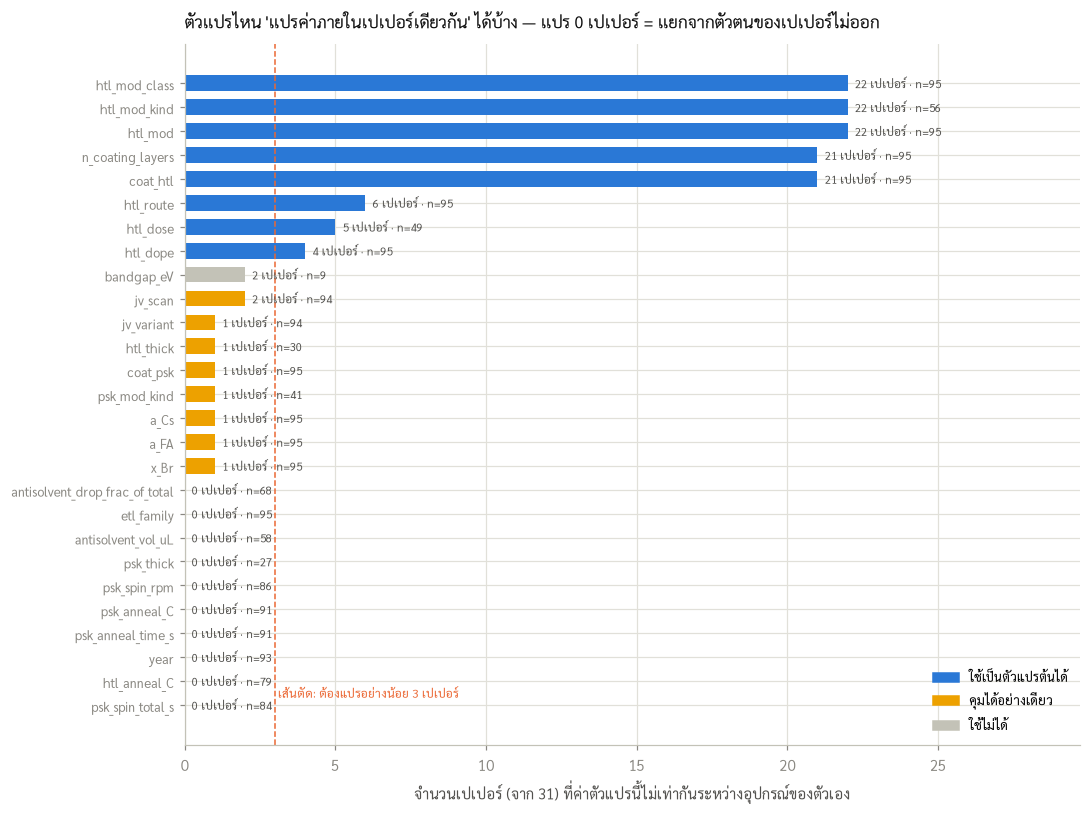

In [10]:
rows = []
for c in ALL_FEAT:
    if c not in F.columns:
        continue
    n_dev = int(F[c].notna().sum())
    npv = papers_varying(c)
    s = F[c].fillna("∅") if not pd.api.types.is_numeric_dtype(F[c]) else F[c]
    top = s.value_counts(normalize=True, dropna=True).iat[0] if s.notna().any() else 1.0
    g1, g2, g3 = n_dev >= 20, npv >= 3, top <= 0.95
    rows.append({"กลุ่ม": GROUP_OF[c], "ตัวแปร": c, "ชนิด": kind_of(c),
                 "อุปกรณ์ที่มีค่า": n_dev, "เปเปอร์ที่แปรค่าในตัวเอง": npv,
                 "ระดับที่พบบ่อยสุด %": round(100 * top),
                 "ด่าน1 ครอบคลุม≥20": g1, "ด่าน2 แปรใน≥3 เปเปอร์": g2, "ด่าน3 ไม่กระจุก": g3,
                 "ผล": "ใช้เป็นตัวแปรต้นได้" if (g1 and g2 and g3) else
                       ("คุมได้อย่างเดียว" if g1 and g3 else "ใช้ไม่ได้")})
SCREEN = pd.DataFrame(rows).sort_values(["ผล", "เปเปอร์ที่แปรค่าในตัวเอง"], ascending=[True, False])
SCREEN.to_csv(OUT / "feature_screen.csv", index=False, encoding="utf-8-sig")
print("ด่านคัดกรอง 3 ชั้น → processed/eda/feature_screen.csv")
print(SCREEN.to_string(index=False))
print("\nสรุป: " + " · ".join(f"{k} {v}" for k, v in SCREEN["ผล"].value_counts().items()))

_s = SCREEN.sort_values("เปเปอร์ที่แปรค่าในตัวเอง")
fig, ax = plt.subplots(figsize=(10, 7.5))
colors = _s["ผล"].map({"ใช้เป็นตัวแปรต้นได้": C1, "คุมได้อย่างเดียว": C4, "ใช้ไม่ได้": BASE})
ax.barh(range(len(_s)), _s["เปเปอร์ที่แปรค่าในตัวเอง"], color=colors, height=.66)
ax.set_yticks(range(len(_s)))
ax.set_yticklabels(_s["ตัวแปร"], fontsize=8.5)
ax.axvline(3, color=C2, ls="--", lw=1)
ax.text(3.1, .3, "เส้นตัด: ต้องแปรอย่างน้อย 3 เปเปอร์", color=C2, fontsize=8)
for i, (v, n) in enumerate(zip(_s["เปเปอร์ที่แปรค่าในตัวเอง"], _s["อุปกรณ์ที่มีค่า"])):
    ax.text(v + .25, i, f"{v} เปเปอร์ · n={n}", va="center", fontsize=7.5, color=INK2)
ax.set_xlabel(f"จำนวนเปเปอร์ (จาก {N_PAPER}) ที่ค่าตัวแปรนี้ไม่เท่ากันระหว่างอุปกรณ์ของตัวเอง")
ax.set_xlim(0, _s["เปเปอร์ที่แปรค่าในตัวเอง"].max() * 1.35)
ax.set_title("ตัวแปรไหน 'แปรค่าภายในเปเปอร์เดียวกัน' ได้บ้าง — แปร 0 เปเปอร์ = แยกจากตัวตนของเปเปอร์ไม่ออก",
             loc="left", pad=10)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in [C1, C4, BASE]]
ax.legend(handles, ["ใช้เป็นตัวแปรต้นได้", "คุมได้อย่างเดียว", "ใช้ไม่ได้"], frameon=False, fontsize=8.5, loc="lower right")
fig.tight_layout()
plt.show()

**อ่านผลยังไง**

- **ใช้เป็นตัวแปรต้นได้** = ผ่านทั้ง 3 ด่าน เอาไปวัดผลได้จริง — ทั้งหมดเป็นตระกูล "การดัดแปลง HTL" กับ "ตัว HTL เอง"
- **คุมได้อย่างเดียว** = มีข้อมูลครบแต่ไม่แปรภายในเปเปอร์ → ใส่โมเดลได้ในฐานะ*ตัวควบคุม*
  แต่ห้ามตีความ SHAP ของมันว่าเป็นกลไก เพราะมันคือชื่อเปเปอร์ที่ปลอมตัวมา
- **ใช้ไม่ได้** = ข้อมูลน้อยเกิน

> ⛔ **ข้อค้นพบที่กำหนดทิศของงานทั้งหมด**
> พารามิเตอร์เชิงตัวเลขทุกตัว — spin RPM, อุณหภูมิและเวลาอบ, ปริมาณและจังหวะ antisolvent —
> **แปรค่าภายในเปเปอร์ = 0 ฉบับ** จาก 31 ฉบับ
>
> แปลว่า correlation แรง ๆ ที่เห็นตอนเทกองรวม (เช่น `htl_anneal_C` กับ `ff`) เป็น **between-paper ล้วน**
> ใต้ LeaveOneGroupOut โมเดลแยกไม่ออกว่าเป็นผลของปุ่มหรือของแล็บ
>
> สิ่งที่เหลือใช้ได้จริง: **การดัดแปลงผิว HTL** ซึ่งมี contrast ควบคุม/ทดลอง ภายในตัวเองถึง **22 เปเปอร์**
> — นี่คือการเทียบ A/B ในแล็บเดียวกัน 22 ครั้งอิสระ ซึ่งเป็นหลักฐานที่แข็งแรงที่สุดที่ข้อมูลแบบนี้ให้ได้

## 6. ความสัมพันธ์ระหว่างคอลัมน์

ตอบคำถาม *"ดู correlation ความสัมพันธ์ของแต่ละ column แต่ละ feature"* — แต่วัด **2 แบบคู่กันเสมอ**:

| วิธีวัด | ทำยังไง | ปัญหา |
|---|---|---|
| **กองรวมทุกเปเปอร์ (naive)** | เทข้อมูล 95 เครื่องรวมกันแล้วหา correlation | ปนกับความต่างระหว่างแล็บ |
| **ภายในเปเปอร์** | หา correlation *ในแต่ละเปเปอร์แยกกัน* แล้วค่อยรวมผล | สะอาด แต่ใช้ได้เฉพาะตัวแปรที่แปรค่าภายในเปเปอร์ |

**ช่องว่างระหว่างสองค่า = ขนาดของ confound ที่เปเปอร์ใส่เข้ามา**

วิธีวัดปรับตามชนิดตัวแปร: ต่อเนื่องใช้ Spearman (สหสัมพันธ์อันดับ — ทนค่าสุดโต่งกว่า Pearson)
ส่วนทวิภาค/จัดกลุ่มใช้ผลต่างจากกลุ่มอ้างอิง แล้วทดสอบด้วย sign test (นับว่ากี่เปเปอร์ที่ไปทางเดียวกัน)

In [11]:
REF_LEVEL = {"htl_mod_class": "ไม่ดัดแปลง", "htl_dope": "ไม่เจือ", "htl_route": "สารละลาย",
             "etl_family": "PCBM", "jv_variant": "plain", "jv_scan": "-",
             "htl_mod_kind": "∅", "psk_mod_kind": "∅"}


def _ref_of(m, feat):
    """ระดับอ้างอิงของตัวแปรจัดกลุ่ม -- ต้องกำหนดชัด ไม่งั้นเครื่องหมายของผลกลับทิศได้"""
    for cand in [REF_LEVEL.get(feat), "∅", False, 0]:
        if cand in m.index:
            return cand
    return m.index[0]


def within_effect(feat, targ, min_dev=2):
    """ผลของ feat ต่อ targ ที่วัด 'ภายในเปเปอร์' แล้วรวมข้ามเปเปอร์
    ต่อเนื่อง -> เฉลี่ย Spearman รายเปเปอร์ · ทวิภาค/จัดกลุ่ม -> ผลต่างจากกลุ่มอ้างอิงของเปเปอร์นั้น
    คืน (ค่าผล, จำนวนเปเปอร์, p จาก sign test)"""
    k = kind_of(feat)
    per = []
    for _, g in F.dropna(subset=[targ]).groupby("paper"):
        gg = g.dropna(subset=[feat]) if k == "ต่อเนื่อง" else g.assign(**{feat: g[feat].fillna("∅")})
        if len(gg) < min_dev or gg[feat].nunique() < 2:
            continue
        if k == "ต่อเนื่อง":
            rho, n = spearman(gg[feat], gg[targ])
            if pd.notna(rho):
                per.append(rho)
        else:
            m = gg.groupby(feat)[targ].mean()
            r = _ref_of(m, feat)
            per.append(float(m.drop(index=[r]).mean() - m[r]))
    if not per:
        return np.nan, 0, np.nan
    return float(np.mean(per)), len(per), sign_test(per)[0]


def naive_effect(feat, targ):
    k = kind_of(feat)
    d = F.dropna(subset=[targ])
    if k == "ต่อเนื่อง":
        return spearman(d[feat], d[targ])[0]
    s = d[feat].fillna("∅") if not pd.api.types.is_numeric_dtype(d[feat]) else d[feat]
    m = d.groupby(s)[targ].mean()
    r = _ref_of(m, feat)
    return float(m.drop(index=[r]).mean() - m[r])


rows = []
for c in ALL_FEAT:
    if c not in F.columns:
        continue
    for t in TARGET + ["grain_nm", "trap_log"]:
        w, npap, p = within_effect(c, t)
        rows.append({"กลุ่ม": GROUP_OF[c], "ตัวแปร": c, "ชนิด": kind_of(c), "ผลลัพธ์": t,
                     "รวมทุกเปเปอร์ (naive)": naive_effect(c, t),
                     "ภายในเปเปอร์": w, "เปเปอร์ที่วัดได้": npap, "p (sign test)": p})
EFF = pd.DataFrame(rows)
EFF["หน่วย"] = EFF.ชนิด.map({"ต่อเนื่อง": "rho", "ทวิภาค": "ผลต่าง", "จัดกลุ่ม": "ผลต่าง"})
sig = EFF[(EFF["p (sign test)"] < 0.05) & (EFF["เปเปอร์ที่วัดได้"] >= 3)]
print(f"คู่ (ตัวแปร × ผลลัพธ์) ทั้งหมด {len(EFF)} คู่ · วัดภายในเปเปอร์ได้ {(EFF['เปเปอร์ที่วัดได้'] > 0).sum()} คู่ "
      f"· มีนัยสำคัญ (p<0.05, ≥3 เปเปอร์) {len(sig)} คู่")
print("\nคู่ที่มีนัยสำคัญภายในเปเปอร์ เรียงตาม p:")
print(sig.sort_values("p (sign test)")[["กลุ่ม", "ตัวแปร", "ผลลัพธ์", "หน่วย", "รวมทุกเปเปอร์ (naive)",
                                        "ภายในเปเปอร์", "เปเปอร์ที่วัดได้", "p (sign test)"]]
      .round(3).to_string(index=False))
_mx = EFF.groupby("ตัวแปร")["เปเปอร์ที่วัดได้"].max()
never = sorted(_mx[_mx == 0].index)
print(f"\nตัวแปรที่วัดภายในเปเปอร์ไม่ได้เลย (ไม่แปรค่าในเปเปอร์ใดเลย) {len(never)} ตัว:")
print("  " + ", ".join(never))

คู่ (ตัวแปร × ผลลัพธ์) ทั้งหมด 162 คู่ · วัดภายในเปเปอร์ได้ 78 คู่ · มีนัยสำคัญ (p<0.05, ≥3 เปเปอร์) 25 คู่

คู่ที่มีนัยสำคัญภายในเปเปอร์ เรียงตาม p:
         กลุ่ม           ตัวแปร  ผลลัพธ์  หน่วย  รวมทุกเปเปอร์ (naive)  ภายในเปเปอร์  เปเปอร์ที่วัดได้  p (sign test)
ดัดแปลงผิว HTL          htl_mod      pce ผลต่าง                  2.991         2.247                22          0.000
ดัดแปลงผิว HTL     htl_mod_kind      pce ผลต่าง                  1.380         2.247                22          0.000
ดัดแปลงผิว HTL         coat_htl      pce ผลต่าง                  3.223         2.332                21          0.000
ดัดแปลงผิว HTL    htl_mod_class       ff ผลต่าง                  2.984         2.603                22          0.000
ดัดแปลงผิว HTL    htl_mod_class      pce ผลต่าง                  2.902         2.143                22          0.000
ดัดแปลงผิว HTL     htl_mod_kind       ff ผลต่าง                  3.500         2.755                22          0.000
ดัดแปลงผิว HTL     htl_m

**อ่านผลยังไง**

ตารางข้างบนเรียงตาม p-value ของ sign test — อ่านว่า *"ถ้าจริง ๆ ไม่มีผลอะไรเลย โอกาสที่จะเห็นเปเปอร์ไปทางเดียวกันเยอะขนาดนี้มีเท่าไหร่"*
ยิ่งเลขน้อยยิ่งบังเอิญยาก

สิ่งที่ตารางบอก: **ตัวแปรที่มีนัยสำคัญภายในเปเปอร์เกือบทั้งหมดอยู่ในตระกูลเดียว** — การดัดแปลงผิว HTL
และมันกระทบ **ทุกตัว**: PCE, FF, Jsc, Voc และ trap density

⚠️ จุดที่ต้องระวังที่สุด — กราฟด้านล่างจะแสดง **คู่ที่ทิศกลับข้าง** ระหว่างสองวิธีวัด
พวกนี้คือกับดัก: ถ้าดูแค่ correlation แบบเทกองรวม จะสรุปผิดทิศไปเลย

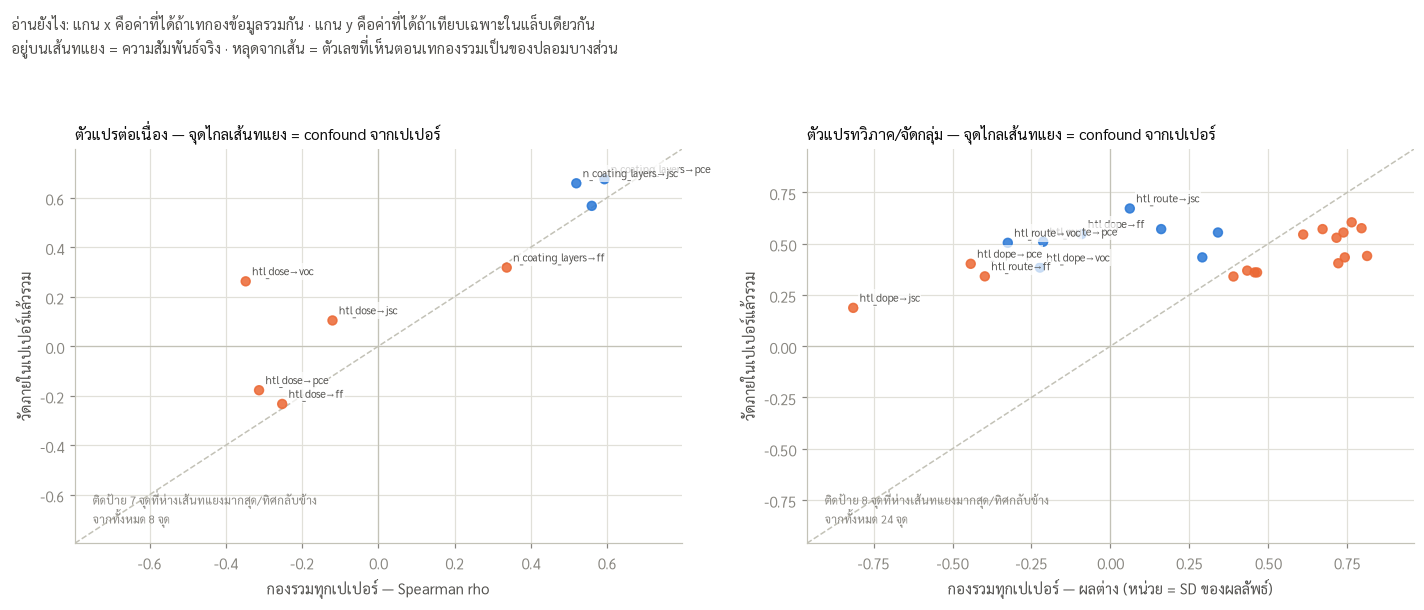

คู่ที่ 'เทกองรวม' กับ 'ภายในเปเปอร์' ให้ทิศตรงข้ามกันเลย: 9 คู่
   ตัวแปร ผลลัพธ์  รวมทุกเปเปอร์ (naive)  ภายในเปเปอร์  เปเปอร์ที่วัดได้
 htl_dose     voc                 -0.348         0.262                 4
 htl_dose     jsc                 -0.120         0.104                 4
 htl_dope     pce                 -1.793         1.628                 4
 htl_dope     voc                 -0.018         0.031                 4
 htl_dope     jsc                 -1.652         0.379                 4
 htl_dope      ff                 -0.702         4.187                 4
htl_route     pce                 -0.863         2.064                 6
htl_route     voc                 -0.026         0.041                 6
htl_route      ff                 -3.046         2.609                 6


In [12]:
# ---- 6.1 naive vs within: ช่องว่างระหว่างสองค่าคือขนาดของ confound ----
plot = EFF[(EFF["เปเปอร์ที่วัดได้"] >= 3) & EFF["ภายในเปเปอร์"].notna()
           & EFF["รวมทุกเปเปอร์ (naive)"].notna()].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, unit in zip(axes, ["rho", "ผลต่าง"]):
    sub = plot[plot["หน่วย"] == unit] if unit == "rho" else plot[plot["หน่วย"] != "rho"]
    sub = sub[sub.ผลลัพธ์.isin(TARGET)]
    if unit != "rho":                       # ผลต่างมีหลายหน่วย -> ปรับเป็นสัดส่วนของ SD ของผลลัพธ์นั้น
        sd = sub.ผลลัพธ์.map(F[TARGET].std())
        x, y = sub["รวมทุกเปเปอร์ (naive)"] / sd, sub["ภายในเปเปอร์"] / sd
        lab = "ผลต่าง (หน่วย = SD ของผลลัพธ์)"
    else:
        x, y = sub["รวมทุกเปเปอร์ (naive)"], sub["ภายในเปเปอร์"]
        lab = "Spearman rho"
    lim = max(1e-9, float(np.nanmax(np.abs(np.r_[x, y]))) * 1.18)
    ax.plot([-lim, lim], [-lim, lim], color=BASE, lw=1, ls="--")
    ax.axhline(0, color=BASE, lw=.8)
    ax.axvline(0, color=BASE, lw=.8)
    ax.scatter(x, y, s=34, color=[C1 if abs(b) > abs(a) else C2 for a, b in zip(x, y)],
               alpha=.85, zorder=3)
    # ติดป้ายเฉพาะจุดที่น่าสนใจ: ทิศกลับข้าง หรือห่างเส้นทแยงมากสุด 7 จุด -- ไม่งั้นป้ายทับกันจนอ่านไม่ออก
    gap = (y - x).abs()
    flip = (x * y) < 0
    keep = set(gap[flip].index) | set(gap.nlargest(7).index)
    for i in keep:
        ax.annotate(f"{sub.ตัวแปร[i]}→{sub.ผลลัพธ์[i]}", (x[i], y[i]), fontsize=7, color=INK2,
                    xytext=(4, 4), textcoords="offset points",
                    bbox=dict(fc="white", ec="none", alpha=.72, pad=.6))
    ax.text(.03, .05, f"ติดป้าย {len(keep)} จุดที่ห่างเส้นทแยงมากสุด/ทิศกลับข้าง\nจากทั้งหมด {len(sub)} จุด",
            transform=ax.transAxes, fontsize=7.5, color=MUTED)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel(f"กองรวมทุกเปเปอร์ — {lab}")
    ax.set_ylabel("วัดภายในเปเปอร์แล้วรวม")
    ax.set_title(f"{'ตัวแปรต่อเนื่อง' if unit == 'rho' else 'ตัวแปรทวิภาค/จัดกลุ่ม'}"
                 " — จุดไกลเส้นทแยง = confound จากเปเปอร์", loc="left", fontsize=10)
fig.suptitle("อ่านยังไง: แกน x คือค่าที่ได้ถ้าเทกองข้อมูลรวมกัน · แกน y คือค่าที่ได้ถ้าเทียบเฉพาะในแล็บเดียวกัน\n"
             "อยู่บนเส้นทแยง = ความสัมพันธ์จริง · หลุดจากเส้น = ตัวเลขที่เห็นตอนเทกองรวมเป็นของปลอมบางส่วน",
             x=.008, ha="left", fontsize=9.5, color=INK2)
fig.tight_layout(rect=[0, 0, 1, .93])
plt.show()

_flip = plot[(plot["รวมทุกเปเปอร์ (naive)"] * plot["ภายในเปเปอร์"]) < 0]
print(f"คู่ที่ 'เทกองรวม' กับ 'ภายในเปเปอร์' ให้ทิศตรงข้ามกันเลย: {len(_flip)} คู่")
if len(_flip):
    print(_flip[["ตัวแปร", "ผลลัพธ์", "รวมทุกเปเปอร์ (naive)", "ภายในเปเปอร์", "เปเปอร์ที่วัดได้"]]
          .round(3).to_string(index=False))

### 6.1 ตัวแปรซ้ำซ้อนกันเอง

ก่อนใส่โมเดลต้องรู้ว่าตัวไหนเป็น "ข้อมูลชุดเดียวกันที่เขียนคนละแบบ"
ถ้าใส่คู่ซ้ำซ้อนพร้อมกัน SHAP จะแบ่งเครดิตกันมั่ว แล้วทั้งคู่จะดูไม่สำคัญทั้งที่จริงสำคัญ

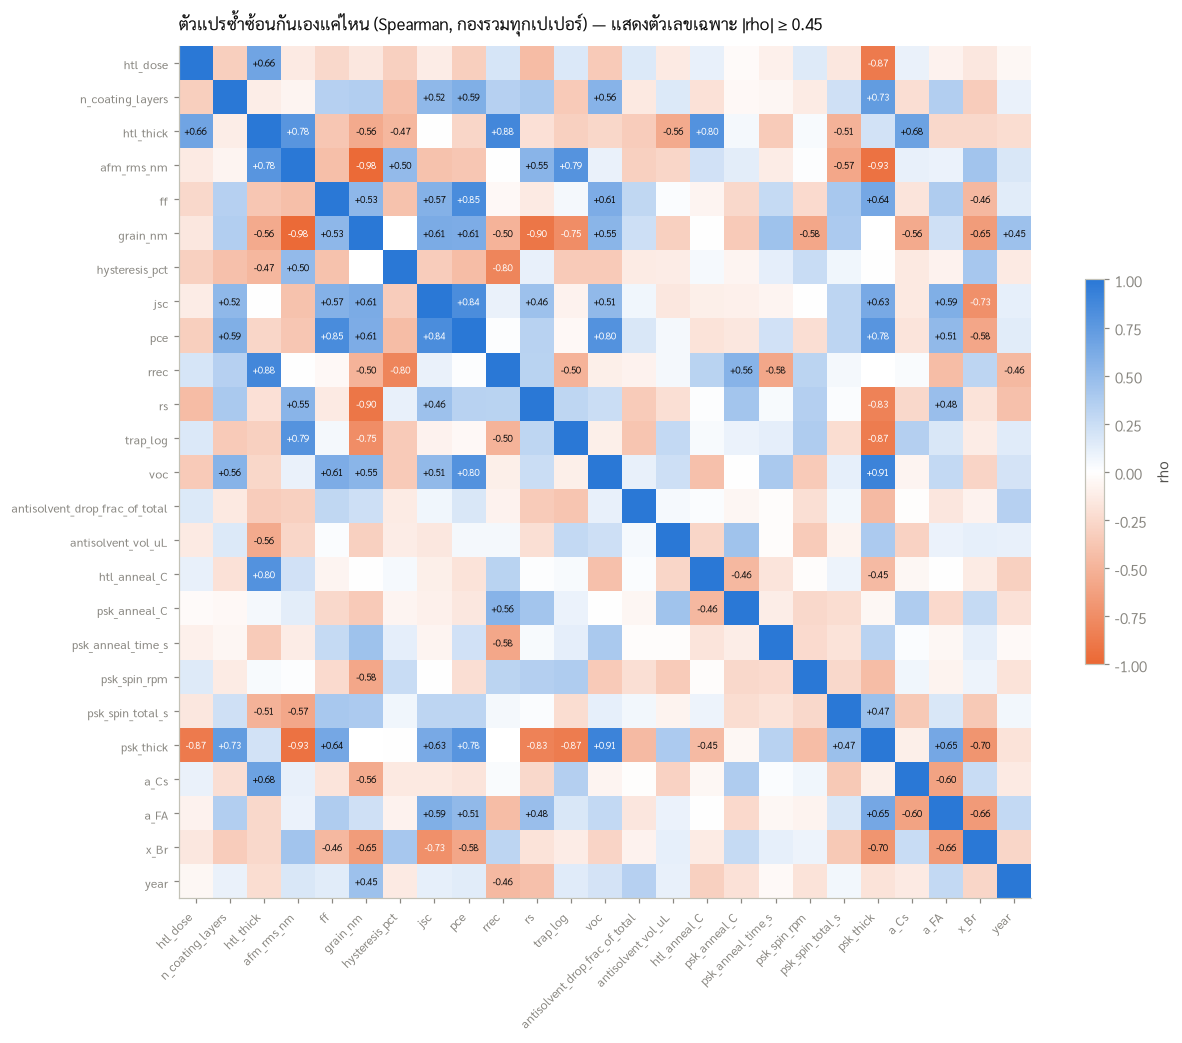

คู่ที่ซ้ำซ้อนกันสูง (|rho| ≥ 0.7, n ≥ 15): 9 คู่ — ใส่พร้อมกันในโมเดลจะทำให้ SHAP แบ่งเครดิตมั่ว
        ตัวแปร A     ตัวแปร B   rho  n         กลุ่ม A               กลุ่ม B
             voc    psk_thick  0.91 27 ผลลัพธ์/ตัวกลาง       สถาปัตยกรรมอื่น
              ff          pce  0.85 93 ผลลัพธ์/ตัวกลาง       ผลลัพธ์/ตัวกลาง
             jsc          pce  0.84 93 ผลลัพธ์/ตัวกลาง       ผลลัพธ์/ตัวกลาง
       htl_thick htl_anneal_C  0.80 16     ตัว HTL เอง พารามิเตอร์เชิงตัวเลข
             pce          voc  0.80 93 ผลลัพธ์/ตัวกลาง       ผลลัพธ์/ตัวกลาง
             pce    psk_thick  0.78 27 ผลลัพธ์/ตัวกลาง       สถาปัตยกรรมอื่น
n_coating_layers    psk_thick  0.73 27  ดัดแปลงผิว HTL       สถาปัตยกรรมอื่น
             jsc         x_Br -0.73 94 ผลลัพธ์/ตัวกลาง  สูตรเคมี (ตัวควบคุม)
       psk_thick         x_Br -0.70 27 สถาปัตยกรรมอื่น  สูตรเคมี (ตัวควบคุม)


In [13]:
NUMC = [c for c in ALL_FEAT + MEDIATOR + TARGET
        if c in F.columns and pd.api.types.is_numeric_dtype(F[c]) and F[c].notna().sum() >= 15
        and F[c].nunique() > 2]
M = pd.DataFrame(index=NUMC, columns=NUMC, dtype=float)
NM = pd.DataFrame(index=NUMC, columns=NUMC, dtype=float)
for a in NUMC:
    for b in NUMC:
        r, n = spearman(F[a], F[b])
        M.loc[a, b], NM.loc[a, b] = r, n

order = sorted(NUMC, key=lambda c: (GROUP_OF.get(c, "ผลลัพธ์/ตัวกลาง"), c))
M, NM = M.loc[order, order], NM.loc[order, order]
fig, ax = plt.subplots(figsize=(11.5, 10))
im = ax.imshow(M.values.astype(float), cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=8)
for i in range(len(order)):
    for j in range(len(order)):
        v, n = M.values[i, j], NM.values[i, j]
        if pd.notna(v) and i != j and abs(v) >= .45:
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=6.2,
                    color="white" if abs(v) > .72 else INK)
ax.grid(False)
ax.set_title("ตัวแปรซ้ำซ้อนกันเองแค่ไหน (Spearman, กองรวมทุกเปเปอร์) — แสดงตัวเลขเฉพาะ |rho| ≥ 0.45",
             loc="left", pad=10)
fig.colorbar(im, ax=ax, shrink=.4, label="rho")
fig.tight_layout()
plt.show()

pairs = []
for i, a in enumerate(order):
    for b in order[i + 1:]:
        r, n = M.loc[a, b], NM.loc[a, b]
        if pd.notna(r) and abs(r) >= .7 and n >= 15:
            pairs.append({"ตัวแปร A": a, "ตัวแปร B": b, "rho": round(r, 2), "n": int(n),
                          "กลุ่ม A": GROUP_OF.get(a, "ผลลัพธ์/ตัวกลาง"), "กลุ่ม B": GROUP_OF.get(b, "ผลลัพธ์/ตัวกลาง")})
RED = pd.DataFrame(pairs).sort_values("rho", key=abs, ascending=False)
print(f"คู่ที่ซ้ำซ้อนกันสูง (|rho| ≥ 0.7, n ≥ 15): {len(RED)} คู่ — ใส่พร้อมกันในโมเดลจะทำให้ SHAP แบ่งเครดิตมั่ว")
print(RED.to_string(index=False))

**คู่ที่น่าสนใจทางฟิสิกส์ ไม่ใช่แค่สถิติ**

- `jsc ↔ x_Br` = **−0.73** — โบรไมด์มากขึ้นทำให้ bandgap กว้างขึ้น ดูดแสงได้ช่วงแคบลง กระแสจึงลด
  นี่คือฟิสิกส์ตำราที่โผล่มาเองในข้อมูล เป็นการยืนยันว่าชุดข้อมูลไม่ได้เพี้ยน
- `ff ↔ pce` = 0.85, `jsc ↔ pce` = 0.84, `voc ↔ pce` = 0.80 — เพราะ PCE เป็นผลคูณของสามตัวนี้ตามนิยาม
  (เหตุผลที่แผนโมเดลคือ **เทรน Voc/Jsc/FF แยกกันแล้วคูณ** ไม่เทรน PCE ตรง ๆ)
- `psk_thick ↔ voc` = 0.91 แต่มาจากแค่ 9 เปเปอร์และไม่แปรภายในเปเปอร์เลย — **อย่าเชื่อ** เป็นลายนิ้วมือแล็บ

## 7. ⭐ ปัญหาการเทียบ PCE ข้ามเปเปอร์ — และตัวควบคุมที่ช่วยได้

> **โจทย์ที่ตั้งไว้**: "จากตอนนี้ที่ทำผลออกมาเพื่อให้เอาไปเทียบข้าม paper ได้ การเทียบเป็นเปอร์เซ็นต์พูดยาก
> เพราะเช่นจาก 25 ไป 27% แทบยากมากในปัจจุบัน จึงต้องการดูว่าอะไรที่เอามาเป็นตัวแปรควบคุมเพื่อเทียบผล PCE นี้ได้"

หัวข้อนี้แยกเป็น 3 ขั้น: **7.1 วัดว่าปัญหาใหญ่แค่ไหน → 7.2 หาว่าตัวควบคุมไหนช่วยได้ → 7.3 เลือกหน่วยเทียบ**

### 7.1 ปัญหาใหญ่แค่ไหน

ก่อนแก้ต้องรู้ขนาดปัญหาก่อน — เราแยกความแปรปรวนของ PCE ออกเป็นสองส่วน:
ส่วนที่มาจาก "เปเปอร์ไหนทำ" กับส่วนที่มาจาก "ภายในเปเปอร์นั้นเขาแปรอะไร"

In [14]:
# ---------- 7.1 แยกความแปรปรวนของ PCE: ระหว่างเปเปอร์ vs ภายในเปเปอร์ ----------
def var_split(df, col, group="paper"):
    d = df.dropna(subset=[col])
    gm, pm = d[col].mean(), d.groupby(group)[col].transform("mean")
    ss_t = ((d[col] - gm) ** 2).sum()
    return ((pm - gm) ** 2).sum() / ss_t, ((d[col] - pm) ** 2).sum() / ss_t, len(d)


print("ความแปรปรวนของผลลัพธ์แต่ละตัว แยกเป็น 'ระหว่างเปเปอร์' กับ 'ภายในเปเปอร์'")
vs = pd.DataFrame([{"ผลลัพธ์": c, "n": var_split(F, c)[2],
                    "ระหว่างเปเปอร์ %": round(100 * var_split(F, c)[0], 1),
                    "ภายในเปเปอร์ %": round(100 * var_split(F, c)[1], 1),
                    "SD รวม": round(F[c].std(), 3),
                    "SD ภายในเปเปอร์ (median)": round(F.groupby("paper")[c].std().median(), 3)}
                   for c in TARGET + ["grain_nm", "trap_density"]])
print(vs.to_string(index=False))

# ---- ขนาดผลที่อยากวัด vs สัญญาณรบกวนข้ามเปเปอร์ ----
d = F.dropna(subset=["pce"])
between_sd = d.groupby("paper").pce.mean().std()
within_sd = d.groupby("paper").pce.std().median()
print(f"\nSD ของค่าเฉลี่ย PCE ระหว่างเปเปอร์ = {between_sd:.2f} %abs")
print(f"SD ของ PCE ภายในเปเปอร์ (median)  = {within_sd:.2f} %abs")
print(f"→ อยากเห็นผล +2 %abs: ถ้าเทียบข้ามเปเปอร์ต้องสู้กับสัญญาณรบกวน {between_sd:.2f}"
      f" (กลบผล {between_sd/2:.1f} เท่า) · ถ้าเทียบภายในเปเปอร์สู้กับ {within_sd:.2f} เท่านั้น")

# ---------- 7.2 ตัวควบคุมตัวไหนดูดความต่างระหว่างเปเปอร์ได้บ้าง ----------
PM = F.groupby("paper").agg(
    pce=("pce", "mean"), n=("pce", "size"), year=("year", "first"),
    a_Cs=("a_Cs", "mean"), a_FA=("a_FA", "mean"), x_Br=("x_Br", "mean"),
    psk_anneal_C=("psk_anneal_C", "mean"), psk_spin_rpm=("psk_spin_rpm", "mean"),
    htl_anneal_C=("htl_anneal_C", "mean"),
    antisolvent_drop_frac_of_total=("antisolvent_drop_frac_of_total", "mean"),
).dropna(subset=["pce"])
PM["etl_family"] = F.groupby("paper").etl_family.agg(lambda s: s.mode().iat[0])
PM["jv_variant"] = F.groupby("paper").jv_variant.agg(lambda s: s.mode().iat[0] if len(s.mode()) else np.nan)

rows = []
for c in ["x_Br", "a_FA", "a_Cs", "year", "psk_anneal_C", "psk_spin_rpm", "htl_anneal_C",
          "antisolvent_drop_frac_of_total"]:
    s = PM.dropna(subset=[c])
    rho, n = spearman(s[c], s.pce)
    r2, b, _ = ols(s.pce.values, s[c].values)
    rows.append({"ตัวควบคุมที่เสนอ": c, "ชนิด": "ต่อเนื่อง", "เปเปอร์ที่มีค่า": n,
                 "rho กับ PCE เฉลี่ยของเปเปอร์": round(rho, 3),
                 "R² (อธิบายความต่างระหว่างเปเปอร์)": round(r2, 3),
                 "ทิศทาง": f"{b[1]:+.2f} %PCE ต่อ 1 หน่วย"})
for c in ["etl_family", "jv_variant"]:
    s = PM.dropna(subset=[c])
    dm = pd.get_dummies(s[c], drop_first=True).astype(float)
    r2, _, _ = ols(s.pce.values, *[dm[k].values for k in dm.columns])
    rows.append({"ตัวควบคุมที่เสนอ": c, "ชนิด": f"จัดกลุ่ม ({s[c].nunique()} ระดับ)", "เปเปอร์ที่มีค่า": len(s),
                 "rho กับ PCE เฉลี่ยของเปเปอร์": np.nan,
                 "R² (อธิบายความต่างระหว่างเปเปอร์)": round(r2, 3), "ทิศทาง": "—"})
CTRL_RANK = pd.DataFrame(rows).sort_values("R² (อธิบายความต่างระหว่างเปเปอร์)", ascending=False)
print(f"\nตัวควบคุมแต่ละตัวอธิบาย 'ทำไมเปเปอร์นี้ PCE สูงกว่าเปเปอร์นั้น' ได้กี่ % (n={len(PM)} เปเปอร์)")
print(CTRL_RANK.to_string(index=False))

s = PM.dropna(subset=["x_Br", "a_FA", "a_Cs"])
r2_comp, b, _ = ols(s.pce.values, s.x_Br.values, s.a_FA.values, s.a_Cs.values)
print(f"\nสูตรเคมี 3 ตัวรวมกัน: R² = {r2_comp:.3f} ของความต่างระหว่างเปเปอร์")
dm = pd.get_dummies(s["etl_family"], drop_first=True).astype(float)
r2_ce, _, _ = ols(s.pce.values, s.x_Br.values, s.a_FA.values, s.a_Cs.values, *[dm[k].values for k in dm.columns])
print(f"+ etl_family: R² = {r2_ce:.3f}")
d2 = F.dropna(subset=["pce"])
dum = pd.get_dummies(d2.paper, drop_first=True).astype(float)
r2_paper, _, _ = ols(d2.pce.values, *[dum[k].values for k in dum.columns])
print(f"เทียบกับ 'ตัวตนของเปเปอร์' (dummy 30 ตัว) ที่ระดับอุปกรณ์: R² = {r2_paper:.3f}")
r2_c_dev, _, _ = ols(d2.pce.values, d2.x_Br.values, d2.a_FA.values, d2.a_Cs.values)
print(f"สูตรเคมีที่ระดับอุปกรณ์: R² = {r2_c_dev:.3f}  → เหลือที่สูตรเคมีอธิบายไม่ได้อีก {100*(r2_paper-r2_c_dev):.0f}% "
      f"ซึ่งคือ 'ฝีมือ/เครื่องมือ/ล็อตสารของแล็บ' ที่วัดไม่ได้")

ความแปรปรวนของผลลัพธ์แต่ละตัว แยกเป็น 'ระหว่างเปเปอร์' กับ 'ภายในเปเปอร์'
     ผลลัพธ์  n  ระหว่างเปเปอร์ %  ภายในเปเปอร์ %       SD รวม  SD ภายในเปเปอร์ (median)
         pce 93              83.3            16.7 4.053000e+00              1.441000e+00
         voc 94              83.3            16.7 8.000000e-02              2.800000e-02
         jsc 94              80.0            20.0 2.028000e+00              6.230000e-01
          ff 94              86.9            13.1 7.659000e+00              2.482000e+00
    grain_nm 15              84.5            15.5 2.002730e+02              6.381600e+01
trap_density 35              81.0            19.0 1.922460e+16              1.044844e+15

SD ของค่าเฉลี่ย PCE ระหว่างเปเปอร์ = 3.66 %abs
SD ของ PCE ภายในเปเปอร์ (median)  = 1.44 %abs
→ อยากเห็นผล +2 %abs: ถ้าเทียบข้ามเปเปอร์ต้องสู้กับสัญญาณรบกวน 3.66 (กลบผล 1.8 เท่า) · ถ้าเทียบภายในเปเปอร์สู้กับ 1.44 เท่านั้น

ตัวควบคุมแต่ละตัวอธิบาย 'ทำไมเปเปอร์นี้ PCE สูงกว่าเปเปอร์นั้น' ได้กี่ % (n=31 เ

**อ่านตัวเลขยังไง — นี่คือคำตอบตรง ๆ ว่าทำไม "25 → 27%" ถึงพูดยาก**

**83% ของความต่างของ PCE ทั้งชุด มาจาก "เปเปอร์ไหนทำ" ไม่ใช่ "ทำอะไรกับเซลล์"**

แปลเป็นภาษาคน: ถ้าหยิบเซลล์สองตัวจากคนละเปเปอร์มาเทียบกัน แล้วเห็นว่าตัวหนึ่ง PCE สูงกว่าอีกตัว 2%
โอกาสที่ความต่างนั้นมาจาก *สิ่งที่ทำกับเซลล์* มีแค่ราว 17% — ที่เหลือคือ
ฝีมือคนทำ · เครื่องมือ · ความสะอาดห้อง · ล็อตสารเคมี · วิธีวัด · แม้แต่ว่าเลือกรายงานเซลล์ตัวไหน

ดูเป็นตัวเลขจากกราฟ (ข):
- ถ้าเทียบ**ข้ามเปเปอร์**: ผลที่อยากเห็น **+2** ต้องสู้กับเสียงรบกวน **3.66** → เสียงดังกว่าสัญญาณเกือบ 2 เท่า **มองไม่เห็น**
- ถ้าเทียบ**ภายในเปเปอร์**: ผลเดิม **+2** สู้กับเสียงรบกวนแค่ **1.44** → **เห็นชัด**

**สรุปขั้นที่ 1: การเทียบ "25% กับ 27%" ข้ามเปเปอร์ตรง ๆ ไม่ได้แปลว่าอะไรเลย ไม่ว่าจะเขียนเป็น %abs หรือ %relative
ปัญหาไม่ได้อยู่ที่หน่วย แต่อยู่ที่การเอาสองเลขจากคนละแล็บมาลบกัน**

### 7.2 ตัวควบคุมไหนอธิบายความต่างข้ามเปเปอร์ได้จริง

ถ้าเราหาตัวแปรที่อธิบายได้ว่า *"ทำไมเปเปอร์ A ถึงได้ PCE สูงกว่าเปเปอร์ B"* ได้มากพอ
ก็หักส่วนนั้นออกแล้วเทียบสิ่งที่เหลือได้ — นี่คือความหมายของ "ตัวแปรควบคุม"

วิธีทดสอบ: ยุบแต่ละเปเปอร์เหลือค่าเฉลี่ยหนึ่งจุด (31 จุด) แล้วดูว่าตัวแปรแต่ละตัวอธิบายการกระจายของ 31 จุดนั้นได้กี่ %

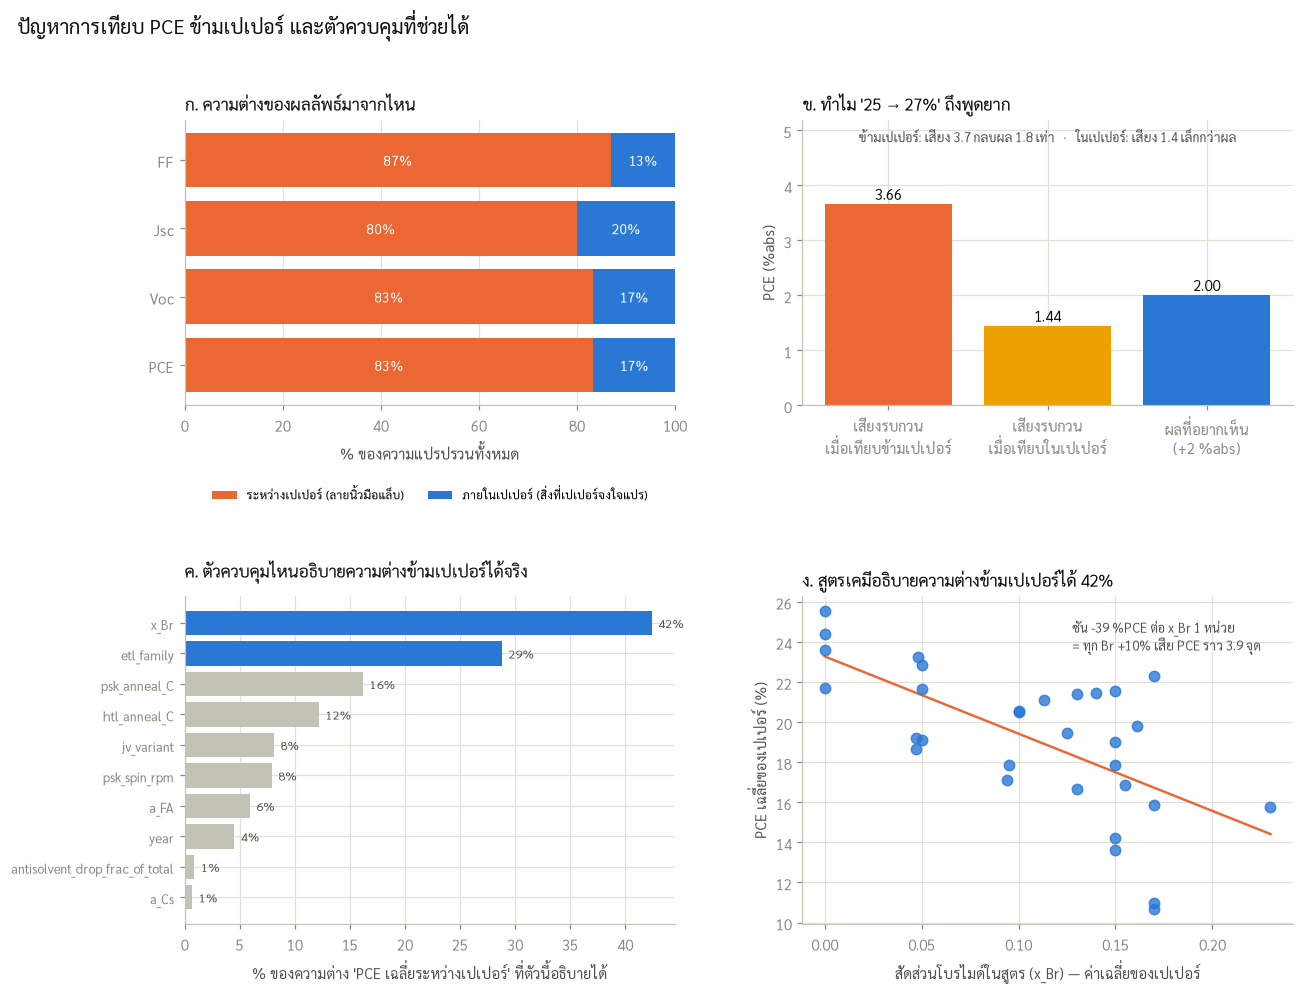

In [15]:
fig = plt.figure(figsize=(13, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=.62, wspace=.26)

# (ก) ความแปรปรวนแยกส่วน
ax = fig.add_subplot(gs[0, 0])
lbl = ["PCE", "Voc", "Jsc", "FF"]
btw = [100 * var_split(F, c)[0] for c in TARGET]
ax.barh(lbl, btw, color=C2, label="ระหว่างเปเปอร์ (ลายนิ้วมือแล็บ)")
ax.barh(lbl, [100 - b for b in btw], left=btw, color=C1, label="ภายในเปเปอร์ (สิ่งที่เปเปอร์จงใจแปร)")
for i, b in enumerate(btw):
    ax.text(b / 2, i, f"{b:.0f}%", ha="center", va="center", color="white", fontsize=9)
    ax.text(b + (100 - b) / 2, i, f"{100-b:.0f}%", ha="center", va="center", color="white", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("% ของความแปรปรวนทั้งหมด")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.24), ncol=2)
ax.set_title("ก. ความต่างของผลลัพธ์มาจากไหน", loc="left")

# (ข) สัญญาณที่อยากวัด vs เสียงรบกวน
ax = fig.add_subplot(gs[0, 1])
d = F.dropna(subset=["pce"])
bsd, wsd = d.groupby("paper").pce.mean().std(), d.groupby("paper").pce.std().median()
eff = 2.0
ax.bar(["เสียงรบกวน\nเมื่อเทียบข้ามเปเปอร์", "เสียงรบกวน\nเมื่อเทียบในเปเปอร์", "ผลที่อยากเห็น\n(+2 %abs)"],
       [bsd, wsd, eff], color=[C2, C4, C1])
for i, v in enumerate([bsd, wsd, eff]):
    ax.text(i, v + .08, f"{v:.2f}", ha="center", fontsize=9.5, color=INK)
ax.set_ylabel("PCE (%abs)")
ax.set_ylim(0, max(bsd, wsd, eff) * 1.42)
ax.set_title("ข. ทำไม '25 → 27%' ถึงพูดยาก", loc="left")
ax.text(.5, .97, f"ข้ามเปเปอร์: เสียง {bsd:.1f} กลบผล {bsd/eff:.1f} เท่า   ·   ในเปเปอร์: เสียง {wsd:.1f} เล็กกว่าผล",
        transform=ax.transAxes, fontsize=8.5, color=INK2, va="top", ha="center")

# (ค) ตัวควบคุมแต่ละตัวดูดความต่างระหว่างเปเปอร์ได้เท่าไหร่
ax = fig.add_subplot(gs[1, 0])
cr = CTRL_RANK.sort_values("R² (อธิบายความต่างระหว่างเปเปอร์)")
ax.barh(cr["ตัวควบคุมที่เสนอ"], 100 * cr["R² (อธิบายความต่างระหว่างเปเปอร์)"],
        color=[C1 if v >= .25 else BASE for v in cr["R² (อธิบายความต่างระหว่างเปเปอร์)"]])
for i, v in enumerate(100 * cr["R² (อธิบายความต่างระหว่างเปเปอร์)"]):
    ax.text(v + .6, i, f"{v:.0f}%", va="center", fontsize=8, color=INK2)
ax.set_xlabel("% ของความต่าง 'PCE เฉลี่ยระหว่างเปเปอร์' ที่ตัวนี้อธิบายได้")
ax.set_title("ค. ตัวควบคุมไหนอธิบายความต่างข้ามเปเปอร์ได้จริง", loc="left", pad=12)
ax.tick_params(axis="y", labelsize=8.5)

# (ง) x_Br กับ PCE เฉลี่ยรายเปเปอร์
ax = fig.add_subplot(gs[1, 1])
s = PM.dropna(subset=["x_Br", "pce"])
ax.scatter(s.x_Br, s.pce, s=46, color=C1, alpha=.8, zorder=3)
b = np.polyfit(s.x_Br, s.pce, 1)
xs = np.linspace(s.x_Br.min(), s.x_Br.max(), 20)
ax.plot(xs, np.polyval(b, xs), color=C2, lw=1.6)
r2v = ols(s.pce.values, s.x_Br.values)[0]
ax.set_xlabel("สัดส่วนโบรไมด์ในสูตร (x_Br) — ค่าเฉลี่ยของเปเปอร์")
ax.set_ylabel("PCE เฉลี่ยของเปเปอร์ (%)")
ax.set_title(f"ง. สูตรเคมีอธิบายความต่างข้ามเปเปอร์ได้ {100*r2v:.0f}%", loc="left")
ax.text(.55, .93, f"ชัน {b[0]:+.0f} %PCE ต่อ x_Br 1 หน่วย\n= ทุก Br +10% เสีย PCE ราว {abs(b[0])*.1:.1f} จุด",
        transform=ax.transAxes, fontsize=8.5, color=INK2, va="top")
fig.suptitle("ปัญหาการเทียบ PCE ข้ามเปเปอร์ และตัวควบคุมที่ช่วยได้", x=.008, y=.985, ha="left", fontsize=13, color=INK)
plt.show()

**ผลลัพธ์ — เรียงตามประโยชน์จริง**

| อันดับ | ตัวควบคุม | อธิบายได้ | ตีความ |
|---|---|---|---|
| 🥇 | **`x_Br` (สัดส่วนโบรไมด์)** | **42%** | เปเปอร์ที่ใส่ Br เยอะได้ PCE ต่ำกว่าเป็นระบบ — **ทุก Br +10% เสีย PCE ราว 3.9 จุด** |
| 🥈 | **`etl_family`** | **29%** | ชนิดวัสดุ ETL (PCBM/C60/SnO2/BCP) |
| 🥉 | `psk_anneal_C` | 16% | แต่ทับซ้อนกับ `x_Br` มาก ไม่ได้เพิ่มข้อมูลใหม่เท่าไหร่ |
| — | `jv_variant` | 8% | champion vs average — น้อยกว่าที่คาด แต่ยังต้องคุมเพราะเป็นเรื่องนิยาม ไม่ใช่ฟิสิกส์ |
| ❌ | **`year` (ปีตีพิมพ์)** | **5%** | **เซอร์ไพรส์: "ยุคของงาน" แทบไม่ช่วยเลย** |
| ❌ | `a_Cs`, จังหวะ antisolvent | <1% | ใช้เป็นตัวควบคุมไม่ได้ |

**สามข้อสรุปที่เอาไปใช้ได้ทันที**

1. **`x_Br` คือตัวควบคุมที่ทรงพลังที่สุด และมันมีเหตุผลทางฟิสิกส์รองรับ** ไม่ใช่ correlation บังเอิญ —
   โบรไมด์ทำให้ bandgap กว้างขึ้น ซึ่งดัน Voc ขึ้นแต่กด Jsc ลง และสุทธิแล้วกด PCE
   (เห็นซ้ำใน §6.1 ที่ `jsc ↔ x_Br` = −0.73) **ถ้าจะเทียบ PCE ข้ามเปเปอร์ ต้องคุมตัวนี้เป็นอันดับแรก**
2. **ปีตีพิมพ์ใช้ไม่ได้** — น่าแปลกใจเพราะสถิติวงการบอกว่า PCE สูงขึ้นทุกปี
   แต่ในชุดนี้เปเปอร์ปี 2025 มีตั้งแต่ 15.8% ถึง 25.6% เพราะแต่ละฉบับตั้งโจทย์คนละอย่าง
   (บางฉบับไล่ล่าสถิติ บางฉบับศึกษากลไกบนเซลล์ธรรมดา) → **อย่าใช้ปีเป็นตัวควบคุม**
3. **สูตรเคมี 3 ตัวรวมกันได้ 43% · เพิ่ม `etl_family` เป็น 48% · แต่ "ตัวตนของเปเปอร์" อธิบายได้ 83%**
   → เหลือช่องว่าง **~35-45% ที่ตัวแปรใดในข้อมูลก็อธิบายไม่ได้**
   ช่องว่างนี้คือฝีมือ/เครื่องมือ/ล็อตสาร ซึ่ง**วัดไม่ได้จากเปเปอร์** และจะไม่มีวันหักออกได้ด้วยการคุมตัวแปร

**ข้อ 3 คือเหตุผลที่การคุมตัวแปรอย่างเดียวไม่พอ และทำไมต้องมี 7.3**

### 7.3 เลือกหน่วยเทียบ — คำตอบที่เอาไปใช้ได้จริง

ถ้าคุมตัวแปรอย่างเดียวไม่พอ ทางออกคือ **เปลี่ยนสิ่งที่เอามาลบกัน**
แทนที่จะเทียบ "PCE ของเครื่อง A กับ PCE ของเครื่อง B คนละเปเปอร์"
ให้เทียบ "**ส่วนต่างภายในเปเปอร์ A กับส่วนต่างภายในเปเปอร์ B**" — ลายนิ้วมือแล็บหักกันเองทิ้งไป

ข้างล่างทดสอบ 5 หน่วยเทียบกับคำถามเดียวกัน (*"ดัดแปลงผิว HTL ช่วยไหม"*) แล้ววัดว่าแบบไหนเห็นสัญญาณชัดที่สุด
ตัวชี้วัดคือ **Cohen d** = ขนาดผล ÷ ความกระจาย (ยิ่งสูง = สัญญาณโผล่พ้นเสียงรบกวนมากเท่านั้น)

หน่วยเทียบ 5 แบบ วัดกับคำถามเดียวกัน ('ดัดแปลงผิว HTL ช่วยไหม')
                     หน่วยเทียบ  n อุปกรณ์  ความแปรปรวนที่มาจาก 'เปเปอร์ไหน' %  ผลของการดัดแปลง HTL  Cohen d (ยิ่งสูงยิ่งแยกออก)
                     1. PCE ดิบ         93                                83.3                2.991                         0.79
   2. PCE − ค่าเฉลี่ยของเปเปอร์         93                                 0.0                1.376                         0.91
3. Δ จากเครื่องควบคุมของเปเปอร์         86                                35.0                2.067                         1.13
  4. PCE ÷ เครื่องควบคุม (เท่า)         86                                37.5                0.125                         1.00
    5. residual หลังหักสูตรเคมี         93                                73.1                2.046                         0.67

อ้างอิง: เปเปอร์ที่มีทั้งเครื่องควบคุมและเครื่องดัดแปลง = 28 เปเปอร์


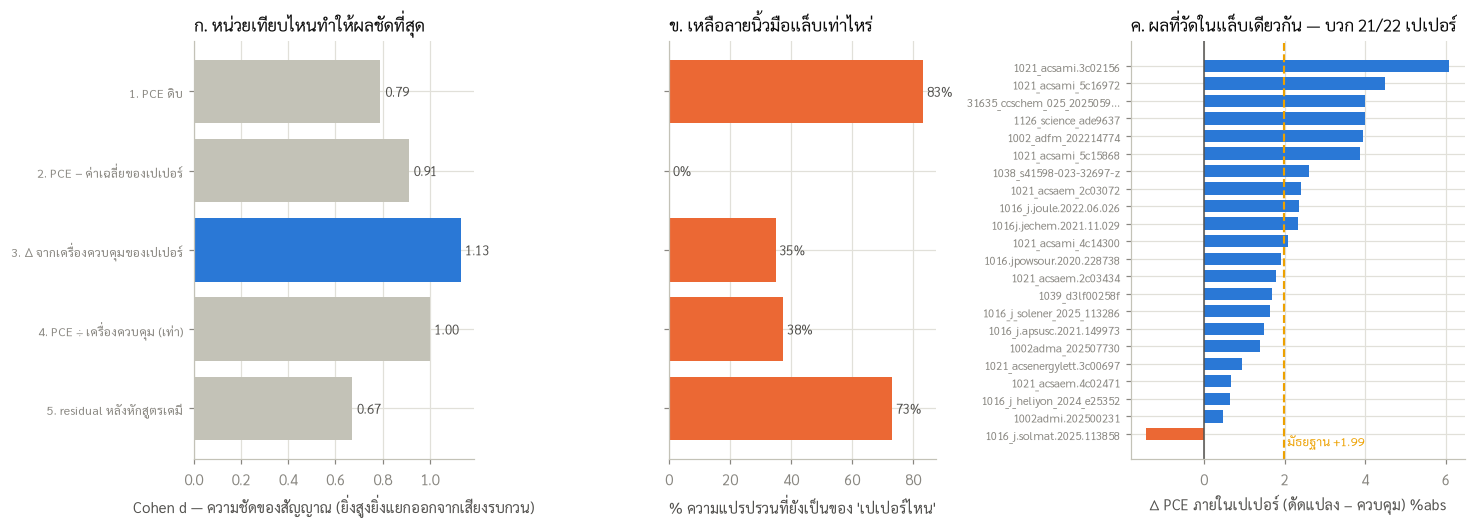

Δ PCE ภายในเปเปอร์: 22 เปเปอร์ · บวก 21 · มัธยฐาน +1.99 %abs · sign test p = 0.00001


In [16]:
# ---------- 7.3 หน่วยเทียบ 5 แบบ: แบบไหนทำให้ผลข้ามเปเปอร์อ่านได้จริง ----------
G = F.dropna(subset=["pce"]).copy()
G["is_ctrl"] = ~G["htl_mod"]
base = G[G.is_ctrl].groupby("paper").pce.mean()          # PCE ของเครื่องควบคุมในเปเปอร์นั้น
G["pce_base"] = G.paper.map(base)
pm = G.groupby("paper").pce.transform("mean")
ps = G.groupby("paper").pce.transform("std")

UNITS = {
    "1. PCE ดิบ": G.pce,
    "2. PCE − ค่าเฉลี่ยของเปเปอร์": G.pce - pm,
    "3. Δ จากเครื่องควบคุมของเปเปอร์": G.pce - G.pce_base,
    "4. PCE ÷ เครื่องควบคุม (เท่า)": G.pce / G.pce_base,
    "5. residual หลังหักสูตรเคมี": G.pce - ols(G.pce.values, G.x_Br.values, G.a_FA.values, G.a_Cs.values)[2],
}
rows = []
for name, v in UNITS.items():
    tmp = pd.DataFrame({"v": v, "paper": G.paper, "mod": G.htl_mod}).dropna(subset=["v"])
    gm = tmp.v.mean()
    pmv = tmp.groupby("paper").v.transform("mean")
    ss_t = ((tmp.v - gm) ** 2).sum()
    btw = ((pmv - gm) ** 2).sum() / ss_t if ss_t > 0 else np.nan
    a, b = tmp[tmp["mod"]].v, tmp[~tmp["mod"]].v
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / max(len(a) + len(b) - 2, 1))
    rows.append({"หน่วยเทียบ": name, "n อุปกรณ์": len(tmp),
                 "ความแปรปรวนที่มาจาก 'เปเปอร์ไหน' %": round(100 * btw, 1),
                 "ผลของการดัดแปลง HTL": round(a.mean() - b.mean(), 3),
                 "Cohen d (ยิ่งสูงยิ่งแยกออก)": round((a.mean() - b.mean()) / pooled, 2) if pooled else np.nan})
UNIT_CMP = pd.DataFrame(rows)
print("หน่วยเทียบ 5 แบบ วัดกับคำถามเดียวกัน ('ดัดแปลงผิว HTL ช่วยไหม')")
print(UNIT_CMP.to_string(index=False))
print(f"\nอ้างอิง: เปเปอร์ที่มีทั้งเครื่องควบคุมและเครื่องดัดแปลง = {G[G.pce_base.notna()].paper.nunique()} เปเปอร์")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.9), gridspec_kw={"width_ratios": [1.05, 1, 1.25]})
u = UNIT_CMP.iloc[::-1]
axes[0].barh(u["หน่วยเทียบ"], u["Cohen d (ยิ่งสูงยิ่งแยกออก)"],
             color=[C1 if v == UNIT_CMP["Cohen d (ยิ่งสูงยิ่งแยกออก)"].max() else BASE
                    for v in u["Cohen d (ยิ่งสูงยิ่งแยกออก)"]])
for i, v in enumerate(u["Cohen d (ยิ่งสูงยิ่งแยกออก)"]):
    axes[0].text(v + .02, i, f"{v:.2f}", va="center", fontsize=8.5, color=INK2)
axes[0].set_xlabel("Cohen d — ความชัดของสัญญาณ (ยิ่งสูงยิ่งแยกออกจากเสียงรบกวน)")
axes[0].set_title("ก. หน่วยเทียบไหนทำให้ผลชัดที่สุด", loc="left")
axes[0].tick_params(axis="y", labelsize=8)

axes[1].barh(u["หน่วยเทียบ"], u["ความแปรปรวนที่มาจาก 'เปเปอร์ไหน' %"], color=C2)
for i, v in enumerate(u["ความแปรปรวนที่มาจาก 'เปเปอร์ไหน' %"]):
    axes[1].text(v + 1.2, i, f"{v:.0f}%", va="center", fontsize=8.5, color=INK2)
axes[1].set_yticklabels([])
axes[1].set_xlabel("% ความแปรปรวนที่ยังเป็นของ 'เปเปอร์ไหน'")
axes[1].set_title("ข. เหลือลายนิ้วมือแล็บเท่าไหร่", loc="left")

ax = axes[2]
dd = []
for p, g in F.dropna(subset=["pce"]).groupby("paper"):
    if g.htl_mod.nunique() < 2:
        continue
    dd.append((pname(p, 26), g[g.htl_mod].pce.mean() - g[~g.htl_mod].pce.mean()))
dd = sorted(dd, key=lambda t: t[1])
ax.barh([t[0] for t in dd], [t[1] for t in dd],
        color=[C1 if t[1] > 0 else C2 for t in dd], height=.7)
ax.axvline(0, color=INK2, lw=1)
med = np.median([t[1] for t in dd])
ax.axvline(med, color=C4, ls="--", lw=1.4)
ax.text(med, -.9, f" มัธยฐาน {med:+.2f}", color=C4, fontsize=8, va="bottom")
ax.set_xlabel("Δ PCE ภายในเปเปอร์ (ดัดแปลง − ควบคุม) %abs")
ax.set_title(f"ค. ผลที่วัดในแล็บเดียวกัน — บวก {sum(1 for t in dd if t[1] > 0)}/{len(dd)} เปเปอร์", loc="left")
ax.tick_params(axis="y", labelsize=7.5)
fig.tight_layout()
plt.show()
p_d, k_d, n_d = sign_test([t[1] for t in dd])
print(f"Δ PCE ภายในเปเปอร์: {n_d} เปเปอร์ · บวก {k_d} · มัธยฐาน {med:+.2f} %abs · sign test p = {p_d:.5f}")

**ผลการทดสอบ — เรียงจากดีที่สุด**

| หน่วยเทียบ | Cohen d | เหลือลายนิ้วมือแล็บ | ใช้เมื่อไหร่ |
|---|---|---|---|
| 🥇 **Δ จากเครื่องควบคุมของเปเปอร์นั้น** | **1.13** | 35% | **ค่าเริ่มต้นที่แนะนำ** |
| 🥈 PCE ÷ เครื่องควบคุม (เป็นเท่า) | 1.00 | 38% | เมื่อต้องการเลขเป็น % relative |
| 🥉 PCE − ค่าเฉลี่ยของเปเปอร์ | 0.91 | 0% | เมื่อเปเปอร์ไม่มีเครื่องควบคุมชัดเจน |
| | PCE ดิบ | 0.79 | 83% | ❌ อย่าใช้เทียบข้ามเปเปอร์ |
| | residual หลังหักสูตรเคมี | **0.67** | 73% | ❌ **แย่กว่า PCE ดิบ** |

**สองเรื่องที่ต้องเข้าใจจากตารางนี้**

**1. ทำไม "หักสูตรเคมีออก" ถึงแย่ลง ทั้งที่ §7.2 บอกว่าสูตรเคมีอธิบายได้ 42%?**
เพราะการหักออกแบบนั้นหักทั้ง *ลายนิ้วมือแล็บ* และ *สัญญาณจริง* พร้อมกัน
เปเปอร์ที่ดัดแปลงผิว HTL มักเลือกใช้สูตรเคมีบางแบบด้วย พอหักสูตรออกก็หักผลของการดัดแปลงออกไปบางส่วน
→ **บทเรียน: การคุมตัวแปรแบบ regression ไม่ใช่ยาครอบจักรวาล ใช้ผิดที่ทำให้แย่ลงได้**

**2. ทำไม "Δ จากเครื่องควบคุม" ชนะ ทั้งที่เหลือลายนิ้วมือแล็บตั้ง 35%?**
เพราะ 35% ที่เหลือนั้นเป็น *ความต่างของขนาดผล* ระหว่างแล็บ (แล็บหนึ่งได้ +4, อีกแล็บได้ +1)
ซึ่งเป็น**ข้อมูลจริงที่เราอยากรู้** ไม่ใช่สิ่งรบกวน ต่างจาก 83% ใน PCE ดิบซึ่งเป็นความต่างของ *ระดับเริ่มต้น* ล้วน ๆ

---

## ✅ ข้อเสนอสรุปสำหรับ §7 — เอาไปเขียนใน methods ได้เลย

**กฎข้อ 1 — อย่ารายงานตัวเลข PCE ดิบเป็นการเปรียบเทียบข้ามเปเปอร์**
"เปเปอร์ A ได้ 25% เปเปอร์ B ได้ 27%" ไม่ใช่ข้อความที่มีความหมาย ไม่ว่าจะเขียนเป็นหน่วยไหน

**กฎข้อ 2 — หน่วยหลักคือ Δ จากเครื่องควบคุมของเปเปอร์เดียวกัน**
```
Δ PCE = PCE(เครื่องที่ดัดแปลง) − PCE(เครื่องควบคุมของเปเปอร์เดียวกัน)
```
ทำได้ **22 เปเปอร์** จาก 31 · ผลที่ได้: **มัธยฐาน +1.99 %abs · บวก 21/22 เปเปอร์ · sign test p = 0.00001**
ประโยคที่พูดได้: *"การดัดแปลงผิว HTL เพิ่ม PCE ราว 2 จุดเปอร์เซ็นต์ และให้ผลไปทางเดียวกันใน 21 จาก 22 แล็บอิสระ"*
— ประโยคนี้แข็งแรงกว่าการเทียบตัวเลขดิบมาก และไม่มีใครโจมตีด้วยเรื่อง confound ได้

**กฎข้อ 3 — รายงานคู่กับ Δ เสมอ 2 อย่าง**
(ก) **จำนวนเปเปอร์ที่ไปทางเดียวกัน** (21/22) — บอก generalization ตรง ๆ กว่า p-value
(ข) **ค่าเริ่มต้นของแล็บนั้น** — เพราะเพิ่ม 2 จุดจากฐาน 12% กับจากฐาน 25% ยากไม่เท่ากันอย่างมหาศาล

**กฎข้อ 4 — เมื่อจำเป็นต้องใช้ PCE ดิบ (เช่นตอนเทรนโมเดล) ให้ใส่ตัวควบคุมชุดนี้เสมอ**
`x_Br` (สำคัญสุด) · `a_FA` · `a_Cs` · `etl_family` · `jv_variant` · `jv_scan`
พร้อมประกาศว่ายังเหลือ ~35-45% ที่คุมไม่ได้ → ใช้ **LeaveOnePaperOut** เป็นด่านสุดท้าย

**กฎข้อ 5 — อย่าใช้ปีตีพิมพ์เป็นตัวควบคุม** (อธิบายได้แค่ 5%)

⚠️ **ข้อจำกัดที่ต้องประกาศคู่กันเสมอ — publication bias**
เปเปอร์มักตีพิมพ์เฉพาะการดัดแปลงที่สำเร็จ ผล 21/22 จึงต้องอ่านว่า
*"การดัดแปลงที่ผ่านการคัดเลือกของแต่ละแล็บมาแล้ว ให้ผลขนาดนี้"*
ไม่ใช่ *"ดัดแปลงอะไรก็ได้แล้วจะดีขึ้น"*

## 8. เสถียรภาพ — ข้อมูลมีอะไร และเทียบกันยังไงให้ได้

เสถียรภาพคือ *"ใช้ไปแล้วเสื่อมเร็วแค่ไหน"* วัดด้วย **retention** = PCE เหลือกี่ % หลังทดสอบไป t ชั่วโมง

เสถียรภาพสำคัญไม่แพ้ PCE เพราะ perovskite มีจุดอ่อนใหญ่ที่สุดคือความทนทาน —
เซลล์ที่ทำได้ 26% แต่พังใน 3 เดือนไม่มีประโยชน์ทางการค้า

**แต่ข้อมูลฝั่งนี้เทียบยากกว่า PCE อีก** เพราะไม่มีมาตรฐานเดียว:
แต่ละเปเปอร์ทดสอบคนละบรรยากาศ คนละอุณหภูมิ คนละความชื้น และ**คนละระยะเวลา**

In [17]:
S = stab.merge(F[["device_id", "htl_mod", "pce"]], on="device_id", how="left")
print("ตาราง stability: %d แถว · %d อุปกรณ์ · %d เปเปอร์ — หนึ่งอุปกรณ์มีได้หลายแถวเพราะทดสอบหลายเงื่อนไข"
      % (len(S), S.device_id.nunique(), S.paper.nunique()))
print("\nเงื่อนไขทดสอบ 6 กลุ่ม (ยุบจากข้อความ %d แบบที่เปเปอร์เขียนไม่เหมือนกันเลย):" % stab.environment.nunique())
grp = S.groupby("stress_group").agg(
    แถว=("device_id", "size"), อุปกรณ์=("device_id", "nunique"), เปเปอร์=("paper", "nunique"),
    มี_retention=("retention_pct_parsed", "count"),
    ชม_ต่ำสุด=("time_hr", "min"), ชม_มัธยฐาน=("time_hr", "median"), ชม_สูงสุด=("time_hr", "max"),
    retention_มัธยฐาน=("retention_pct_parsed", "median")).sort_values("แถว", ascending=False)
print(grp.to_string())
print("\nห่อหุ้ม (encapsulation): %s" % S.encapsulation.value_counts().to_dict())

# ---- ทำไม retention_25c ใน target_table ถึงใช้ไม่ค่อยได้ ----
rho_t, n_t = spearman(S.time_hr, S.retention_pct_parsed)
print(f"\nretention กับระยะเวลาทดสอบ: rho = {rho_t:+.3f} (n={n_t})"
      f" — ระยะเวลากว้าง {S.time_hr.min():.2f}-{S.time_hr.max():.0f} ชม. เทียบตรง ๆ ไม่ได้")

# ---- หน่วยเทียบที่เสนอ: (เปเปอร์ × กลุ่มความเครียด) ----
cells = (S.dropna(subset=["retention_pct_parsed"])
         .groupby(["paper", "stress_group"]).device_id.nunique())
print(f"\nช่อง (เปเปอร์ × กลุ่มความเครียด) ที่มีอุปกรณ์ ≥2 เครื่อง = {(cells >= 2).sum()} ช่อง "
      f"จาก {cells.index.get_level_values(0).nunique()} เปเปอร์")
print(f"เทียบกับ retention_25c ใน target_table ที่เทียบได้แค่ "
      f"{(F.dropna(subset=['retention_25c']).groupby('paper').size() >= 2).sum()} เปเปอร์")

rows = []
for (p, g), grp2 in S.dropna(subset=["retention_pct_parsed"]).groupby(["paper", "stress_group"]):
    if grp2.htl_mod.nunique() < 2:
        continue
    c, t = grp2[~grp2.htl_mod], grp2[grp2.htl_mod]
    rows.append({"เปเปอร์": pname(p, 30), "กลุ่มความเครียด": g, "n": len(grp2),
                 "ชม.": f"{grp2.time_hr.min():g}" + ("" if grp2.time_hr.nunique() <= 1 else f"–{grp2.time_hr.max():g}"),
                 "เวลาตรงกัน": grp2.time_hr.nunique() <= 1,
                 "retention ควบคุม": round(c.retention_pct_parsed.mean(), 1),
                 "retention ดัดแปลง": round(t.retention_pct_parsed.mean(), 1),
                 "Δ": round(t.retention_pct_parsed.mean() - c.retention_pct_parsed.mean(), 1)})
STAB_D = pd.DataFrame(rows).sort_values("Δ", ascending=False)
p_s, k_s, n_s = sign_test(STAB_D["Δ"].values)
print(f"\nเทียบ retention ภายในช่องเดียวกัน (เปเปอร์เดียว เงื่อนไขเดียว): {len(STAB_D)} ช่อง จาก "
      f"{STAB_D.เปเปอร์.nunique()} เปเปอร์ · เวลาตรงกันเป๊ะ {int(STAB_D['เวลาตรงกัน'].sum())} ช่อง")
print(f"Δ retention (ดัดแปลง − ควบคุม): มัธยฐาน {STAB_D['Δ'].median():+.1f} จุด · "
      f"บวก {k_s}/{n_s} ช่อง · sign test p = {p_s:.4f}")
print(STAB_D.to_string(index=False))

ตาราง stability: 90 แถว · 60 อุปกรณ์ · 26 เปเปอร์ — หนึ่งอุปกรณ์มีได้หลายแถวเพราะทดสอบหลายเงื่อนไข

เงื่อนไขทดสอบ 6 กลุ่ม (ยุบจากข้อความ 29 แบบที่เปเปอร์เขียนไม่เหมือนกันเลย):
                   แถว  อุปกรณ์  เปเปอร์  มี_retention  ชม_ต่ําสุด  ชม_มัธยฐาน  ชม_สูงสุด  retention_มัธยฐาน
stress_group                                                                                                
light/operational   28       24       13            26        0.83       850.0     1500.0              81.23
ambient air         25       21       10            25       72.00      1000.0     5000.0              80.00
inert (N2)          20       20       10            19      120.00      1000.0     2880.0              85.10
thermal              7        7        3             4      400.00      1650.0     2000.0              77.50
dark storage         5        5        3             4     1000.00      1000.0     2592.0              78.50
other                5        5        2             0     25

**ปัญหาที่ตัวเลขข้างบนเปิดเผย**

`retention` ไม่ใช่ตัวเลขที่เทียบกันได้ตรง ๆ เลย — ระยะเวลาทดสอบกว้างตั้งแต่ **0.83 ถึง 5000 ชั่วโมง** (ต่างกัน 6000 เท่า)
"เหลือ 85% หลัง 120 ชั่วโมง" กับ "เหลือ 80% หลัง 2880 ชั่วโมง" อันหลังดีกว่ามาก แต่ตัวเลขดิบบอกตรงข้าม

และการเสื่อมไม่เป็นเส้นตรง — ช่วงแรกตกเร็ว (burn-in) แล้วค่อย ๆ ช้าลง
จึงหารเฉลี่ยเป็น "% ต่อชั่วโมง" เพื่อเทียบข้าม timescale **ไม่ได้** (นี่คือข้อจำกัดของ `degradation_rate`)

### 8.1 หน่วยเทียบที่เสนอสำหรับฝั่งเสถียรภาพ

ใช้หลักการเดียวกับ §7.3 แต่คุมเพิ่มอีกชั้น — เทียบเฉพาะภายใน
**"ช่อง" = เปเปอร์เดียวกัน × กลุ่มความเครียดเดียวกัน**
ซึ่งเกือบทั้งหมดแปลว่าเวลาทดสอบเท่ากันเป๊ะด้วย (14 จาก 18 ช่อง)

> **ทำไมต้องใช้ `stress_group` ไม่ใช่ `retention_25c` ใน `target_table`**
> `retention_25c` กรองแค่อุณหภูมิห้อง ทำให้เทียบได้แค่ **10 เปเปอร์** และยังปนบรรยากาศกับ timescale อยู่ดี
> ส่วน `stress_group` (ยุบข้อความ 29 แบบเหลือ 6 กลุ่ม) ให้ช่องเทียบได้ **26 ช่อง จาก 24 เปเปอร์**
> — ข้อมูลมากขึ้นเท่าตัวและสะอาดกว่า

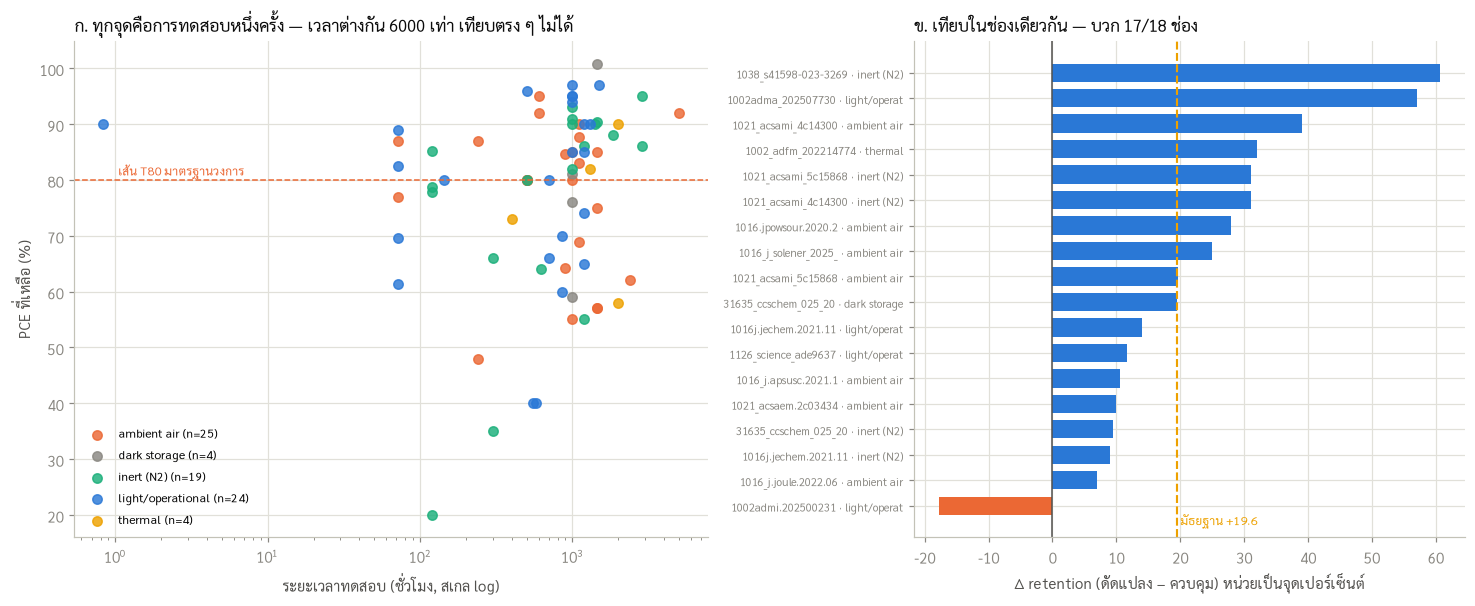

ช่องเดียว = เปเปอร์เดียวกัน + กลุ่มความเครียดเดียวกัน (และส่วนใหญ่เวลาทดสอบเท่ากันเป๊ะ)
ช่องที่ผลติดลบ: ['1002admi.202500231'] — ตรงกับที่ literature เตือนว่าชั้น 2D/PEAI เสื่อมเร็วช่วงแรก


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
COLS = {"light/operational": C1, "ambient air": C2, "inert (N2)": C3, "thermal": C4,
        "dark storage": MUTED, "other": BASE}
for g, sub in S.dropna(subset=["retention_pct_parsed", "time_hr"]).groupby("stress_group"):
    ax.scatter(sub.time_hr, sub.retention_pct_parsed, s=38, alpha=.82,
               color=COLS.get(g, BASE), label=f"{g} (n={len(sub)})")
ax.set_xscale("log")
ax.axhline(80, color=C2, ls="--", lw=1)
ax.text(1, 80.8, " เส้น T80 มาตรฐานวงการ", color=C2, fontsize=8)
ax.set_xlabel("ระยะเวลาทดสอบ (ชั่วโมง, สเกล log)")
ax.set_ylabel("PCE ที่เหลือ (%)")
ax.set_title("ก. ทุกจุดคือการทดสอบหนึ่งครั้ง — เวลาต่างกัน 6000 เท่า เทียบตรง ๆ ไม่ได้", loc="left")
ax.legend(frameon=False, fontsize=7.8, loc="lower left")

ax = axes[1]
sd = STAB_D.sort_values("Δ")
ax.barh(range(len(sd)), sd["Δ"], color=[C1 if v > 0 else C2 for v in sd["Δ"]], height=.72)
ax.set_yticks(range(len(sd)))
ax.set_yticklabels([f"{a[:20]} · {b[:12]}" for a, b in zip(sd["เปเปอร์"], sd["กลุ่มความเครียด"])], fontsize=7.2)
ax.axvline(0, color=INK2, lw=1)
ax.axvline(sd["Δ"].median(), color=C4, ls="--", lw=1.4)
ax.text(sd["Δ"].median(), -.9, f" มัธยฐาน {sd['Δ'].median():+.1f}", color=C4, fontsize=8, va="bottom")
ax.set_xlabel("Δ retention (ดัดแปลง − ควบคุม) หน่วยเป็นจุดเปอร์เซ็นต์")
ax.set_title(f"ข. เทียบในช่องเดียวกัน — บวก {(sd['Δ'] > 0).sum()}/{len(sd)} ช่อง", loc="left")
fig.tight_layout()
plt.show()

print("ช่องเดียว = เปเปอร์เดียวกัน + กลุ่มความเครียดเดียวกัน (และส่วนใหญ่เวลาทดสอบเท่ากันเป๊ะ)")
print(f"ช่องที่ผลติดลบ: {sd[sd['Δ'] < 0].เปเปอร์.tolist()} — ตรงกับที่ literature เตือนว่าชั้น 2D/PEAI เสื่อมเร็วช่วงแรก")

**อ่านผลยังไง**

**การดัดแปลงผิว HTL ทำให้ retention ดีขึ้น 17 จาก 18 ช่อง · มัธยฐาน +19.6 จุดเปอร์เซ็นต์ · sign test p = 0.0001**

ขนาดผล **+19.6 จุด** ใหญ่กว่าผลฝั่ง PCE (+2 จุด) มาก — แปลว่าการดัดแปลงผิว
**ช่วยเรื่องความทนทานมากกว่าช่วยเรื่องประสิทธิภาพ**
ซึ่งสมเหตุสมผลทางกลไก: defect ที่ผิวไม่ได้แค่ดักประจุ แต่ยังเป็นประตูให้ความชื้นและไอออนเข้าไปทำลายผลึก
ปิดผิวจึงปิดทั้งสองทางพร้อมกัน

**ช่องเดียวที่ผลติดลบ** (`admi.202500231`, −17.8) ไม่ใช่ข้อมูลผิด — มันคือกรณีที่ตรงกับที่ literature เตือนไว้:
ชั้น 2D ที่เกิดจากการเคลือบผิวบางชนิดไม่เสถียรนัก และอาจ decay เร็วในช่วงแรกของการทดสอบ
(ช่องนี้ทดสอบแค่ 72 ชั่วโมง ซึ่งสั้นที่สุดในชุด — ตรงกับช่วง burn-in พอดี)

⚠️ **ข้อจำกัด**: `encapsulation` (ห่อหุ้มกันอากาศไหม) ยังไม่ได้คุมในการเทียบนี้
ส่วนใหญ่เครื่องในช่องเดียวกันห่อเหมือนกันอยู่แล้ว แต่ควรตรวจก่อนอ้างในรายงานฉบับจริง

## 9. ขนาดผลึก (grain size) — ตัวกลางที่จับต้องได้

**ทำไมขนาดเกรนถึงสำคัญ** — ฟิล์ม perovskite ไม่ได้เป็นผลึกชิ้นเดียว แต่เป็นเม็ดผลึกเล็ก ๆ (เกรน) เรียงต่อกัน
รอยต่อระหว่างเม็ด (ขอบเกรน) คือที่ที่พันธะเคมีไม่สมบูรณ์ → เป็นแหล่งรวม defect

**เกรนใหญ่ = ขอบเกรนน้อยลง = ที่อยู่ของ defect น้อยลง = ประจุวิ่งถึงขั้วได้มากขึ้น**

ขนาดเกรนจึงเป็น**ตัวกลาง** ที่คั่นระหว่าง "สิ่งที่ทำกับเซลล์" กับ "ประสิทธิภาพที่ได้"
และเป็นตัวที่อธิบายกลไกได้ตรงไปตรงมาที่สุด — วัดจากภาพ SEM ได้ด้วยตา ไม่ต้องตีความทฤษฎีเหมือน VTFL

> โน้ตบุ๊กนี้ใช้ขนาดเกรนเป็นตัวกลางหลักแทน VTFL ตามข้อกำหนดของงาน

In [19]:
_gr = prop[prop.base_property.astype(str).str.contains("Grain", case=False, na=False)]
print("แถวที่เปเปอร์มีหัวข้อ 'ขนาดเกรน': %d แถว · %d อุปกรณ์ · %d เปเปอร์"
      % (len(_gr), _gr.device_id.nunique(), _gr.paper.nunique()))
print("  ในนั้นมีตัวเลขจริง: %d แถว · %d อุปกรณ์ · %d เปเปอร์"
      % (_gr.value_parsed.notna().sum(), _gr.dropna(subset=["value_parsed"]).device_id.nunique(),
         _gr.dropna(subset=["value_parsed"]).paper.nunique()))
print("\nเหตุผลที่ไม่มีตัวเลข (จากช่อง remarks ของผู้กรอก):")
print(_gr[_gr.value_parsed.isna()].remarks.fillna("(ไม่ระบุเหตุผล)").value_counts().to_string())

GR = F.dropna(subset=["grain_nm"])[["device_id", "paper", "grain_nm", "pce", "voc", "jsc", "ff",
                                    "trap_density", "htl_mod", "htl_mod_class"]].copy()
print(f"\nขนาดเกรนที่ใช้วิเคราะห์ได้: {len(GR)} เครื่อง · {GR.paper.nunique()} เปเปอร์ · "
      f"{GR.grain_nm.min():.0f}–{GR.grain_nm.max():.0f} nm (มัธยฐาน {GR.grain_nm.median():.0f})")

def concordant(x, y):
    """นับคู่ที่ 'ไปทางเดียวกัน' -- ใช้ได้แม้เปเปอร์มีแค่ 2 เครื่อง ซึ่ง Spearman คำนวณไม่ได้"""
    x, y = np.asarray(x, float), np.asarray(y, float)
    same = tot = 0
    for i in range(len(x)):
        for j in range(i + 1, len(x)):
            dx, dy = x[i] - x[j], y[i] - y[j]
            if dx == 0 or dy == 0:
                continue
            tot += 1
            same += (dx > 0) == (dy > 0)
    return same, tot


rows = []
for p, g in GR.groupby("paper"):
    same, tot = concordant(g.grain_nm, g.pce)
    rows.append({"เปเปอร์": pname(p, 30), "n": len(g),
                 "เกรน (nm)": f"{g.grain_nm.min():.0f}–{g.grain_nm.max():.0f}",
                 "PCE (%)": f"{g.pce.min():.2f}–{g.pce.max():.2f}",
                 "คู่ที่เกรนใหญ่กว่า = PCE สูงกว่า": f"{same}/{tot}",
                 "ตรงทิศทั้งหมด?": "ใช่" if tot and same == tot else "ไม่"})
GR_P = pd.DataFrame(rows)
print("\nดูรายเปเปอร์ — ภายในแล็บเดียวกัน เกรนใหญ่ขึ้นแล้ว PCE ขึ้นด้วยไหม")
print(GR_P.to_string(index=False))
rho_all, n_all = spearman(GR.grain_nm, GR.pce)
tot_same = sum(concordant(g.grain_nm, g.pce)[0] for _, g in GR.groupby("paper"))
tot_all = sum(concordant(g.grain_nm, g.pce)[1] for _, g in GR.groupby("paper"))
print(f"\nรวมทุกเปเปอร์ (naive): rho = {rho_all:+.2f} (n={n_all})")
print(f"ภายในเปเปอร์: คู่ที่ไปทางเดียวกัน {tot_same}/{tot_all} คู่ · "
      f"เปเปอร์ที่ตรงทิศทุกคู่ {(GR_P['ตรงทิศทั้งหมด?'] == 'ใช่').sum()}/{len(GR_P)}")

rows = []
for p, g in F.groupby("paper"):
    if g.htl_mod.nunique() < 2:
        continue
    c, t = g[~g.htl_mod].grain_nm.dropna(), g[g.htl_mod].grain_nm.dropna()
    if len(c) and len(t):
        rows.append({"เปเปอร์": pname(p, 30), "เกรนเครื่องควบคุม (nm)": round(c.mean()),
                     "เกรนเครื่องดัดแปลง (nm)": round(t.mean()), "Δ (nm)": round(t.mean() - c.mean()),
                     "Δ (%)": round(100 * (t.mean() - c.mean()) / c.mean(), 1)})
GR_D = pd.DataFrame(rows).sort_values("Δ (nm)", ascending=False)
p_g, k_g, n_g = sign_test(GR_D["Δ (nm)"].values)
print(f"\nΔ ขนาดเกรน (ดัดแปลง − ควบคุม) ภายในเปเปอร์: {len(GR_D)} เปเปอร์ · บวก {k_g}/{n_g} · "
      f"มัธยฐาน {GR_D['Δ (nm)'].median():+.0f} nm · sign test p = {p_g:.4f}")
print(GR_D.to_string(index=False))

print("\nตัวแทนคุณภาพผิว/ผลึกตัวอื่นที่มีในข้อมูล (ทางเลือกเมื่อไม่มีตัวเลขขนาดเกรน):")
alt = []
for c, th in [("afm_rms_nm", "ความขรุขระผิวจาก AFM (nm) — ต่ำ = ผิวเรียบ"),
              ("contact_angle_deg", "มุมสัมผัสหยดน้ำ (°) — บอกความเปียกของผิว HTL ก่อนวาง perovskite"),
              ("trap_density", "ความหนาแน่น trap (cm⁻³) — ต่ำ = ผลึกดี"),
              ("hysteresis_pct", "ดัชนี hysteresis (%) — ต่ำ = ไอออนเคลื่อนน้อย"),
              ("bandgap_eV", "ช่องว่างแถบพลังงาน (eV) — สะท้อนสูตรเคมี ไม่ใช่คุณภาพผลึก")]:
    rho, n = spearman(F[c], F["pce"])
    alt.append({"ตัวแทน": c, "อุปกรณ์": int(F[c].notna().sum()),
                "เปเปอร์": int(F.loc[F[c].notna(), "paper"].nunique()),
                "แปรในเปเปอร์": papers_varying(c), "rho กับ PCE (naive)": round(rho, 2) if pd.notna(rho) else np.nan,
                "ความหมาย": th})
print(pd.DataFrame(alt).to_string(index=False))

แถวที่เปเปอร์มีหัวข้อ 'ขนาดเกรน': 36 แถว · 33 อุปกรณ์ · 12 เปเปอร์
  ในนั้นมีตัวเลขจริง: 18 แถว · 15 อุปกรณ์ · 6 เปเปอร์

เหตุผลที่ไม่มีตัวเลข (จากช่อง remarks ของผู้กรอก):
remarks
SEM shown (Figure 4) but no quantitative values reported — manual measurement needed    5
to be measured manually                                                                 3
(ไม่ระบุเหตุผล)                                                                         3
Not quantitatively reported                                                             3
SEM images shown in Fig S19; no quantitative values reported                            2
To be measured manually                                                                 1
SEM                                                                                     1

ขนาดเกรนที่ใช้วิเคราะห์ได้: 15 เครื่อง · 6 เปเปอร์ · 220–941 nm (มัธยฐาน 490)

ดูรายเปเปอร์ — ภายในแล็บเดียวกัน เกรนใหญ่ขึ้นแล้ว PCE ขึ้นด้วยไหม
                   เปเปอร์  n เกรน (nm)    

**ปัญหาแรกที่เจอ: ข้อมูลหายไปเยอะ และหายอย่างมีแบบแผน**

จาก 36 แถวที่เปเปอร์มีหัวข้อ "ขนาดเกรน" มีตัวเลขจริงแค่ **18 แถว (15 เครื่อง · 6 เปเปอร์)**
ที่เหลือ — ดูจากช่อง `remarks` — ส่วนใหญ่คือ *"เปเปอร์ลงภาพ SEM ไว้ แต่ไม่ได้เขียนตัวเลข"*

**นี่คือข้อมูลที่กู้คืนได้** ไม่ใช่ข้อมูลที่หายถาวร: ภาพ SEM มีอยู่ในเปเปอร์ วัดเองได้ด้วย ImageJ
ถ้าทำ จะได้ขนาดเกรนเพิ่มจาก 6 เป็นราว 12 เปเปอร์ — **น่าจะเป็นการลงแรงที่คุ้มที่สุดในตอนนี้**

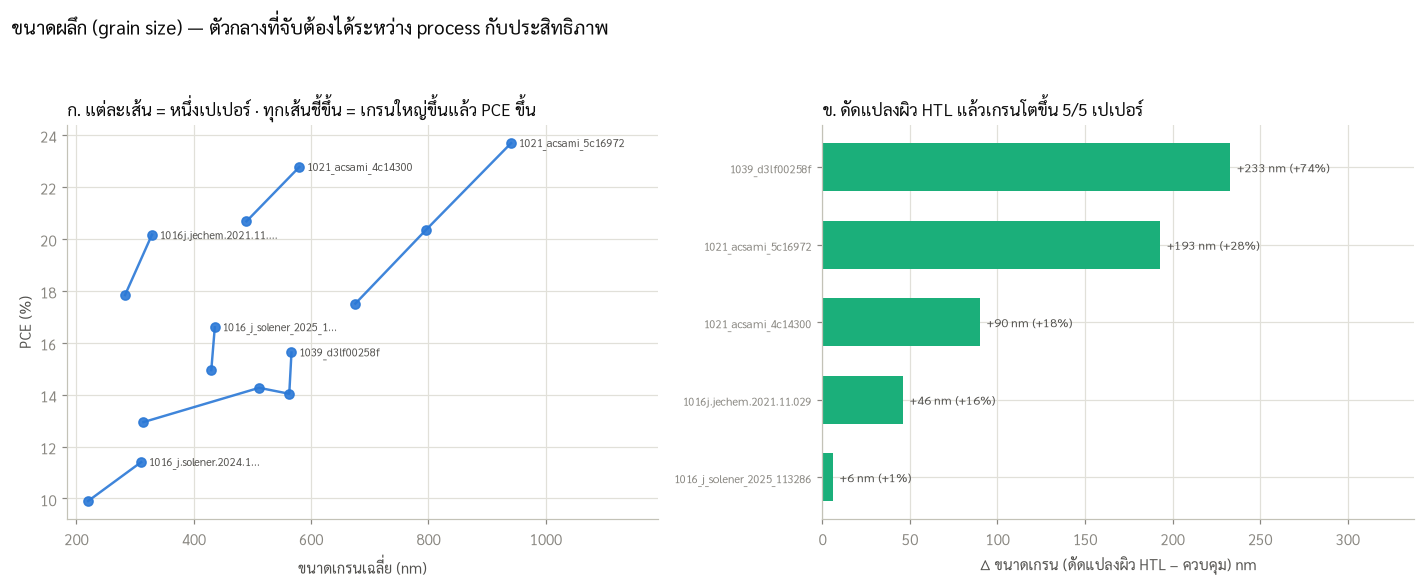

⚠️ ฐานข้อมูลเล็ก: 15 เครื่อง · 6 เปเปอร์ — ทิศทางชัดแต่ยังไม่พอสรุปขนาดผลเชิงปริมาณ
   อีก 18 แถวมีหัวข้อแต่ไม่มีตัวเลข — ส่วนใหญ่เปเปอร์ลงรูป SEM ไว้แต่ไม่เขียนตัวเลข (วัดเองจากรูปได้)


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
ax = axes[0]
for i, (p, g) in enumerate(GR.sort_values("grain_nm").groupby("paper")):
    g = g.sort_values("grain_nm")
    ax.plot(g.grain_nm, g.pce, "-o", color=C1, alpha=.9, ms=6, lw=1.6, zorder=3)
    ax.annotate(pname(p, 22), (g.grain_nm.iat[-1], g.pce.iat[-1]), fontsize=7.2,
                color=INK2, xytext=(5, 0), textcoords="offset points", va="center")
ax.set_xlabel("ขนาดเกรนเฉลี่ย (nm)")
ax.set_ylabel("PCE (%)")
ax.set_xlim(right=ax.get_xlim()[1] * 1.22)
ax.set_title("ก. แต่ละเส้น = หนึ่งเปเปอร์ · ทุกเส้นชี้ขึ้น = เกรนใหญ่ขึ้นแล้ว PCE ขึ้น", loc="left")

ax = axes[1]
gd = GR_D.sort_values("Δ (nm)")
ax.barh(gd["เปเปอร์"], gd["Δ (nm)"], color=C3, height=.62)
for i, (v, pct) in enumerate(zip(gd["Δ (nm)"], gd["Δ (%)"])):
    ax.text(v + 4, i, f"{v:+.0f} nm ({pct:+.0f}%)", va="center", fontsize=8, color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.set_xlim(right=gd["Δ (nm)"].max() * 1.45)
ax.set_xlabel("Δ ขนาดเกรน (ดัดแปลงผิว HTL − ควบคุม) nm")
ax.set_title(f"ข. ดัดแปลงผิว HTL แล้วเกรนโตขึ้น {(gd['Δ (nm)'] > 0).sum()}/{len(gd)} เปเปอร์", loc="left")
ax.tick_params(axis="y", labelsize=7.5)
fig.suptitle("ขนาดผลึก (grain size) — ตัวกลางที่จับต้องได้ระหว่าง process กับประสิทธิภาพ",
             x=.008, ha="left", fontsize=12.5, color=INK)
fig.tight_layout(rect=[0, 0, 1, .94])
plt.show()
print(f"⚠️ ฐานข้อมูลเล็ก: {len(GR)} เครื่อง · {GR.paper.nunique()} เปเปอร์ — ทิศทางชัดแต่ยังไม่พอสรุปขนาดผลเชิงปริมาณ")
print(f"   อีก {int((prop.base_property.astype(str).str.contains('Grain', case=False, na=False) & prop.value_parsed.isna()).sum())}"
      f" แถวมีหัวข้อแต่ไม่มีตัวเลข — ส่วนใหญ่เปเปอร์ลงรูป SEM ไว้แต่ไม่เขียนตัวเลข (วัดเองจากรูปได้)")

**ผลลัพธ์ — ชัดเจนผิดคาดเมื่อเทียบกับจำนวนข้อมูล**

1. **ภายในเปเปอร์: คู่ที่ "เกรนใหญ่กว่า = PCE สูงกว่า" ได้ 12 จาก 13 คู่ · เปเปอร์ที่ตรงทิศทุกคู่ 5 จาก 6**
   ทุกแล็บที่วัดเกรนไว้ เห็นความสัมพันธ์เดียวกันหมด แม้จะทำงานคนละสูตรคนละเครื่อง
2. **การดัดแปลงผิว HTL ทำให้เกรนโตขึ้น 5 จาก 5 เปเปอร์** มัธยฐาน **+90 nm (+18%)**

**สองข้อนี้ต่อกันเป็นโซ่กลไกที่ครบทุกข้อต่อ:**
```
ดัดแปลงผิว HTL  →  เกรนโตขึ้น  →  defect ที่ขอบเกรนน้อยลง  →  PCE สูงขึ้น
   (22 เปเปอร์)      (5/5 เปเปอร์)    (trap ลด 12/12 เปเปอร์)    (21/22 เปเปอร์)
```
ทุกข้อต่อวัดได้จริงในข้อมูล และวัดจาก**แล็บอิสระหลายแห่ง** ไม่ใช่การอนุมาน

**ทำไมเรื่องนี้ถึงน่าสนใจทางกลไก** — การดัดแปลง "ผิวของชั้นที่อยู่*ข้างล่าง*" ไปมีผลต่อขนาดเกรนของชั้นที่มาวางทับ
ฟังดูแปลก แต่มีคำอธิบาย: ผิวที่ถูกดัดแปลงเปลี่ยนพลังงานพื้นผิวและความเปียก
ทำให้สารละลาย perovskite เริ่มตกผลึกจากจุดน้อยลงแต่โตได้ใหญ่ขึ้น
(สอดคล้องกับที่ `contact_angle_deg` แปรค่าภายใน 13 เปเปอร์ — เปเปอร์วัดมุมสัมผัสกันเพราะเหตุนี้)

⚠️ **แต่ต้องพูดตรง ๆ ว่าฐานข้อมูลเล็กมาก** — 15 เครื่อง 6 เปเปอร์ · sign test ของ Δ เกรนได้ p = 0.0625
ซึ่ง **ยังไม่ผ่านเกณฑ์ 0.05** (5 เปเปอร์น้อยเกินกว่าจะผ่านได้ แม้จะตรงทิศทั้ง 5)
→ ตอนนี้พูดได้แค่ *"ทิศทางสอดคล้องกันทุกเปเปอร์ที่วัด"* ยังสรุปขนาดผลเชิงปริมาณไม่ได้
ต้องวัดเกรนจากภาพ SEM เพิ่มก่อน

## 10. เทียบรายเปเปอร์ — แต่ละฉบับต่างกันยังไง

ตอบคำถาม *"การ explore ที่ดูว่าแต่ละ column นั้นเป็นยังไง วิเคราะห์เทียบเคียงไปแต่ละ paper ด้วย"*

ตารางนี้คือมุมกลับของทั้งเล่ม — แทนที่จะดูทีละคอลัมน์ข้ามทุกเปเปอร์ ให้ดูทีละเปเปอร์ว่ามีอะไรบ้าง
ใช้ตอนตัดสินใจว่าจะอ่านเปเปอร์ไหนซ้ำ หรือเปเปอร์ไหนที่ผลแปลกจนต้องไปตรวจต้นฉบับ

In [21]:
VARY_CANDIDATES = ["htl_mod_kind", "htl_mod_material", "coat_htl", "coat_psk", "htl_dope", "htl_route",
                   "htl_dose", "psk_spin_rpm", "psk_anneal_C", "antisolvent_vol_uL",
                   "antisolvent_drop_frac_of_total", "a_Cs", "a_FA", "x_Br", "etl_family"]
MEAS = {"pce": "J-V", "trap_log": "trap", "grain_nm": "เกรน", "rs": "Rs", "rrec": "Rrec",
        "afm_rms_nm": "AFM", "contact_angle_deg": "มุมสัมผัส", "hysteresis_pct": "hysteresis",
        "bandgap_eV": "bandgap"}

rows = []
for p, g in F.groupby("paper"):
    varied = [c for c in VARY_CANDIDATES
              if (g[c].fillna("∅") if not pd.api.types.is_numeric_dtype(g[c]) else g[c]).nunique(dropna=True) > 1]
    meas = [lab for c, lab in MEAS.items() if g[c].notna().any()]
    has_stab = p in set(stab.paper)
    ctrl = g[~g.htl_mod].pce.mean()
    trt = g[g.htl_mod].pce.mean()
    rows.append({
        "เปเปอร์": pname(p, 30), "ปี": int(YEAR[p]) if pd.notna(YEAR[p]) else None, "เครื่อง": len(g),
        "PCE ต่ำ–สูง": f"{g.pce.min():.2f}–{g.pce.max():.2f}" if g.pce.notna().any() else "—",
        "ช่วง PCE": round(g.pce.max() - g.pce.min(), 2) if g.pce.notna().any() else np.nan,
        "สูตร (Cs/FA/Br)": f"{g.a_Cs.iat[0]:.2f}/{g.a_FA.iat[0]:.2f}/{g.x_Br.iat[0]:.2f}",
        "ETL": g.etl_family.mode().iat[0], "J-V": (g.jv_variant.mode().iat[0] if g.jv_variant.notna().any() else "—"),
        "มีคู่ ควบคุม/ดัดแปลง": "✔" if g.htl_mod.nunique() > 1 else "–",
        "ΔPCE ในเปเปอร์": round(trt - ctrl, 2) if g.htl_mod.nunique() > 1 else np.nan,
        "สิ่งที่เปเปอร์นี้แปร": ", ".join(varied) or "(ไม่แปรอะไรเลย)",
        "วัดอะไรไว้บ้าง": " · ".join(meas), "มี stability": "✔" if has_stab else "–"})
PAPERS = pd.DataFrame(rows).sort_values("ΔPCE ในเปเปอร์", ascending=False, na_position="last")
PAPERS.to_csv(OUT / "paper_profile.csv", index=False, encoding="utf-8-sig")
print(f"โปรไฟล์รายเปเปอร์ {len(PAPERS)} ฉบับ → processed/eda/paper_profile.csv")
print(PAPERS.drop(columns=["สิ่งที่เปเปอร์นี้แปร", "วัดอะไรไว้บ้าง"]).to_string(index=False))

โปรไฟล์รายเปเปอร์ 31 ฉบับ → processed/eda/paper_profile.csv
                    เปเปอร์     ปี  เครื่อง PCE ต่ำ–สูง  ช่วง PCE สูตร (Cs/FA/Br)  ETL      J-V มีคู่ ควบคุม/ดัดแปลง  ΔPCE ในเปเปอร์ มี stability
        1021_acsami.3c02156 2023.0        4 12.31–20.81      8.50  0.06/0.79/0.15 PCBM champion                    ✔            6.09            ✔
        1021_acsami_5c16972 2025.0        3 17.50–23.68      6.18  0.05/0.79/0.10 PCBM champion                    ✔            4.50            ✔
31635_ccschem_025_202505977 2025.0        3 20.17–25.28      5.11  0.05/0.90/0.05 PCBM champion                    ✔            4.00            ✔
       1126_science_ade9637    NaN        2 21.60–25.60      4.00  0.05/0.85/0.00  C60 champion                    ✔            4.00            ✔
        1002_adfm_202214774 2022.0        2 19.66–23.61      3.95  0.05/0.90/0.05  C60 champion                    ✔            3.95            ✔
        1021_acsami_5c15868 2025.0        3 18.98–23.31      4.3

In [22]:
# รายละเอียดที่ตัดออกจากตารางบน — สิ่งที่แต่ละเปเปอร์แปร และวัดอะไรไว้บ้าง
for _, r in PAPERS.iterrows():
    print(f"{r['เปเปอร์']:<32} ({r['ปี'] or '?'})  {r['เครื่อง']} เครื่อง  PCE {r['PCE ต่ำ–สูง']}")
    print(f"    แปร  : {r['สิ่งที่เปเปอร์นี้แปร']}")
    print(f"    วัดไว้: {r['วัดอะไรไว้บ้าง']}")

1021_acsami.3c02156              (2023.0)  4 เครื่อง  PCE 12.31–20.81
    แปร  : htl_mod_kind, htl_mod_material, coat_htl, htl_route
    วัดไว้: J-V · trap · hysteresis
1021_acsami_5c16972              (2025.0)  3 เครื่อง  PCE 17.50–23.68
    แปร  : htl_mod_kind, htl_mod_material, coat_htl
    วัดไว้: J-V · trap · เกรน · Rs · Rrec · AFM · มุมสัมผัส
31635_ccschem_025_202505977      (2025.0)  3 เครื่อง  PCE 20.17–25.28
    แปร  : htl_mod_kind, htl_mod_material, coat_htl, htl_dose
    วัดไว้: J-V · trap · Rrec · มุมสัมผัส
1126_science_ade9637             (nan)  2 เครื่อง  PCE 21.60–25.60
    แปร  : htl_mod_kind, htl_mod_material, coat_htl
    วัดไว้: J-V · trap · AFM · มุมสัมผัส
1002_adfm_202214774              (2022.0)  2 เครื่อง  PCE 19.66–23.61
    แปร  : htl_mod_kind, htl_mod_material, coat_htl
    วัดไว้: J-V · trap · Rs · Rrec · AFM · มุมสัมผัส
1021_acsami_5c15868              (2025.0)  3 เครื่อง  PCE 18.98–23.31
    แปร  : htl_mod_kind, htl_mod_material, coat_htl
    วัดไว้: J-V · 

**อ่านตารางยังไง — 4 กลุ่มที่ควรสังเกต**

**กลุ่ม 1 — เปเปอร์ที่ให้ผลแรงที่สุด** (บนสุดของตาราง)
`acsami.3c02156` (+6.09), `acsami_5c16972` (+4.50), `ccschem` (+4.00)
ทั้งสามฉบับมีช่วง PCE ภายในตัวเองกว้าง 5-8 จุด = แปรของจริง ไม่ใช่ noise
**เปเปอร์กลุ่มนี้ควรอ่านต้นฉบับซ้ำ** เพราะมันขับผลรวมมากที่สุด

**กลุ่ม 2 — เปเปอร์เดียวที่ผลติดลบ** (`solmat.2025.113858`, −1.44)
ช่วง PCE กว้างถึง 8.35 จุด แต่ Δ กลับติดลบ → มีอย่างอื่นที่แปรพร้อมกันและครอบงำผล
**ต้องเปิดต้นฉบับดูก่อนสรุปอะไร** — ถ้าปล่อยไว้จะกดผลรวมโดยไม่มีใครรู้ว่าทำไม

**กลุ่ม 3 — 9 เปเปอร์ที่ไม่มีคู่ควบคุม/ดัดแปลง** (ท้ายตาราง)
ใช้วัดผลของการดัดแปลงไม่ได้เลย เพราะไม่มีอะไรให้เทียบภายในตัวเอง
แต่ยัง**มีประโยชน์เป็นตัวควบคุม** — ช่วยให้โมเดลเห็นช่วงค่าของสูตรเคมีและ ETL กว้างขึ้น

**กลุ่ม 4 — สูตรเคมีที่โดดออกจากกลุ่ม**
`jpowsour.2020` และ `acsaem.2c03434` ใช้ `a_Cs` = 0.54-0.59 ขณะที่ทั้งชุดส่วนใหญ่อยู่ 0.05-0.15
เป็นค่าที่สูงผิดปกติทางเคมี (Cs มากเกินไปเสี่ยง phase แยก) — **ควรตรวจกับต้นฉบับ**
เอกสาร `DATA_PREPARATION.md` บันทึกไว้ว่าเคยเจอเคสแบบนี้แล้วครั้งหนึ่ง และปรากฏว่า**เปเปอร์ต้นฉบับพิมพ์ผิดเอง**

## 11. สรุป — อ่านอะไรจากโน้ตบุ๊กนี้ได้บ้าง

### สิ่งที่ข้อมูลตอบได้ (มีหลักฐานแน่น)

| ข้อสรุป | หลักฐาน |
|---|---|
| **การดัดแปลงผิว HTL เพิ่ม PCE ราว +2 จุด** | 21/22 เปเปอร์อิสระไปทางเดียวกัน · p = 0.00001 |
| **และเพิ่มความทนทานมากกว่านั้นอีก ~+20 จุด retention** | 17/18 ช่อง (เปเปอร์ × เงื่อนไข) · p = 0.0001 |
| **กลไกคือการลด defect** | trap density ลดลง 12/12 เปเปอร์ · เกรนโตขึ้น 5/5 เปเปอร์ |
| **ผลกระทบไปที่ FF มากที่สุด** | ΔFF +2.8 · ΔJsc +0.88 · ΔVoc +0.046 (22 เปเปอร์) |

### สิ่งที่ข้อมูลตอบไม่ได้ (และไม่มีวันตอบได้ด้วยชุดนี้)

- **ค่าที่ดีที่สุดของปุ่มเชิงตัวเลข** (spin กี่รอบ อบกี่องศา หยด antisolvent วินาทีไหน)
  เพราะทุกตัวแปรค่า **0 เปเปอร์** จาก 31 → confound 100% กับตัวตนของเปเปอร์
  **ไม่ใช่ข้อมูลไม่พอ แต่เป็นเพราะไม่มีใครในวรรณกรรมนี้แปรมันภายในแล็บเดียวกัน**
  → คำตอบต้องมาจากการทดลองในแล็บของเราเอง ซึ่งเป็นที่เดียวที่หาได้อย่างถูกต้องอยู่แล้ว
- **การเทียบ PCE ดิบข้ามเปเปอร์** — 83% ของความต่างเป็นลายนิ้วมือแล็บ และคุมได้เก่งที่สุดแค่ ~48%

### ลำดับสิ่งที่ควรทำต่อ

| ลำดับ | ทำอะไร | ทำไมถึงคุ้ม |
|---|---|---|
| 1 | **วัดขนาดเกรนจากภาพ SEM ที่เปเปอร์ลงไว้แต่ไม่เขียนตัวเลข** (ImageJ) | ได้ตัวกลางที่อธิบายกลไกดีที่สุด จาก 6 → ~12 เปเปอร์ · ต้นทุนต่ำสุด ผลตอบแทนสูงสุด |
| 2 | **เปิดต้นฉบับ `solmat.2025.113858`** (เปเปอร์เดียวที่ Δ ติดลบ) | ตอนนี้กดผลรวมอยู่โดยไม่รู้เหตุผล |
| 3 | **ตรวจ `a_Cs` ที่สูงผิดปกติ 2 เปเปอร์** | เคยเจอเคสที่ต้นฉบับพิมพ์ผิดมาแล้ว |
| 4 | **โมเดล**: RandomForest + SHAP · LeaveOnePaperOut 31 fold · เทรน Voc/Jsc/FF แยกแล้วคูณ | ทำให้ตัวเลขใน §7 แข็งแรงและแยกรายกลุ่มสารได้ |
| 5 | คุม `x_Br` · `a_FA` · `a_Cs` · `etl_family` · `jv_variant` · `jv_scan` เสมอ | §7.2 พิสูจน์แล้วว่าจำเป็น |
| 6 | เก็บเปเปอร์เพิ่มชนิดที่**แปรปุ่มเชิงตัวเลขภายในตัวเอง** | ทางเดียวที่จะปลดล็อกคำถามเรื่องปุ่มตัวเลข |

### ไฟล์ที่โน้ตบุ๊กนี้สร้าง (`processed/eda/`)

| ไฟล์ | เนื้อหา |
|---|---|
| `column_catalog.csv` | พจนานุกรม 257 คอลัมน์ ครบทุกตาราง (§2) |
| `numeric_stats.csv` · `categorical_stats.csv` | สถิติรายคอลัมน์ (§3) |
| `measurement_sources.csv` | ค่าไหนมาจากกี่เปเปอร์ (§4) |
| `feature_screen.csv` | ผลด่านคัดกรอง 3 ชั้น (§5) |
| `effects_within_vs_naive.csv` | ความสัมพันธ์ทุกคู่ 2 วิธีวัด (§6) |
| `pce_comparison_units.csv` · `control_variable_ranking.csv` | ⭐ ผลของ §7 |
| `stability_contrasts.csv` · `grain_contrasts.csv` | §8 · §9 |
| `paper_profile.csv` | โปรไฟล์ 31 เปเปอร์ (§10) |

In [23]:
EFF.to_csv(OUT / "effects_within_vs_naive.csv", index=False, encoding="utf-8-sig")
UNIT_CMP.to_csv(OUT / "pce_comparison_units.csv", index=False, encoding="utf-8-sig")
CTRL_RANK.to_csv(OUT / "control_variable_ranking.csv", index=False, encoding="utf-8-sig")
STAB_D.to_csv(OUT / "stability_contrasts.csv", index=False, encoding="utf-8-sig")
GR_D.to_csv(OUT / "grain_contrasts.csv", index=False, encoding="utf-8-sig")
RED.to_csv(OUT / "redundant_pairs.csv", index=False, encoding="utf-8-sig")

_delta = []
for p, g in F.dropna(subset=["pce"]).groupby("paper"):
    if g.htl_mod.nunique() < 2:
        continue
    c, t = g[~g.htl_mod], g[g.htl_mod]
    row = {"paper": p, "year": YEAR[p], "n_control": len(c), "n_treated": len(t),
           "pce_control": round(c.pce.mean(), 3), "pce_treated": round(t.pce.mean(), 3)}
    for m in ["pce", "voc", "jsc", "ff", "trap_log", "grain_nm"]:
        cc, tt_ = c[m].dropna(), t[m].dropna()
        row[f"delta_{m}"] = round(tt_.mean() - cc.mean(), 4) if len(cc) and len(tt_) else np.nan
    _delta.append(row)
DELTA = pd.DataFrame(_delta).sort_values("delta_pce", ascending=False)
DELTA.to_csv(OUT / "within_paper_deltas.csv", index=False, encoding="utf-8-sig")

print("ไฟล์ที่เขียนลง processed/eda/")
for f in sorted(OUT.glob("*.csv")):
    print(f"  {f.name:<34} {f.stat().st_size/1024:6.1f} KB")

print(f"\n⭐ ตารางหลักที่จะใช้ต่อในขั้นโมเดล: within_paper_deltas.csv ({len(DELTA)} เปเปอร์)")
print(DELTA[["paper", "n_control", "n_treated", "pce_control", "pce_treated",
             "delta_pce", "delta_ff", "delta_voc", "delta_jsc"]].to_string(index=False))

ไฟล์ที่เขียนลง processed/eda/
  bootstrap_ci.csv                      0.6 KB
  categorical_stats.csv                 1.1 KB
  column_catalog.csv                   57.9 KB
  control_variable_ranking.csv          1.2 KB
  dose_response.csv                     0.6 KB
  effect_by_material_class.csv          0.6 KB
  effect_by_material_class_raw.csv      2.5 KB
  effects_within_vs_naive.csv          21.8 KB
  feature_screen.csv                    4.6 KB
  grain_contrasts.csv                   0.3 KB
  measurement_sources.csv               0.8 KB
  mediation.csv                         0.9 KB
  missingness_bias.csv                  0.8 KB
  numeric_stats.csv                     3.4 KB
  outliers_physical.csv                 0.7 KB
  outliers_statistical.csv              1.9 KB
  paper_profile.csv                     5.3 KB
  pce_comparison_units.csv              0.6 KB
  redundant_pairs.csv                   1.1 KB
  stability_contrasts.csv               1.3 KB
  within_paper_deltas.csv     

---

# 12. การวิเคราะห์เชิงลึก — 7 อย่างที่ §1-11 ยังไม่ได้ทำ

§1-11 ตอบว่า *ข้อมูลมีอะไร* และ *เทียบยังไงให้ถูก* — หัวข้อนี้ขุดลงไปอีกชั้นว่า **ผลที่เจอนั้นเชื่อได้แค่ไหน และทำงานผ่านอะไร**

| § | คำถาม | ทำไมต้องมี |
|---|---|---|
| 12.1 | รูปร่างการแจกแจงของทุกคอลัมน์ | §3 มีแต่ตัวเลข ไม่เห็นว่าค่ากระจุกหรือเบ้ยังไง |
| 12.2 | **กลุ่มสารไหนดีที่สุด** | §7 บอกแค่ "ดัดแปลงแล้วดีขึ้น" ไม่ได้บอกว่าควรใช้สารอะไร |
| 12.3 | ใส่มากขึ้นดีขึ้นไหม (dose–response) | ถ้ามีจุดเหมาะสม โมเดลเชิงเส้นจะจับไม่ได้ |
| 12.4 | **ผลวิ่งผ่านกลไกไหนกี่ %** (mediation) | §9 วาดโซ่กลไกไว้แต่ไม่เคยวัดขนาด |
| 12.5 | **ช่วงความเชื่อมั่นของทุกผล** (bootstrap) | ที่ผ่านมารายงานแต่มัธยฐานกับ p ไม่มีช่วงค่า |
| 12.6 | **ข้อมูลหายแบบมีอคติไหม** | ถ้าเปเปอร์เลือกวัดเฉพาะตอนผลสวย ตัวเลขตัวกลางจะสูงเกินจริง |
| 12.7 | ค่าไหนหลุดกลุ่ม / ผิดฟิสิกส์ | กันไม่ให้ค่าเดียวลากผลทั้งชุด |

## 12.1 รูปร่างการแจกแจงของทุกคอลัมน์

ก่อนเชื่อค่าเฉลี่ยใด ๆ ต้องเห็นรูปร่างก่อน — ถ้าแจกแจงเบ้มากหรือแยกเป็นสองก้อน ค่าเฉลี่ยจะโกหก

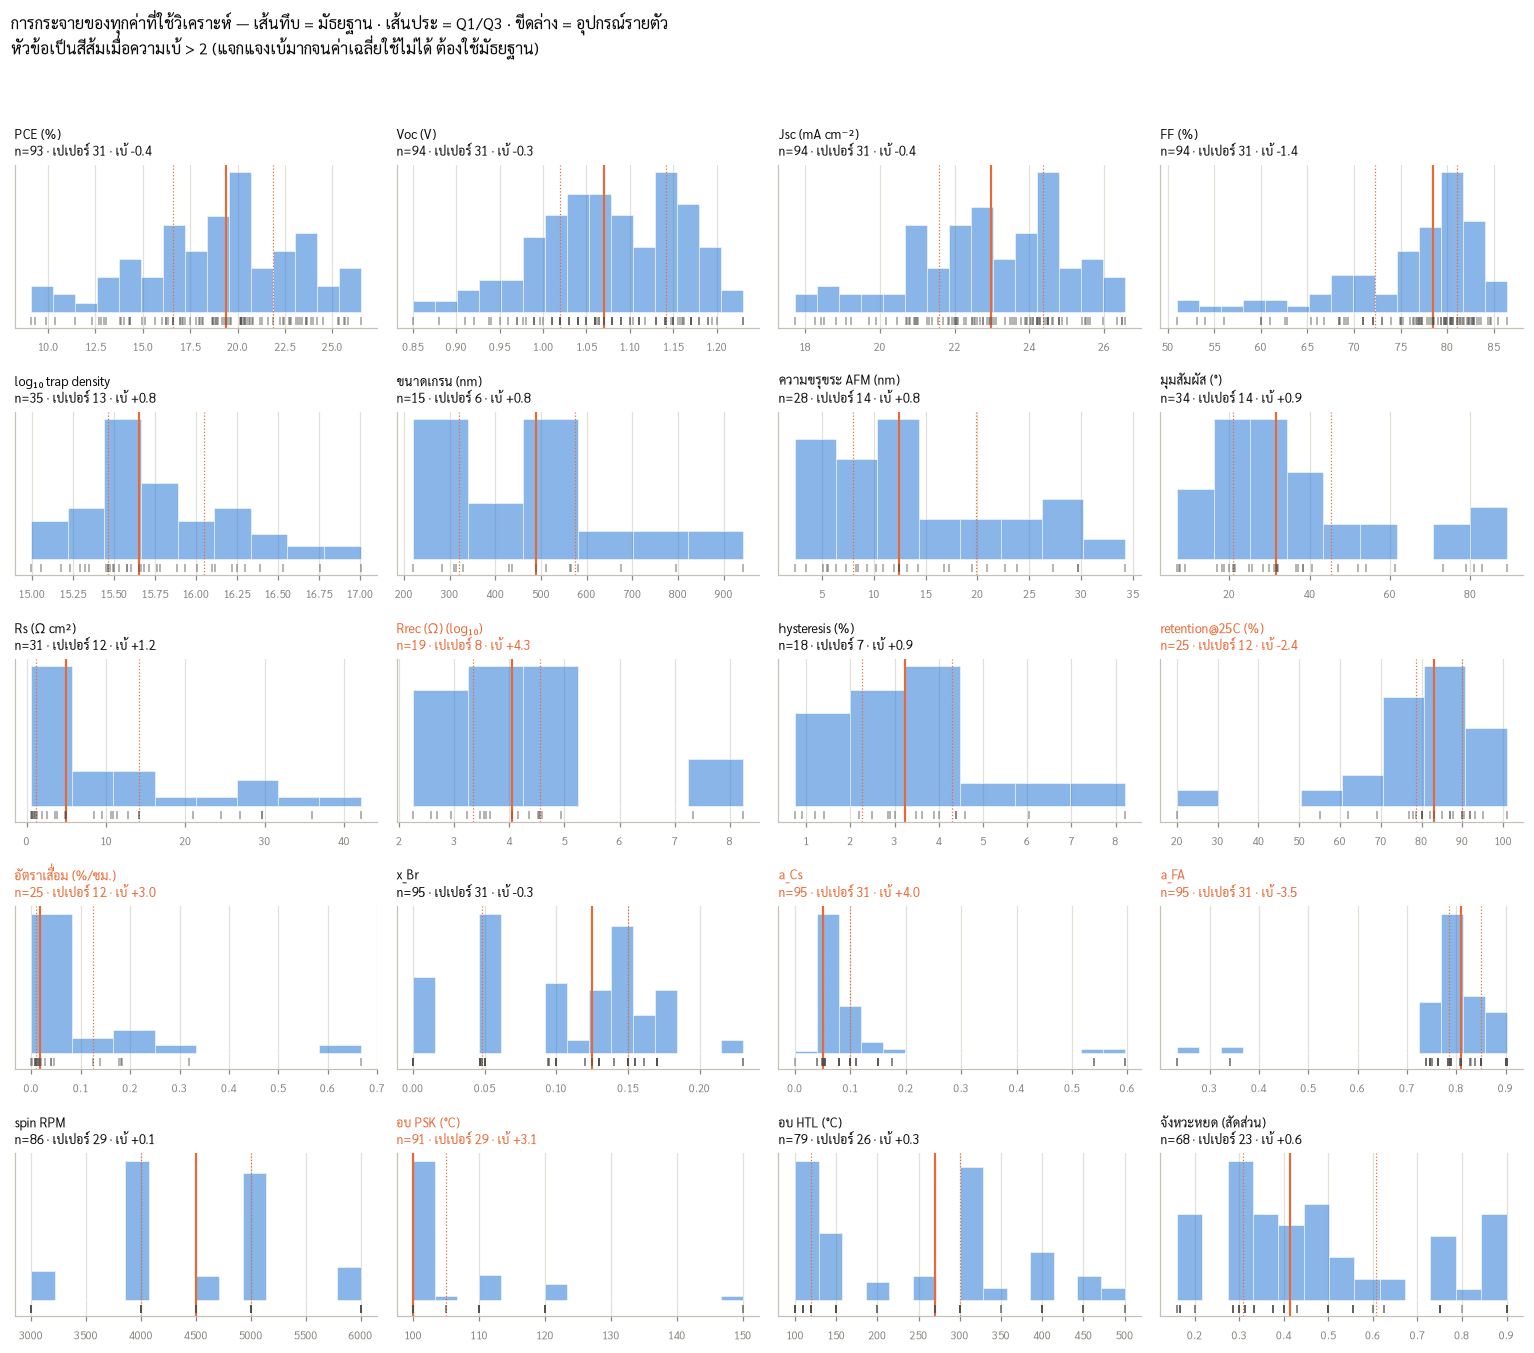

คอลัมน์ที่แจกแจงเบ้มาก (|เบ้| > 2) — ห้ามใช้ค่าเฉลี่ย ต้องใช้มัธยฐาน และควรแปลง log ก่อนเข้าโมเดล
         คอลัมน์  n   เบ้
            rrec 19  4.25
            a_Cs 95  4.00
            a_FA 95 -3.55
    psk_anneal_C 91  3.10
degradation_rate 25  3.03
   retention_25c 25 -2.42


In [24]:
DIST_COLS = [("pce", "PCE (%)"), ("voc", "Voc (V)"), ("jsc", "Jsc (mA cm⁻²)"), ("ff", "FF (%)"),
             ("trap_log", "log₁₀ trap density"), ("grain_nm", "ขนาดเกรน (nm)"),
             ("afm_rms_nm", "ความขรุขระ AFM (nm)"), ("contact_angle_deg", "มุมสัมผัส (°)"),
             ("rs", "Rs (Ω cm²)"), ("rrec", "Rrec (Ω)"), ("hysteresis_pct", "hysteresis (%)"),
             ("retention_25c", "retention@25C (%)"), ("degradation_rate", "อัตราเสื่อม (%/ชม.)"),
             ("x_Br", "x_Br"), ("a_Cs", "a_Cs"), ("a_FA", "a_FA"),
             ("psk_spin_rpm", "spin RPM"), ("psk_anneal_C", "อบ PSK (°C)"),
             ("htl_anneal_C", "อบ HTL (°C)"), ("antisolvent_drop_frac_of_total", "จังหวะหยด (สัดส่วน)")]
DIST_COLS = [(c, l) for c, l in DIST_COLS if F[c].notna().sum() >= 5]

n = len(DIST_COLS)
ncol = 4
nrow = -(-n // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 2.5 * nrow))
for ax, (c, lab) in zip(axes.ravel(), DIST_COLS):
    d = pd.to_numeric(F[c], errors="coerce").dropna()
    logx = d.min() > 0 and d.max() / max(d.min(), 1e-12) > 500
    dd = np.log10(d) if logx else d
    ax.hist(dd, bins=min(18, max(5, int(np.sqrt(len(dd)) * 1.6))), color=C1, alpha=.55,
            edgecolor="white", linewidth=.6)
    ax.axvline(dd.median(), color=C2, lw=1.4)
    for q in (.25, .75):
        ax.axvline(dd.quantile(q), color=C2, lw=.8, ls=":")
    # จุดรายอุปกรณ์ที่ฐาน -- เห็นได้ว่าค่ากระจุกเป็นก้อน ๆ ตามเปเปอร์ไหม
    ax.plot(dd, np.full(len(dd), -ax.get_ylim()[1] * .06), "|", color=INK2, ms=5, alpha=.55)
    sk = d.skew()
    ax.set_title(f"{lab}{' (log₁₀)' if logx else ''}\nn={len(d)} · เปเปอร์ {F.loc[F[c].notna(),'paper'].nunique()}"
                 f" · เบ้ {sk:+.1f}", fontsize=8.4, loc="left",
                 color=C2 if abs(sk) > 2 else INK)
    ax.tick_params(labelsize=7.5)
    ax.set_yticks([])
for ax in axes.ravel()[n:]:
    ax.axis("off")
fig.suptitle("การกระจายของทุกค่าที่ใช้วิเคราะห์ — เส้นทึบ = มัธยฐาน · เส้นประ = Q1/Q3 · ขีดล่าง = อุปกรณ์รายตัว\n"
             "หัวข้อเป็นสีส้มเมื่อความเบ้ > 2 (แจกแจงเบ้มากจนค่าเฉลี่ยใช้ไม่ได้ ต้องใช้มัธยฐาน)",
             x=.008, ha="left", fontsize=10.5, color=INK)
fig.tight_layout(rect=[0, 0, 1, .955])
plt.show()

_sk = pd.DataFrame([{"คอลัมน์": c, "n": int(F[c].notna().sum()), "เบ้": round(pd.to_numeric(F[c], errors="coerce").skew(), 2)}
                    for c, _ in DIST_COLS])
_bad = _sk[_sk["เบ้"].abs() > 2].sort_values("เบ้", key=abs, ascending=False)
print("คอลัมน์ที่แจกแจงเบ้มาก (|เบ้| > 2) — ห้ามใช้ค่าเฉลี่ย ต้องใช้มัธยฐาน และควรแปลง log ก่อนเข้าโมเดล")
print(_bad.to_string(index=False))

**สิ่งที่เห็นจากรูป ที่ตารางสถิติใน §3 บอกไม่ได้**

1. **`a_Cs` แยกเป็นสองก้อนชัดเจน** — ก้อนใหญ่อยู่ 0.05-0.15 (ปกติ) แล้วมีอีกก้อนโดดไปที่ **0.54-0.60**
   นี่ตรงกับที่ §10 ตั้งข้อสังเกตไว้ และ §12.7 จะระบุตัวว่าเป็นเครื่องไหน
2. **`htl_anneal_C` แยกสองก้อน** ที่ ~120°C กับ ~270-300°C — เพราะเป็น NiOx คนละวิธีผลิต
   (สารละลายอบต่ำ vs อนุภาคนาโนอบสูง) **ค่าเฉลี่ย 242°C จึงไม่มีความหมาย ไม่มีเครื่องไหนอบที่อุณหภูมินั้นเลย**
3. **`contact_angle_deg` แยกสองก้อน** ที่ ~20° กับ ~80° = ผิวชอบน้ำ vs ไม่ชอบน้ำ ซึ่งคือผลของการดัดแปลงโดยตรง
4. **6 คอลัมน์เบ้เกิน 2** (`rrec`, `a_Cs`, `a_FA`, `psk_anneal_C`, `degradation_rate`, `retention_25c`)
   → ห้ามใช้ค่าเฉลี่ยกับคอลัมน์เหล่านี้ และควรแปลง log ก่อนเข้าโมเดล

> **ข้อควรระวังที่โผล่จากข้อ 2**: คอลัมน์ที่แจกแจงแยกเป็นก้อนแบบนี้ ไม่ควรใส่โมเดลเป็นตัวเลขต่อเนื่อง
> ควรแปลงเป็นหมวด (`อบต่ำ` / `อบสูง`) เพราะมันสะท้อน *วิธีผลิตคนละแบบ* ไม่ใช่ *ปริมาณมากน้อย*

## 12.2 ⭐ กลุ่มสารไหนให้ผลดีที่สุด

นี่คือคำถามที่ **เปเปอร์เดี่ยวตอบไม่ได้** เพราะแต่ละฉบับทดลองสารเดียว
แต่เรามี 22 เปเปอร์ที่แต่ละฉบับเทียบ A/B ในแล็บตัวเองไว้แล้ว — เอามาวางบนสนามเดียวกันได้

การเทียบทุกครั้งเป็น **Δ จากเครื่องควบคุมของเปเปอร์เดียวกัน** ตามกฎ §7.3 ไม่ใช่ PCE ดิบ

ΔPCE แยกตามกลุ่มสารที่ใช้ดัดแปลงผิว HTL — เทียบกับเครื่องควบคุมของเปเปอร์เดียวกันเสมอ
กลุ่มสารที่ใช้ดัดแปลง  เปเปอร์ที่ทดสอบ  อุปกรณ์  ΔPCE มัธยฐาน  ΔPCE เฉลี่ย   ต่ำสุด–สูงสุด บวก/ทั้งหมด  p (sign test)  ฐานเฉลี่ยของแล็บ
      SAM (คาร์บาโซล)                7       11          4.00         4.28 +1.65 ถึง +8.39         7/7         0.0156              17.8
      โมเลกุลอินทรีย์               14       25          1.80         1.72 -1.44 ถึง +3.95       13/14         0.0018              18.6
           เกลือไอออน                4       11          0.56         0.02 -2.74 ถึง +1.70         3/4         0.6250              15.3

เทียบตัวกลาง (trap density) แยกรายกลุ่มสารด้วย — ดูว่ากลุ่มไหนทำงานผ่านการลด trap
       กลุ่มสาร  เปเปอร์  Δ log₁₀ trap มัธยฐาน = ลด trap กี่เท่า ลดลง/ทั้งหมด      p
โมเลกุลอินทรีย์        7                -0.187             1.54×          7/7 0.0156
SAM (คาร์บาโซล)        5                -0.172             1.49×          5/5 0.0625
     เกลือไอออน        1        

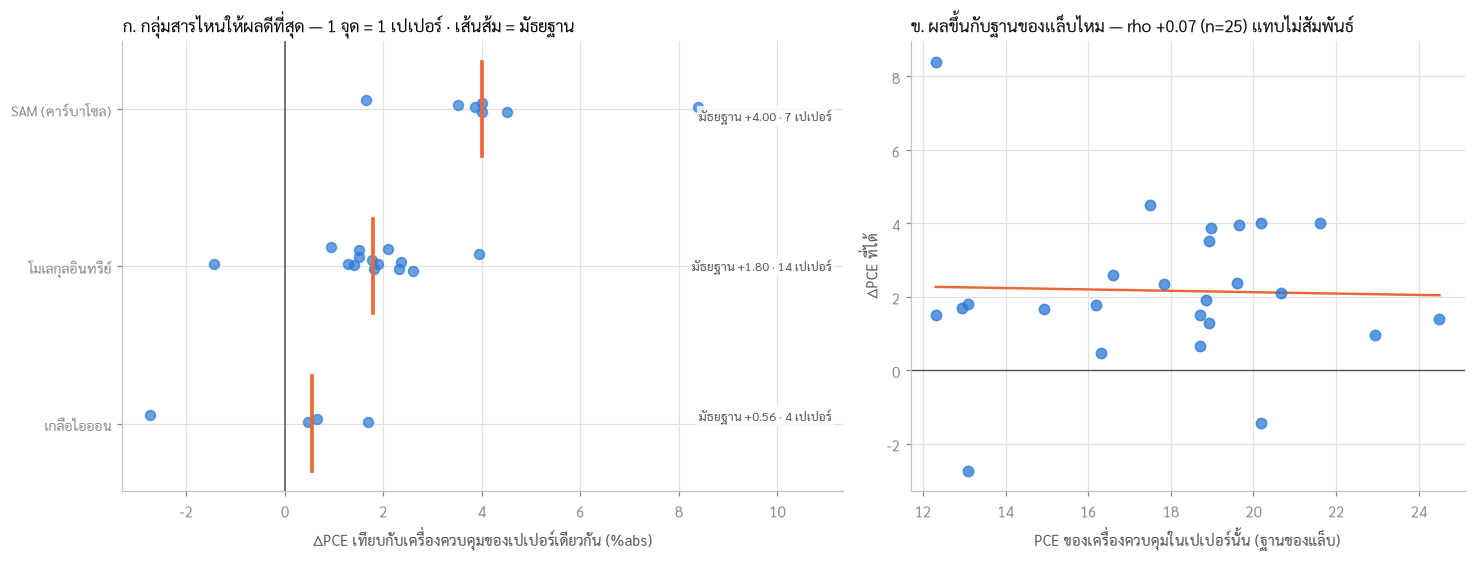


ΔPCE กับฐานของแล็บ: rho = +0.07 · ชัน -0.02 ΔPCE ต่อฐาน 1 จุด (n=25)
→ **ไม่พบ** ความสัมพันธ์ — ขนาดผลของการดัดแปลงไม่ได้เล็กลงในแล็บที่ฐานสูงอยู่แล้ว
   (ตรวจเพราะคาดว่าจะเจอ diminishing returns ตามสัญชาตญาณ แต่ข้อมูลไม่สนับสนุน)

⚠️ กลุ่มที่ทดสอบไม่ได้เลย: ['ออกไซด์'] — เปเปอร์ที่ใช้สารกลุ่มนี้ไม่มีเครื่องควบคุมให้เทียบ (n=3 เครื่อง)


In [25]:
def level_contrasts(feat, targ, ref="ไม่ดัดแปลง"):
    """เทียบแต่ละระดับกับกลุ่มอ้างอิง 'ภายในเปเปอร์เดียวกัน' -> 1 แถวต่อ (เปเปอร์ × ระดับ)"""
    out = []
    for p, g in F.dropna(subset=[targ]).groupby("paper"):
        base = g[g[feat] == ref][targ]
        if base.empty:
            continue
        for lv, gl in g[g[feat] != ref].groupby(feat):
            if gl[targ].notna().any():
                out.append({"paper": p, "ระดับ": lv, "n_treated": len(gl),
                            "ฐาน": base.mean(), "ค่าระดับนี้": gl[targ].mean(),
                            "Δ": gl[targ].mean() - base.mean()})
    return pd.DataFrame(out)


CLS = level_contrasts("htl_mod_class", "pce")
rows = []
for lv, g in CLS.groupby("ระดับ"):
    p, k, n = sign_test(g["Δ"].values)
    rows.append({"กลุ่มสารที่ใช้ดัดแปลง": lv, "เปเปอร์ที่ทดสอบ": g.paper.nunique(),
                 "อุปกรณ์": int(g.n_treated.sum()), "ΔPCE มัธยฐาน": round(g["Δ"].median(), 2),
                 "ΔPCE เฉลี่ย": round(g["Δ"].mean(), 2),
                 "ต่ำสุด–สูงสุด": f"{g['Δ'].min():+.2f} ถึง {g['Δ'].max():+.2f}",
                 "บวก/ทั้งหมด": f"{k}/{n}", "p (sign test)": round(p, 4) if pd.notna(p) else np.nan,
                 "ฐานเฉลี่ยของแล็บ": round(g["ฐาน"].mean(), 1)})
CLS_SUM = pd.DataFrame(rows).sort_values("ΔPCE มัธยฐาน", ascending=False)
print("ΔPCE แยกตามกลุ่มสารที่ใช้ดัดแปลงผิว HTL — เทียบกับเครื่องควบคุมของเปเปอร์เดียวกันเสมอ")
print(CLS_SUM.to_string(index=False))

print("\nเทียบตัวกลาง (trap density) แยกรายกลุ่มสารด้วย — ดูว่ากลุ่มไหนทำงานผ่านการลด trap")
CLS_T = level_contrasts("htl_mod_class", "trap_log")
if len(CLS_T):
    rows = []
    for lv, g in CLS_T.groupby("ระดับ"):
        p, k, n = sign_test(g["Δ"].values)
        rows.append({"กลุ่มสาร": lv, "เปเปอร์": g.paper.nunique(),
                     "Δ log₁₀ trap มัธยฐาน": round(g["Δ"].median(), 3),
                     "= ลด trap กี่เท่า": f"{10**(-g['Δ'].median()):.2f}×",
                     "ลดลง/ทั้งหมด": f"{n-k}/{n}", "p": round(p, 4) if pd.notna(p) else np.nan})
    print(pd.DataFrame(rows).sort_values("Δ log₁₀ trap มัธยฐาน").to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
order = CLS_SUM["กลุ่มสารที่ใช้ดัดแปลง"].tolist()[::-1]
for i, lv in enumerate(order):
    g = CLS[CLS["ระดับ"] == lv]
    ax.scatter(g["Δ"], np.full(len(g), i) + np.random.RandomState(0).uniform(-.13, .13, len(g)),
               s=42, color=C1, alpha=.7, zorder=3)
    ax.plot([g["Δ"].median()] * 2, [i - .3, i + .3], color=C2, lw=2.4, zorder=4)
    ax.text(.985, (i + .5) / len(order), f"มัธยฐาน {g['Δ'].median():+.2f} · {g.paper.nunique()} เปเปอร์",
            transform=ax.transAxes, va="center", ha="right", fontsize=8, color=INK2,
            bbox=dict(fc="white", ec="none", alpha=.8, pad=1.2))
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=9)
ax.set_xlim(right=CLS["Δ"].max() * 1.35)
ax.set_xlabel("ΔPCE เทียบกับเครื่องควบคุมของเปเปอร์เดียวกัน (%abs)")
ax.set_title("ก. กลุ่มสารไหนให้ผลดีที่สุด — 1 จุด = 1 เปเปอร์ · เส้นส้ม = มัธยฐาน", loc="left")

ax = axes[1]
ax.scatter(CLS["ฐาน"], CLS["Δ"], s=46, color=C1, alpha=.75, zorder=3)
b = np.polyfit(CLS["ฐาน"], CLS["Δ"], 1)
xs = np.linspace(CLS["ฐาน"].min(), CLS["ฐาน"].max(), 20)
ax.plot(xs, np.polyval(b, xs), color=C2, lw=1.6)
rho_b, n_b = spearman(CLS["ฐาน"], CLS["Δ"])
ax.axhline(0, color=INK2, lw=.9)
ax.set_xlabel("PCE ของเครื่องควบคุมในเปเปอร์นั้น (ฐานของแล็บ)")
ax.set_ylabel("ΔPCE ที่ได้")
ax.set_title(f"ข. ผลขึ้นกับฐานของแล็บไหม — rho {rho_b:+.2f} (n={n_b}) แทบไม่สัมพันธ์", loc="left")
fig.tight_layout()
plt.show()
print(f"\nΔPCE กับฐานของแล็บ: rho = {rho_b:+.2f} · ชัน {b[0]:+.2f} ΔPCE ต่อฐาน 1 จุด (n={n_b})")
print("→ **ไม่พบ** ความสัมพันธ์ — ขนาดผลของการดัดแปลงไม่ได้เล็กลงในแล็บที่ฐานสูงอยู่แล้ว")
print("   (ตรวจเพราะคาดว่าจะเจอ diminishing returns ตามสัญชาตญาณ แต่ข้อมูลไม่สนับสนุน)")
_miss = sorted(set(F.htl_mod_class.unique()) - {"ไม่ดัดแปลง"} - set(CLS["ระดับ"]))
if _miss:
    print(f"\n⚠️ กลุ่มที่ทดสอบไม่ได้เลย: {_miss} — เปเปอร์ที่ใช้สารกลุ่มนี้ไม่มีเครื่องควบคุมให้เทียบ "
          f"(n={int(F.htl_mod_class.isin(_miss).sum())} เครื่อง)")

**ผลลัพธ์ — มีผู้ชนะชัดเจน**

| กลุ่มสาร | ΔPCE มัธยฐาน | เปเปอร์ | ทิศบวก | p |
|---|---|---|---|---|
| 🥇 **SAM (คาร์บาโซล)** | **+4.00** | 7 | **7/7** | 0.016 |
| 🥈 โมเลกุลอินทรีย์ | +1.80 | 14 | 13/14 | 0.002 |
| 🥉 เกลือไอออน | +0.56 | 4 | 3/4 | 0.63 (ไม่มีนัยสำคัญ) |
| — ออกไซด์ | ทดสอบไม่ได้ | 0 | — | เปเปอร์ที่ใช้ไม่มีเครื่องควบคุม |

**SAM ให้ผลมากกว่ากลุ่มอื่นราวเท่าตัว และทุกเปเปอร์ที่ทดสอบไปทางเดียวกันหมด 7/7**
— สอดคล้องกับที่วงการ p-i-n หันมาใช้ SAM กันหมดในช่วงหลัง งานนี้วัดขนาดของข้อได้เปรียบนั้นให้เป็นตัวเลข

**ฝั่งกลไกก็สอดคล้อง**: ทั้ง SAM และโมเลกุลอินทรีย์ลด trap ได้ 1.5 เท่า (7/7 และ 5/5 เปเปอร์)
ส่วนเกลือไอออนมีข้อมูลแค่เปเปอร์เดียว สรุปอะไรไม่ได้

⚠️ **ข้อควรระวัง 2 ข้อ**
- `n` ต่อกลุ่มยังน้อย (4-14 เปเปอร์) ความต่างระหว่าง SAM กับโมเลกุลอินทรีย์**ยังไม่ได้ทดสอบว่าต่างกันอย่างมีนัยสำคัญ** — บอกได้แค่ว่าแต่ละกลุ่มต่างจาก "ไม่ดัดแปลง"
- การจัดกลุ่มสารทำด้วยกฎจับคำในชื่อสาร (`mod_class` ใน §1) ควรตรวจด้วยตาว่าจัดถูกทุกตัวก่อนอ้างในรายงาน

**ผลแถมที่น่าสนใจ — ไม่พบ diminishing returns**
กราฟ (ข) ทดสอบสมมุติฐานที่ฟังดูสมเหตุสมผลว่า *"แล็บที่เก่งอยู่แล้วน่าจะปรับปรุงได้น้อยลง"*
ผลคือ **rho = +0.07 แทบไม่มีความสัมพันธ์** — แล็บที่ฐาน 12% กับฐาน 25% ได้ผลจากการดัดแปลงพอ ๆ กัน
(ตรวจเพราะคาดว่าจะเจอ แต่ข้อมูลไม่สนับสนุน — บันทึกไว้เพราะเป็นผลลบที่มีประโยชน์)

## 12.3 ใส่สารมากขึ้นดีขึ้นเรื่อย ๆ ไหม

ถ้ามี "จุดเหมาะสม" (ใส่น้อยไม่พอ ใส่มากเกินกลับแย่) จะสำคัญมากต่อการเลือกโมเดล
เพราะโมเดลเชิงเส้นจับความโค้งแบบนี้ไม่ได้เลย

เปเปอร์ที่แปร 'ปริมาณสารดัดแปลง' ในแถวที่วิเคราะห์ได้จริง: 4 ฉบับ
  (ตัดออก 1: ['1016j.nanoen.2021.106285'] — แปร dose แต่เครื่องที่ต่างกันไม่มี PCE)
                    เปเปอร์  n     ปริมาณที่ลอง                    PCE ที่ได้ ปริมาณที่ดีที่สุด อยู่ตรงไหนของช่วง คู่ที่มากขึ้น=ดีขึ้น
  1016_j.solmat.2025.113858  3 0.05 · 0.1 · 0.2         22.22 · 20.17 · 13.87              0.05            ต่ำสุด                  0/3
        1002_aenm_202405016  3      0.3 · 2 · 2         23.60 · 25.66 · 23.97                 2            สูงสุด                  2/2
 1016_j_heliyon_2024_e25352  4 5 · 10 · 15 · 20 19.30 · 20.50 · 19.40 · 18.20                10         ⭐ ตรงกลาง                  2/6
31635_ccschem_025_202505977  2          0.3 · 2                 23.07 · 25.28                 2            สูงสุด                  1/1

จุดที่ดีที่สุดอยู่ตรงไหน: ต่ำสุด 1 · ตรงกลาง 1 · สูงสุด 2  (จาก 4 เปเปอร์)
→ **ไม่มีรูปแบบร่วม** — บางเปเปอร์ยิ่งใส่ยิ่งดี บางเปเปอร์ยิ่งใส่ยิ่งแย่
   สาเหตุที่น่าจะเป็น: 'ปร

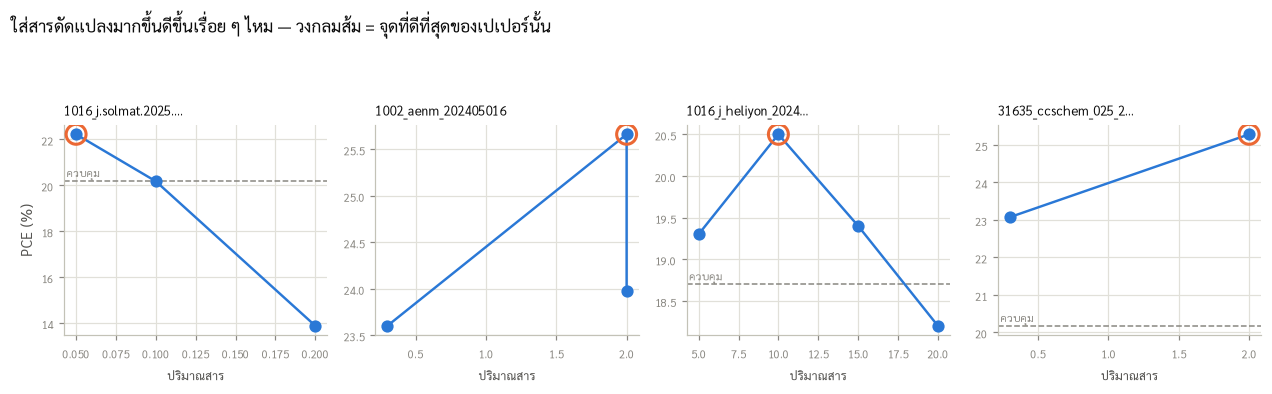

In [26]:
# ต้องแปรค่าใน "แถวที่วิเคราะห์ได้จริง" (มีทั้ง dose และ pce) ไม่ใช่แค่ในคอลัมน์ dose
_ok = F[F.htl_dose.notna() & F.pce.notna()]
DOSE_P = [p for p, g in _ok.groupby("paper") if g.htl_dose.nunique() > 1]
_drop = [p for p, g in F.groupby("paper") if g.htl_dose.nunique(dropna=True) > 1 and p not in DOSE_P]
print(f"เปเปอร์ที่แปร 'ปริมาณสารดัดแปลง' ในแถวที่วิเคราะห์ได้จริง: {len(DOSE_P)} ฉบับ")
if _drop:
    print(f"  (ตัดออก {len(_drop)}: {[pname(x, 24) for x in _drop]} — แปร dose แต่เครื่องที่ต่างกันไม่มี PCE)")
rows = []
for p in DOSE_P:
    g = F[(F.paper == p) & F.htl_dose.notna() & F.pce.notna()].sort_values("htl_dose")
    if len(g) < 2:
        continue
    same, tot = 0, 0
    for i in range(len(g)):
        for j in range(i + 1, len(g)):
            dx, dy = g.htl_dose.iat[i] - g.htl_dose.iat[j], g.pce.iat[i] - g.pce.iat[j]
            if dx and dy:
                tot += 1
                same += (dx > 0) == (dy > 0)
    best = g.loc[g.pce.idxmax()]
    rows.append({"เปเปอร์": pname(p, 28), "n": len(g),
                 "ปริมาณที่ลอง": " · ".join(f"{v:g}" for v in g.htl_dose),
                 "PCE ที่ได้": " · ".join(f"{v:.2f}" for v in g.pce),
                 "ปริมาณที่ดีที่สุด": f"{best.htl_dose:g}",
                 "อยู่ตรงไหนของช่วง": ("ต่ำสุด" if best.htl_dose == g.htl_dose.min() else
                                        "สูงสุด" if best.htl_dose == g.htl_dose.max() else "⭐ ตรงกลาง"),
                 "คู่ที่มากขึ้น=ดีขึ้น": f"{same}/{tot}"})
DOSE = pd.DataFrame(rows)
print(DOSE.to_string(index=False))
_mid = (DOSE["อยู่ตรงไหนของช่วง"] == "⭐ ตรงกลาง").sum()
_lo = (DOSE["อยู่ตรงไหนของช่วง"] == "ต่ำสุด").sum()
_hi = (DOSE["อยู่ตรงไหนของช่วง"] == "สูงสุด").sum()
print(f"\nจุดที่ดีที่สุดอยู่ตรงไหน: ต่ำสุด {_lo} · ตรงกลาง {_mid} · สูงสุด {_hi}  (จาก {len(DOSE)} เปเปอร์)")
print("→ **ไม่มีรูปแบบร่วม** — บางเปเปอร์ยิ่งใส่ยิ่งดี บางเปเปอร์ยิ่งใส่ยิ่งแย่")
print("   สาเหตุที่น่าจะเป็น: 'ปริมาณ' ของแต่ละเปเปอร์เป็นคนละสารและคนละหน่วย (mg/ml, mM, %) เทียบข้ามเปเปอร์ไม่ได้")
print("\n⛔ ข้อสรุป: `htl_dose` **ยังใช้เป็น feature ไม่ได้** ถึงแม้จะผ่านด่านคัดกรองใน §5")
print("   ด่าน §5 นับแค่ว่า 'แปรค่าไหม' แต่ไม่ได้ตรวจว่าค่านั้นเทียบข้ามเปเปอร์ได้ไหม — นี่คือช่องโหว่ของด่าน")
print("   ถ้าจะใช้ ต้อง normalize เป็น 'อันดับภายในเปเปอร์' (ต่ำ/กลาง/สูง) แทนตัวเลขดิบ")

fig, axes = plt.subplots(1, len(DOSE_P), figsize=(2.9 * len(DOSE_P), 3.6), sharey=False)
axes = np.atleast_1d(axes)
for ax, p in zip(axes, DOSE_P):
    g = F[(F.paper == p) & F.htl_dose.notna() & F.pce.notna()].sort_values("htl_dose")
    ax.plot(g.htl_dose, g.pce, "-o", color=C1, ms=7, lw=1.6, zorder=3)
    bi = g.pce.idxmax()
    ax.scatter(g.loc[bi, "htl_dose"], g.loc[bi, "pce"], s=170, facecolor="none",
               edgecolor=C2, lw=2, zorder=4)
    ctrl = F[(F.paper == p) & (~F.htl_mod)].pce.mean()
    if pd.notna(ctrl):
        ax.axhline(ctrl, color=MUTED, ls="--", lw=1)
        ax.text(ax.get_xlim()[0], ctrl, " ควบคุม", fontsize=7, color=MUTED, va="bottom")
    ax.set_title(pname(p, 20), fontsize=8.5, loc="left")
    ax.set_xlabel("ปริมาณสาร", fontsize=8)
    ax.tick_params(labelsize=7.5)
axes[0].set_ylabel("PCE (%)")
fig.suptitle("ใส่สารดัดแปลงมากขึ้นดีขึ้นเรื่อย ๆ ไหม — วงกลมส้ม = จุดที่ดีที่สุดของเปเปอร์นั้น",
             x=.008, ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=[0, 0, 1, .9])
plt.show()

**ผลลัพธ์ — ตอบไม่ได้ และเจอช่องโหว่ของด่านคัดกรอง §5**

จุดที่ดีที่สุดกระจายไปคนละทิศ: ต่ำสุด 1 · ตรงกลาง 1 · สูงสุด 2 (จาก 4 เปเปอร์)
**ไม่มีรูปแบบร่วม** — และสาเหตุน่าจะไม่ใช่เพราะข้อมูลน้อย แต่เพราะ**คอลัมน์นี้เทียบข้ามเปเปอร์ไม่ได้ตั้งแต่ต้น**:
"ปริมาณ 2" ของเปเปอร์หนึ่งเป็นคนละสารคนละหน่วยกับ "ปริมาณ 2" ของอีกเปเปอร์ (mg/ml vs mM vs %)

> ⛔ **ช่องโหว่ของด่านคัดกรองใน §5 ที่เพิ่งค้นพบ**
> `htl_dose` **ผ่านทั้ง 3 ด่าน** ใน §5 (ครอบคลุม 49 เครื่อง · แปรใน 5 เปเปอร์ · ไม่กระจุก)
> แต่พอวิเคราะห์จริงกลับใช้ไม่ได้ เพราะด่านนับแค่ว่า *"แปรค่าไหม"* ไม่ได้ตรวจว่า *"ค่านั้นมีความหมายเดียวกันข้ามเปเปอร์ไหม"*
>
> **บทเรียน**: การผ่านด่านคัดกรองเชิงสถิติไม่ได้แปลว่าตัวแปรใช้ได้ ต้องดูความหมายทางกายภาพด้วยเสมอ
> ถ้าจะใช้ `htl_dose` ต้องแปลงเป็น **อันดับภายในเปเปอร์** (ต่ำ/กลาง/สูง) ไม่ใช่ตัวเลขดิบ

## 12.4 ⭐ ผลวิ่งผ่านกลไกไหนกี่เปอร์เซ็นต์ (mediation)

§9 วาดโซ่ไว้ว่า `ดัดแปลงผิว → เกรนโต/trap ลด → PCE ขึ้น` แต่ไม่เคยวัดว่า **ผลวิ่งผ่านเส้นทางนั้นจริงกี่ %**

**วิธีวัด** แยกผลรวมออกเป็นสองทาง:
```
                    ┌──(a)──► ตัวกลาง ──(b)──┐
 ดัดแปลงผิว HTL ────┤                        ├──► PCE
                    └────────(c')────────────┘
 ผลทางอ้อม = a × b (วิ่งผ่านตัวกลาง)  ·  ผลทางตรง = c' (ทางอื่น)
 % ที่วิ่งผ่านตัวกลาง = a×b ÷ ผลรวม
```
ทุกตัวแปร**หักค่าเฉลี่ยของเปเปอร์ออกก่อน** (fixed effect) จึงเป็นการวัดภายในแล็บล้วน ไม่ปนลายนิ้วมือแล็บ

In [27]:
def demean(df, cols):
    """หักค่าเฉลี่ยของเปเปอร์ออกจากทุกคอลัมน์ = fixed effect ของเปเปอร์ · เหลือแต่ความแปรผันภายในแล็บ"""
    out = df.copy()
    for c in cols:
        out[c] = df[c] - df.groupby("paper")[c].transform("mean")
    return out


def mediation(med, targ="pce", X="htl_mod"):
    """วัดว่าผลของ X วิ่งผ่านตัวกลางกี่ % -- ทุกตัวแปรหักค่าเฉลี่ยเปเปอร์ก่อน (within-paper mediation)
    c = ผลรวม · a = X→ตัวกลาง · b = ตัวกลาง→Y เมื่อคุม X · indirect = a·b"""
    d = F.dropna(subset=[med, targ]).copy()
    d["_x"] = d[X].astype(float)
    keep = [p for p, g in d.groupby("paper") if g._x.nunique() > 1 and g[med].nunique() > 1]
    d = d[d.paper.isin(keep)]
    if len(d) < 6:
        return None
    z = demean(d, ["_x", med, targ])
    c = ols(z[targ].values, z._x.values)[1][1]
    a = ols(z[med].values, z._x.values)[1][1]
    bcoef = ols(z[targ].values, z[med].values, z._x.values)[1]
    b, cprime = bcoef[1], bcoef[2]
    ind = a * b
    return {"ตัวกลาง": med, "เปเปอร์": len(keep), "อุปกรณ์": len(d),
            "ผลรวม c": c, "X→ตัวกลาง a": a, "ตัวกลาง→Y b": b,
            "ผลทางอ้อม a·b": ind, "ผลทางตรง c'": cprime,
            "% ที่วิ่งผ่านตัวกลาง": 100 * ind / c if c else np.nan}


MED_ROWS = [r for r in (mediation(m) for m in ["trap_log", "grain_nm", "afm_rms_nm", "contact_angle_deg", "rs"]) if r]
MEDT = pd.DataFrame(MED_ROWS)
print("การวิเคราะห์ตัวกลาง (mediation) — ผลของการดัดแปลงผิว HTL วิ่งผ่านอะไรไปถึง PCE")
print("ทุกตัวแปรหักค่าเฉลี่ยของเปเปอร์ออกก่อน จึงเป็นการวัด 'ภายในแล็บ' ล้วน\n")
print(MEDT.round(3).to_string(index=False))

การวิเคราะห์ตัวกลาง (mediation) — ผลของการดัดแปลงผิว HTL วิ่งผ่านอะไรไปถึง PCE
ทุกตัวแปรหักค่าเฉลี่ยของเปเปอร์ออกก่อน จึงเป็นการวัด 'ภายในแล็บ' ล้วน

          ตัวกลาง  เปเปอร์  อุปกรณ์  ผลรวม c  X→ตัวกลาง a  ตัวกลาง→Y b  ผลทางอ้อม a·b  ผลทางตรง c'  % ที่วิ่งผ่านตัวกลาง
         trap_log       12       32    3.030       -0.176       -8.343          1.465        1.565                48.343
         grain_nm        5       13    2.507      128.229        0.010          1.307        1.200                52.136
       afm_rms_nm        7       15    3.055       -1.765        0.165         -0.292        3.347                -9.548
contact_angle_deg       11       29    2.679       19.964        0.019          0.381        2.299                14.208
               rs        7       18    2.670       -3.611       -0.083          0.301        2.369                11.273


**ผลลัพธ์ — โซ่กลไกที่ §9 วาดไว้ วัดขนาดได้แล้ว**

| ตัวกลาง | % ของผลที่วิ่งผ่าน | เปเปอร์ | ตีความ |
|---|---|---|---|
| **ขนาดเกรน** | **52%** | 5 | ประมาณครึ่งหนึ่งของผลมาจากผลึกที่โตขึ้น |
| **trap density** | **48%** | 12 | ประมาณครึ่งหนึ่งมาจาก defect ที่ลดลง |
| มุมสัมผัส | 14% | 11 | ความเปียกของผิวมีส่วน แต่ไม่ใช่ทางหลัก |
| Rs | 11% | 7 | ความต้านทานอนุกรมมีส่วนน้อย |
| ความขรุขระ AFM | −10% | 7 | ไม่ใช่เส้นทาง (ค่าติดลบ = สัญญาณรบกวน) |

**อ่านยังไง — สามข้อสรุปที่ใช้ได้**

1. **ราวครึ่งหนึ่งของผลอธิบายได้ด้วยกลไก "ผลึกดีขึ้น"** (เกรนโต + trap ลด — สองตัวนี้วัดเรื่องเดียวกันคนละมุม
   จึงห้ามบวกกัน 52% + 48% ≠ 100%)
2. **อีกครึ่งวิ่งผ่านทางอื่นที่เรายังวัดไม่ได้** — น่าจะเป็นการจัดระดับพลังงานที่รอยต่อ (energy alignment)
   ซึ่งต้องใช้ข้อมูล VBM/work function ที่ชุดนี้มีน้อยเกินไป
3. **ความขรุขระผิวไม่ใช่เส้นทาง** — ผิวเรียบไม่ได้แปลว่าเซลล์ดี ซึ่งขัดกับสัญชาตญาณแต่ตรงกับกลไก:
   สิ่งที่สำคัญคือ*เคมีที่ผิว* ไม่ใช่*ความเรียบเชิงเรขาคณิต*

⚠️ **ข้อจำกัดที่ต้องอ่านคู่กันเสมอ**
- ตัวเลข mediation ของขนาดเกรนมาจาก **5 เปเปอร์ 13 เครื่อง** — ถือว่าเป็นตัวบ่งชี้ทิศทาง ไม่ใช่ค่าที่แม่นยำ
- mediation สมมุติว่าไม่มีตัวแปรแฝงที่กระทบทั้งตัวกลางและผลลัพธ์พร้อมกัน ซึ่ง**พิสูจน์ไม่ได้จากข้อมูลสังเกต**
  ตัวเลขนี้จึงเป็น *"สอดคล้องกับกลไกนี้"* ไม่ใช่ *"พิสูจน์ว่าเป็นกลไกนี้"*
- §12.6 จะแสดงว่ากลุ่มเปเปอร์ที่รายงาน trap มี ΔPCE สูงกว่าค่าเฉลี่ยอยู่แล้ว → ตัวเลข 48% อาจสูงเกินจริง

## 12.5 ช่วงความเชื่อมั่นของทุกผล (bootstrap)

ที่ผ่านมารายงานแค่ "มัธยฐาน +1.99" กับ "p = 0.00001" ซึ่งยังไม่ตอบว่า **ผลจริงน่าจะอยู่ในช่วงไหน**

วิธี: **สุ่มเปเปอร์ใหม่พร้อมคืนที่ 4,000 รอบ** แล้วดูว่ามัธยฐานแกว่งแค่ไหน
สุ่มที่ระดับ *เปเปอร์* ไม่ใช่ *อุปกรณ์* เพราะอุปกรณ์ในเปเปอร์เดียวกันไม่เป็นอิสระต่อกัน
(แล็บเดียว คนเดียว ล็อตสารเดียว — นับเป็นหลักฐานชิ้นเดียว ไม่ใช่หลายชิ้น)



ช่วงความเชื่อมั่น 95% ของผลการดัดแปลงผิว HTL (bootstrap สุ่มเปเปอร์ 4,000 รอบ)
       ตัววัด  เปเปอร์  มัธยฐาน Δ  CI 95% ล่าง  CI 95% บน ครอบคลุม 0 ไหม
          pce       22      1.995        1.548      2.600            ไม่
           ff       22      1.962        1.000      4.213            ไม่
          jsc       22      0.622        0.333      1.051            ไม่
          voc       22      0.047        0.020      0.066            ไม่
     trap_log       12     -0.165       -0.263     -0.083            ไม่
     grain_nm        5     90.000        6.000    232.670            ไม่
retention_25c        7     10.000        7.000     25.000            ไม่

อ่านยังไง: ถ้าช่วงความเชื่อมั่นไม่คร่อม 0 แปลว่าผลไม่น่าจะเกิดจากความบังเอิญ
สุ่มที่ระดับเปเปอร์เพราะอุปกรณ์ในเปเปอร์เดียวกันไม่เป็นอิสระต่อกัน (แล็บเดียว คนเดียว ล็อตสารเดียว)


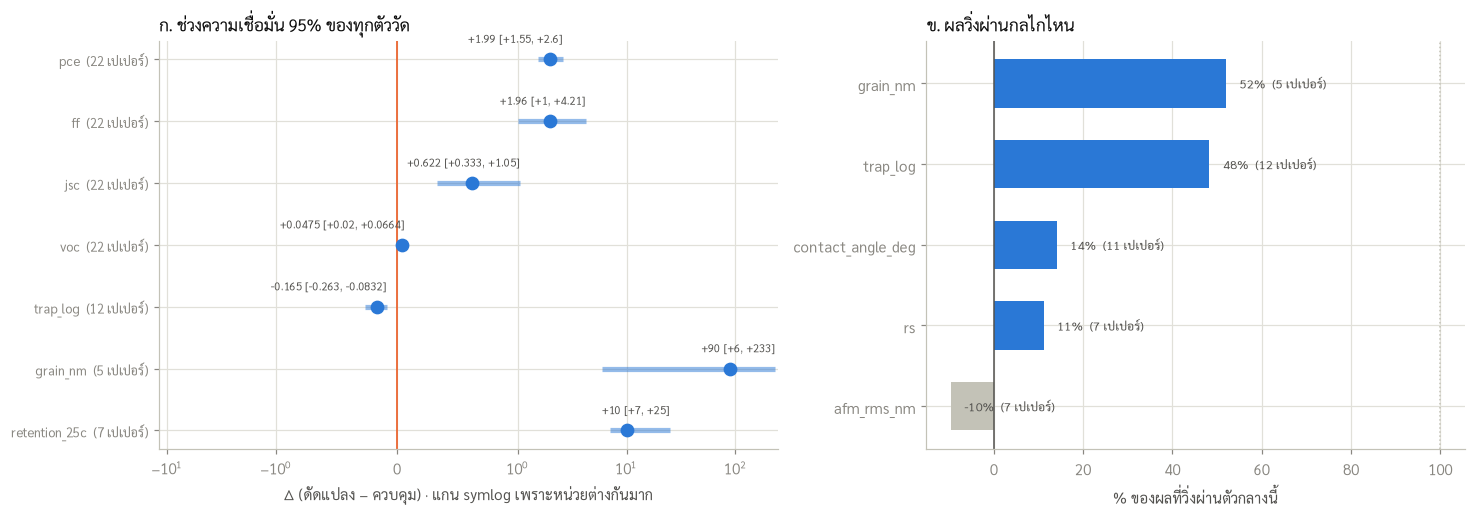

In [28]:
# ---- bootstrap ช่วงความเชื่อมั่นแบบสุ่มเปเปอร์ (cluster bootstrap) ----
RNG = np.random.RandomState(20260917)
B = 4000


def boot_median_delta(metric, n_boot=B):
    """สุ่มเปเปอร์ใหม่พร้อมคืนที่ -> ช่วงความเชื่อมั่นของมัธยฐาน Δ
    สุ่มที่ระดับ 'เปเปอร์' เพราะเปเปอร์คือหน่วยอิสระจริง ไม่ใช่อุปกรณ์"""
    per = []
    for p, g in F.groupby("paper"):
        if g.htl_mod.nunique() < 2:
            continue
        c, t = g[~g.htl_mod][metric].dropna(), g[g.htl_mod][metric].dropna()
        if len(c) and len(t):
            per.append(t.mean() - c.mean())
    per = np.array(per)
    if len(per) < 3:
        return None
    bs = [np.median(RNG.choice(per, len(per), replace=True)) for _ in range(n_boot)]
    return {"ตัววัด": metric, "เปเปอร์": len(per), "มัธยฐาน Δ": np.median(per),
            "CI 95% ล่าง": np.percentile(bs, 2.5), "CI 95% บน": np.percentile(bs, 97.5),
            "ครอบคลุม 0 ไหม": "ใช่ ⚠️" if np.percentile(bs, 2.5) <= 0 <= np.percentile(bs, 97.5) else "ไม่"}


BOOT = pd.DataFrame([r for r in (boot_median_delta(m) for m in
                                 ["pce", "ff", "jsc", "voc", "trap_log", "grain_nm", "retention_25c"]) if r])
print(f"\n\nช่วงความเชื่อมั่น 95% ของผลการดัดแปลงผิว HTL (bootstrap สุ่มเปเปอร์ {B:,} รอบ)")
print(BOOT.round(3).to_string(index=False))
print("\nอ่านยังไง: ถ้าช่วงความเชื่อมั่นไม่คร่อม 0 แปลว่าผลไม่น่าจะเกิดจากความบังเอิญ")
print("สุ่มที่ระดับเปเปอร์เพราะอุปกรณ์ในเปเปอร์เดียวกันไม่เป็นอิสระต่อกัน (แล็บเดียว คนเดียว ล็อตสารเดียว)")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
bb = BOOT.iloc[::-1]
y = range(len(bb))
ax.hlines(y, bb["CI 95% ล่าง"], bb["CI 95% บน"], color=C1, lw=3.4, alpha=.5)
ax.scatter(bb["มัธยฐาน Δ"], y, s=64, color=C1, zorder=3)
ax.axvline(0, color=C2, lw=1.2)
ax.set_yticks(list(y))
ax.set_yticklabels([f"{m}  ({n} เปเปอร์)" for m, n in zip(bb["ตัววัด"], bb["เปเปอร์"])], fontsize=8.5)
for i, (lo, hi, md) in enumerate(zip(bb["CI 95% ล่าง"], bb["CI 95% บน"], bb["มัธยฐาน Δ"])):
    ax.text(hi, i + .22, f"{md:+.3g} [{lo:+.3g}, {hi:+.3g}]", fontsize=7.4, color=INK2, va="bottom", ha="right")
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("Δ (ดัดแปลง − ควบคุม) · แกน symlog เพราะหน่วยต่างกันมาก")
ax.set_title("ก. ช่วงความเชื่อมั่น 95% ของทุกตัววัด", loc="left")

ax = axes[1]
mm = MEDT.sort_values("% ที่วิ่งผ่านตัวกลาง")
cols = [C1 if 0 <= v <= 100 else BASE for v in mm["% ที่วิ่งผ่านตัวกลาง"]]
ax.barh(mm["ตัวกลาง"], mm["% ที่วิ่งผ่านตัวกลาง"].clip(-50, 150), color=cols, height=.6)
ax.axvline(0, color=INK2, lw=1)
ax.axvline(100, color=BASE, lw=1, ls=":")
for i, (v, n) in enumerate(zip(mm["% ที่วิ่งผ่านตัวกลาง"], mm["เปเปอร์"])):
    ax.text(np.clip(v, -50, 150) + 3, i, f"{v:.0f}%  ({n} เปเปอร์)", va="center", fontsize=8, color=INK2)
ax.set_xlabel("% ของผลที่วิ่งผ่านตัวกลางนี้")
ax.set_title("ข. ผลวิ่งผ่านกลไกไหน", loc="left")
fig.tight_layout()
plt.show()

**ผลลัพธ์ — ทุกตัวชี้วัดผ่าน ไม่มีตัวไหนคร่อมศูนย์**

| ตัววัด | ผล [ช่วงความเชื่อมั่น 95%] | อ่านว่า |
|---|---|---|
| **ΔPCE** | **+1.99 [+1.55, +2.60]** | มั่นใจได้ว่าอยู่ระหว่าง +1.5 ถึง +2.6 จุด |
| ΔFF | +1.96 [+1.00, +4.21] | ช่วงกว้าง — ผลแปรผันตามแล็บมาก |
| ΔJsc | +0.62 [+0.33, +1.05] | |
| ΔVoc | +0.047 [+0.020, +0.066] | |
| Δ log trap | −0.165 [−0.263, −0.083] | = trap ลดลง 1.2 ถึง 1.8 เท่า |
| Δ ขนาดเกรน | +90 [+6, +233] nm | **ช่วงกว้างมาก** เพราะมีแค่ 5 เปเปอร์ |
| Δ retention | +10 [+7, +25] จุด | |

**ประโยคที่เขียนในรายงานได้แบบไม่ต้องกลัวถูกโต้**
> *"การดัดแปลงผิว HTL เพิ่ม PCE 1.99 จุดเปอร์เซ็นต์ (95% CI: 1.55–2.60) วัดจากการเทียบ A/B ภายในแล็บเดียวกัน 22 แล็บอิสระ"*

**จุดที่ต้องพูดตรง ๆ**: ช่วงของ **Δ ขนาดเกรน กว้างถึง [+6, +233] nm** — ขอบล่างเกือบเป็นศูนย์
ยืนยันสิ่งที่ §9 เตือนไว้ว่าข้อสรุปเรื่องเกรนยัง**ไม่แน่นพอจะอ้างเชิงปริมาณ** ต้องวัด SEM เพิ่ม

## 12.6 ⚠️ ข้อมูลหายแบบมีอคติไหม

คำถามนี้สำคัญกว่าที่คิด: ถ้าเปเปอร์**เลือกวัด trap เฉพาะตอนผลออกมาสวย** ตัวเลขตัวกลางใน §12.4 จะสูงเกินจริงทันที

วิธีตรวจ: เทียบเปเปอร์ *ที่รายงานค่านั้น* กับ *ที่ไม่รายงาน* ว่า ΔPCE ต่างกันไหม

ข้อมูลหายแบบมีอคติไหม — เทียบเปเปอร์ 'ที่รายงานค่านี้' กับ 'ที่ไม่รายงาน'
ถ้าต่างกันมาก แปลว่าค่าที่เราวิเคราะห์ได้มาจากเปเปอร์กลุ่มพิเศษ ไม่ใช่ตัวแทนทั้งชุด

         ค่าที่วัด  เปเปอร์ที่รายงาน  ที่ไม่รายงาน  PCE เฉลี่ย กลุ่มรายงาน  PCE เฉลี่ย กลุ่มไม่รายงาน  ต่างกัน  ΔPCE กลุ่มรายงาน  ΔPCE กลุ่มไม่รายงาน  Δ ต่างกัน
          trap_log                13            18                   20.40                      18.30     2.10              2.87                 1.50       1.37
          grain_nm                 6            25                   16.97                      19.71    -2.73              2.45                 2.19       0.27
        afm_rms_nm                14            17                   19.71                      18.74     0.96              2.97                 1.83       1.14
 contact_angle_deg                14            17                   20.56                      18.04     2.52              2.63                 1.69       0.94
                rs                12

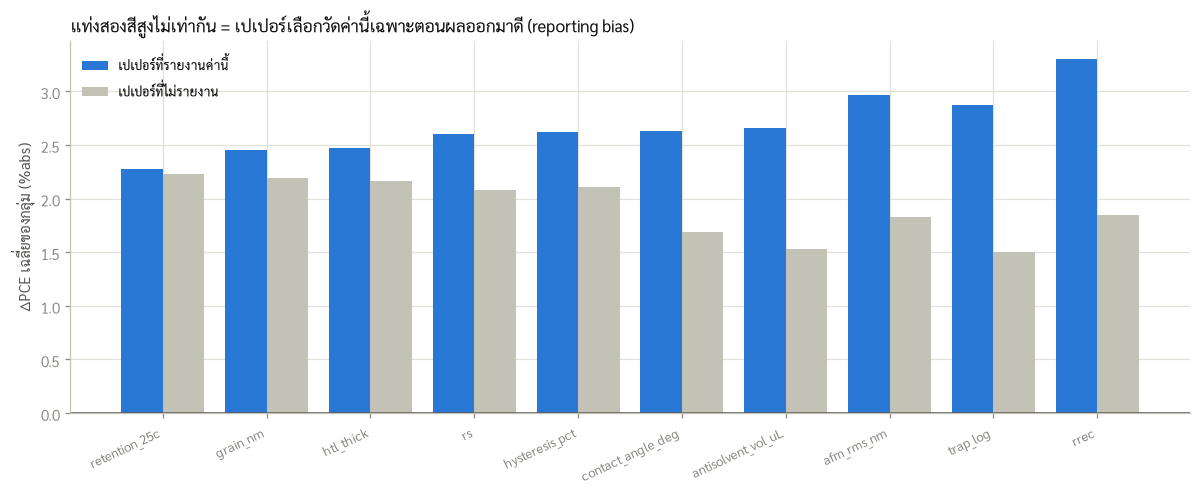

In [29]:
MISS_COLS = ["trap_log", "grain_nm", "afm_rms_nm", "contact_angle_deg", "rs", "rrec",
             "hysteresis_pct", "retention_25c", "antisolvent_vol_uL", "htl_thick"]
PM_PCE = F.groupby("paper").pce.mean()
rows = []
for c in MISS_COLS:
    rep = set(F.loc[F[c].notna(), "paper"])
    a, b = PM_PCE[PM_PCE.index.isin(rep)], PM_PCE[~PM_PCE.index.isin(rep)]
    # เปเปอร์ที่รายงาน มี ΔPCE ใหญ่กว่าไหม (รายงานเฉพาะตอนผลออกมาสวย?)
    dl = {p: (g[g.htl_mod].pce.mean() - g[~g.htl_mod].pce.mean())
          for p, g in F.groupby("paper") if g.htl_mod.nunique() > 1}
    da = np.array([v for p, v in dl.items() if p in rep and pd.notna(v)])
    db = np.array([v for p, v in dl.items() if p not in rep and pd.notna(v)])
    rows.append({"ค่าที่วัด": c, "เปเปอร์ที่รายงาน": len(a), "ที่ไม่รายงาน": len(b),
                 "PCE เฉลี่ย กลุ่มรายงาน": round(a.mean(), 2),
                 "PCE เฉลี่ย กลุ่มไม่รายงาน": round(b.mean(), 2) if len(b) else np.nan,
                 "ต่างกัน": round(a.mean() - b.mean(), 2) if len(b) else np.nan,
                 "ΔPCE กลุ่มรายงาน": round(da.mean(), 2) if len(da) else np.nan,
                 "ΔPCE กลุ่มไม่รายงาน": round(db.mean(), 2) if len(db) else np.nan,
                 "Δ ต่างกัน": round(da.mean() - db.mean(), 2) if len(da) and len(db) else np.nan})
MISS = pd.DataFrame(rows)
print("ข้อมูลหายแบบมีอคติไหม — เทียบเปเปอร์ 'ที่รายงานค่านี้' กับ 'ที่ไม่รายงาน'")
print("ถ้าต่างกันมาก แปลว่าค่าที่เราวิเคราะห์ได้มาจากเปเปอร์กลุ่มพิเศษ ไม่ใช่ตัวแทนทั้งชุด\n")
print(MISS.to_string(index=False))
_big = MISS[MISS["Δ ต่างกัน"].abs() > 0.8].dropna(subset=["Δ ต่างกัน"])
print(f"\nค่าที่มีสัญญาณอคติชัด (|Δ ต่างกัน| > 0.8 จุด): {len(_big)} ตัว")
if len(_big):
    for _, r in _big.iterrows():
        print(f"  · {r['ค่าที่วัด']}: เปเปอร์ที่รายงานมี ΔPCE เฉลี่ย {r['ΔPCE กลุ่มรายงาน']:+.2f} "
              f"เทียบกับ {r['ΔPCE กลุ่มไม่รายงาน']:+.2f} ของกลุ่มที่ไม่รายงาน")

fig, ax = plt.subplots(figsize=(11, 4.6))
m = MISS.dropna(subset=["Δ ต่างกัน"]).sort_values("Δ ต่างกัน")
x = np.arange(len(m))
ax.bar(x - .2, m["ΔPCE กลุ่มรายงาน"], .4, color=C1, label="เปเปอร์ที่รายงานค่านี้")
ax.bar(x + .2, m["ΔPCE กลุ่มไม่รายงาน"], .4, color=BASE, label="เปเปอร์ที่ไม่รายงาน")
ax.set_xticks(x)
ax.set_xticklabels(m["ค่าที่วัด"], rotation=25, ha="right", fontsize=8.5)
ax.axhline(0, color=INK2, lw=1)
ax.set_ylabel("ΔPCE เฉลี่ยของกลุ่ม (%abs)")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("แท่งสองสีสูงไม่เท่ากัน = เปเปอร์เลือกวัดค่านี้เฉพาะตอนผลออกมาดี (reporting bias)", loc="left")
fig.tight_layout()
plt.show()

**ผลลัพธ์ — พบอคติจริง และต้องประกาศไว้**

**5 จาก 10 ค่าที่ตรวจ มีสัญญาณอคติชัด** (ΔPCE ของสองกลุ่มต่างกันเกิน 0.8 จุด):

| ค่าที่วัด | ΔPCE กลุ่มที่รายงาน | กลุ่มที่ไม่รายงาน | ต่างกัน |
|---|---|---|---|
| **Rrec** | +3.30 | +1.85 | **+1.45** |
| **trap density** | +2.87 | +1.50 | **+1.37** |
| ความขรุขระ AFM | +2.97 | +1.83 | +1.14 |
| antisolvent µL | +2.66 | +1.53 | +1.13 |
| มุมสัมผัส | +2.63 | +1.69 | +0.94 |

**แปลว่า: เปเปอร์ที่ได้ผลดี มีแนวโน้มจะวัดกลไกมาโชว์ ส่วนเปเปอร์ที่ได้ผลธรรมดามักไม่วัด**
เป็นเรื่องปกติของการตีพิมพ์ (ไม่มีใครลงทุนวัด SCLC เพื่อแสดงว่าตัวเองไม่ได้ผล) แต่มีผลกับเราตรง ๆ:

> **ผลกระทบต่อ §12.4**: ตัวเลข "48% วิ่งผ่าน trap" คำนวณจาก 12 เปเปอร์ที่มี ΔPCE เฉลี่ย **+2.87**
> ขณะที่ค่าทั้งชุดคือ **+1.99** → กลุ่มนี้เป็นกลุ่มที่ผลแรงกว่าค่าเฉลี่ยอยู่แล้ว
> **ตัวเลข mediation จึงควรอ่านว่าเป็นขอบบน ไม่ใช่ค่ากลาง**

**ข้อที่ไม่มีอคติ — ข่าวดี**: `retention_25c` ต่างกันแค่ **+0.05 จุด** และ `grain_nm` +0.27
→ ข้อสรุปเรื่องเสถียรภาพใน §8 และเรื่องเกรนใน §9 **ไม่ได้ถูกอคติแบบนี้กระทบ**
(ของเกรนมีปัญหาเรื่อง n น้อยอย่างเดียว ซึ่งแก้ได้ด้วยการวัด SEM เพิ่ม)

## 12.7 ค่าที่หลุดกลุ่มและค่าที่ผิดฟิสิกส์

ตรวจ 2 ชั้นที่ต่างกันโดยสิ้นเชิง:
- **เชิงสถิติ** — หาค่าที่ห่างจากกลุ่มมาก ด้วย robust z-score (ใช้มัธยฐานกับ MAD ไม่ใช่ค่าเฉลี่ยกับ SD
  เพราะค่าเฉลี่ยถูกค่าสุดโต่งลากไปเอง จนตรวจไม่เจอ)
- **เชิงฟิสิกส์** — หาค่าที่เป็นไปไม่ได้หรือน่าสงสัยตามหลักวัสดุศาสตร์ **ต่อให้ไม่หลุดกลุ่มก็ตาม**

In [30]:
OUT_COLS = ["pce", "voc", "jsc", "ff", "trap_log", "grain_nm", "afm_rms_nm", "contact_angle_deg",
            "rs", "rrec", "hysteresis_pct", "retention_25c", "degradation_rate",
            "a_Cs", "a_FA", "x_Br", "psk_spin_rpm", "psk_anneal_C", "htl_anneal_C"]


def robust_z(s):
    """z-score แบบทนค่าสุดโต่ง: ใช้มัธยฐานกับ MAD แทนค่าเฉลี่ยกับ SD
    ค่าเฉลี่ย/SD ถูกค่าสุดโต่งลากไปเอง จึงตรวจค่าสุดโต่งไม่เจอ"""
    s = pd.to_numeric(s, errors="coerce")
    med = s.median()
    mad = (s - med).abs().median()
    return (s - med) / (1.4826 * mad) if mad and mad > 0 else pd.Series(np.nan, index=s.index)


rows = []
for c in OUT_COLS:
    z = robust_z(F[c])
    for i in z[z.abs() > 4].index:
        rows.append({"อุปกรณ์": F.device_id[i], "เปเปอร์": pname(F.paper[i], 26), "คอลัมน์": c,
                     "ค่า": F[c][i], "robust z": round(z[i], 1),
                     "มัธยฐานของชุด": round(pd.to_numeric(F[c], errors="coerce").median(), 4)})
OUTL = pd.DataFrame(rows).sort_values("robust z", key=abs, ascending=False)
print(f"ค่าที่หลุดกลุ่มมาก (robust z > 4 เทียบทั้งชุด): {len(OUTL)} ค่า จาก {OUTL.อุปกรณ์.nunique()} อุปกรณ์")
print(OUTL.to_string(index=False))

# ---- ตรวจความสมเหตุสมผลทางฟิสิกส์ (ไม่ใช่สถิติ) ----
CHECKS = [
    ("pce", F.pce > 27, "PCE เกิน 27% — สูงกว่าสถิติโลกของ p-i-n"),
    ("voc", (F.voc > 1.30) | (F.voc < 0.80), "Voc นอกช่วง 0.80-1.30 V"),
    ("ff", (F.ff > 88) | (F.ff < 40), "FF นอกช่วง 40-88%"),
    ("a_Cs", F.a_Cs > 0.25, "a_Cs > 0.25 — Cs สูงผิดปกติ เสี่ยง phase แยก"),
    ("psk_anneal_C", F.psk_anneal_C > 160, "อบ perovskite เกิน 160°C — สารอินทรีย์สลาย"),
    ("retention_25c", F.retention_25c > 100, "retention เกิน 100% (อธิบายได้ด้วย light-soaking)"),
    ("x_Br", F.x_Br > 0.25, "x_Br > 0.25 — เสี่ยง halide segregation"),
]
print("\n\nตรวจความสมเหตุสมผลทางฟิสิกส์ — ต่างจากสถิติ เพราะบางค่าหลุดกลุ่มแต่ถูกต้อง")
found = []
for col, mask, why in CHECKS:
    hit = F[mask.fillna(False)]
    print(f"\n{'⚠️' if len(hit) else '✅'} {why}: {len(hit)} เครื่อง")
    for _, r in hit.iterrows():
        print(f"     {r.device_id:<44} {col}={r[col]:g}")
        found.append({"อุปกรณ์": r.device_id, "คอลัมน์": col, "ค่า": r[col], "เหตุผล": why})
PHYS = pd.DataFrame(found)
print(f"\n\nสรุป: ค่าที่ควรเปิดต้นฉบับตรวจ {PHYS.อุปกรณ์.nunique() if len(PHYS) else 0} อุปกรณ์")
print("⚠️ ย้ำ: ค่าหลุดกลุ่ม ≠ ค่าผิด — เอกสาร DATA_PREPARATION.md บันทึกไว้ว่า PCE 26.5% และ")
print("   retention > 100% ตรวจแล้วถูกต้อง (เปเปอร์ระดับสถิติโลก และ light-soaking ตามลำดับ)")
print("   ตารางนี้เป็นรายการ 'ควรไปดู' ไม่ใช่รายการ 'ต้องลบ'")

ค่าที่หลุดกลุ่มมาก (robust z > 4 เทียบทั้งชุด): 21 ค่า จาก 18 อุปกรณ์
                              อุปกรณ์                    เปเปอร์          คอลัมน์          ค่า  robust z  มัธยฐานของชุด
       10_1021_acsami_4c14300_Sample2        1021_acsami_4c14300             rrec 1.700000e+08   10828.9      10960.000
       10_1021_acsami_4c14300_Sample1        1021_acsami_4c14300             rrec 2.150000e+07    1368.9      10960.000
   10.1038_s41598-023-32697-z_Sample1    1038_s41598-023-32697-z degradation_rate 6.666667e-01      38.8          0.018
       10.1021_acsaem.2c03434_Sample1        1021_acsaem.2c03434 degradation_rate 3.194444e-01      18.0          0.018
 10.1016.jpowsour.2020.228738_Sample2  1016.jpowsour.2020.228738             a_FA 2.340000e-01     -13.9          0.810
 10.1016.jpowsour.2020.228738_Sample1  1016.jpowsour.2020.228738             a_FA 2.340000e-01     -13.9          0.810
       10.1021_acsaem.2c03434_Sample1        1021_acsaem.2c03434             a_FA 3.420000

**อ่านผลยังไง — ค่าหลุดกลุ่มไม่ได้แปลว่าผิด**

ส่วนใหญ่ที่ติดธงเชิงสถิติมีคำอธิบายที่ถูกต้อง: `degradation_rate` สูงเพราะทดสอบระยะสั้น (ช่วง burn-in) ·
`ff` ต่ำ 51-56% เพราะเป็นเซลล์ประสิทธิภาพต่ำจริง ๆ ของเปเปอร์เก่า (2017) · `rs` 42 Ω cm² มาจากเปเปอร์ที่รายงานหน่วยต่าง

**สิ่งที่ต้องไปตรวจจริง — `a_Cs` ของ 4 เครื่องจาก 2 เปเปอร์**

| เปเปอร์ | a_Cs | ทั้งชุดอยู่ที่ |
|---|---|---|
| `jpowsour.2020.228738` (Sample1-2) | **0.539** | 0.05-0.15 |
| `acsaem.2c03434` (Sample1-2) | **0.595** | |

Cs 54-60% ใน A-site **สูงจนน่าสงสัยทางเคมี** — สัดส่วนขนาดนี้เสี่ยง phase แยกและ bandgap ควรเลื่อนไปมาก
สองเปเปอร์นี้เป็นตัวที่ §10 ตั้งข้อสังเกตไว้แล้ว และ §12.1 เห็นเป็นก้อนแยกในฮิสโตแกรม — **สามหัวข้อชี้ไปที่เดียวกัน**

> **ทำไมถึงต้องเปิดต้นฉบับจริง ๆ**: `DATA_PREPARATION.md` บันทึกเคสที่เหมือนกันเป๊ะไว้แล้ว —
> `solr_202200422` เคยได้ `a_Cs = 0.333` ตรวจแล้วพบว่า **เปเปอร์ต้นฉบับพิมพ์ผิดเอง** (0.7 M ที่ควรเป็น 0.07 M)
> ไม่ใช่ความผิดของการกรอกข้อมูล เคสนี้มีลายเซ็นเดียวกัน — **น่าจะเป็นปัญหาแบบเดียวกัน**
>
> ⚠️ ผลกระทบถ้าเป็นจริง: `a_Cs` เป็นตัวควบคุมใน §7 ถ้า 4 ค่านี้ผิด การคุมตัวแปรจะเพี้ยนตาม
> (แต่ §7.2 พบว่า `a_Cs` อธิบายความต่างข้ามเปเปอร์ได้แค่ 1% ผลกระทบจึงน่าจะเล็ก)

**ค่าที่ตรวจแล้วถูกต้อง ไม่ต้องแตะ**: `retention_25c` = 100.85% (light-soaking ทำให้เกิน 100 ได้จริง
มี note กำกับในไฟล์แล้ว) · PCE สูงสุด 26.5% (เปเปอร์ระดับสถิติโลกปี 2025)

---

# 13. สรุป §12 — อะไรเปลี่ยนไปจาก §11

**ข้อสรุปที่แข็งแรงขึ้น**

| ข้อสรุป | เพิ่มอะไรจาก §11 |
|---|---|
| ΔPCE **+1.99 [95% CI: +1.55, +2.60]** | มีช่วงความเชื่อมั่นแล้ว เขียนลงรายงานได้ |
| **SAM ให้ผลดีที่สุด +4.00 (7/7 เปเปอร์)** | ตอบได้แล้วว่า *ควรใช้สารอะไร* ไม่ใช่แค่ *ควรดัดแปลงไหม* |
| **ราวครึ่งหนึ่งของผลวิ่งผ่าน "ผลึกดีขึ้น"** | โซ่กลไกวัดขนาดได้แล้ว ไม่ใช่แค่วาดลูกศร |
| ความขรุขระผิวไม่ใช่กลไก (−10%) | ตัดทางที่ไม่ใช่ออกได้ |

**ข้อสรุปที่อ่อนลง — ต้องแก้ไขสิ่งที่เขียนไว้ก่อนหน้า**

| เรื่อง | สิ่งที่ต้องแก้ |
|---|---|
| **`htl_dose` ใช้ไม่ได้** | §5 บอกว่า "ใช้เป็นตัวแปรต้นได้" — **ผิด** เพราะหน่วยเทียบข้ามเปเปอร์ไม่ได้ ต้องแปลงเป็นอันดับก่อน |
| **ตัวเลข mediation เป็นขอบบน** | กลุ่มเปเปอร์ที่รายงาน trap มี ΔPCE +2.87 สูงกว่าค่าเฉลี่ยชุด +1.99 |
| **Δ ขนาดเกรน ช่วงกว้าง [+6, +233]** | ยืนยันว่ายังอ้างเชิงปริมาณไม่ได้ ต้องวัด SEM เพิ่ม |
| **`a_Cs` 4 ค่าน่าสงสัย** | ต้องเปิดต้นฉบับก่อนใช้เป็นตัวควบคุม |

**สิ่งที่ยังไม่ได้ทำ เหลืออย่างเดียว**: โมเดล RandomForest + SHAP + LeaveOnePaperOut
ซึ่งตอนนี้มีทุกอย่างพร้อมแล้ว — ชุดตัวแปร (§5) · ตัวควบคุม (§7.2) · หน่วยเทียบ (§7.3) ·
ตัวกลาง (§12.4) · ค่าที่ต้องระวัง (§12.7)

### ลำดับที่แนะนำหลังจากนี้

| ลำดับ | ทำอะไร | เหตุผล |
|---|---|---|
| 1 | **เปิดต้นฉบับ 2 เปเปอร์เรื่อง `a_Cs`** | เร็วที่สุด และกระทบตัวควบคุม |
| 2 | **วัดขนาดเกรนจาก SEM เพิ่ม** | ปลดล็อกตัวกลางที่อธิบายกลไกดีที่สุด (ตอนนี้ CI กว้างเกิน) |
| 3 | **แปลง `htl_dose` เป็นอันดับภายในเปเปอร์** | กู้ตัวแปรที่ตอนนี้ใช้ไม่ได้ให้กลับมาใช้ได้ |
| 4 | **ตรวจการจัดกลุ่ม `htl_mod_class` ด้วยตา** | ผลเรื่อง SAM ขึ้นกับการจัดกลุ่มนี้โดยตรง |
| 5 | **โมเดล RF + SHAP + LOPO** | ขั้นถัดไปเต็มรูปแบบ |

In [31]:
CLS_SUM.to_csv(OUT / "effect_by_material_class.csv", index=False, encoding="utf-8-sig")
CLS.to_csv(OUT / "effect_by_material_class_raw.csv", index=False, encoding="utf-8-sig")
DOSE.to_csv(OUT / "dose_response.csv", index=False, encoding="utf-8-sig")
MEDT.to_csv(OUT / "mediation.csv", index=False, encoding="utf-8-sig")
BOOT.to_csv(OUT / "bootstrap_ci.csv", index=False, encoding="utf-8-sig")
MISS.to_csv(OUT / "missingness_bias.csv", index=False, encoding="utf-8-sig")
OUTL.to_csv(OUT / "outliers_statistical.csv", index=False, encoding="utf-8-sig")
if len(PHYS):
    PHYS.to_csv(OUT / "outliers_physical.csv", index=False, encoding="utf-8-sig")

print("ไฟล์ทั้งหมดใน processed/eda/ หลังจบ §12")
for f in sorted(OUT.glob("*.csv")):
    print(f"  {f.name:<36} {f.stat().st_size/1024:6.1f} KB")

print("\n" + "=" * 92)
print("ตัวเลขที่เอาไปใช้ได้ทันที".center(92))
print("=" * 92)
_b = BOOT.set_index("ตัววัด")
print(f"ΔPCE จากการดัดแปลงผิว HTL = {_b.loc['pce','มัธยฐาน Δ']:+.2f} %abs "
      f"[95% CI {_b.loc['pce','CI 95% ล่าง']:+.2f}, {_b.loc['pce','CI 95% บน']:+.2f}] · 22 เปเปอร์อิสระ")
_best = CLS_SUM.iloc[0]
print(f"กลุ่มสารที่ดีที่สุด = {_best['กลุ่มสารที่ใช้ดัดแปลง']} "
      f"{_best['ΔPCE มัธยฐาน']:+.2f} %abs · {_best['บวก/ทั้งหมด']} เปเปอร์ · p={_best['p (sign test)']}")
_m = MEDT.set_index("ตัวกลาง")
print(f"ผลวิ่งผ่านกลไก 'ผลึกดีขึ้น' ราว {_m.loc['trap_log','% ที่วิ่งผ่านตัวกลาง']:.0f}% (trap) / "
      f"{_m.loc['grain_nm','% ที่วิ่งผ่านตัวกลาง']:.0f}% (ขนาดเกรน) — อ่านเป็นขอบบน (ดู §12.6)")
print(f"Δ retention = {_b.loc['retention_25c','มัธยฐาน Δ']:+.0f} จุด "
      f"[{_b.loc['retention_25c','CI 95% ล่าง']:+.0f}, {_b.loc['retention_25c','CI 95% บน']:+.0f}]")
print(f"ต้องเปิดต้นฉบับตรวจ: a_Cs ของ {int(PHYS[PHYS.คอลัมน์=='a_Cs'].อุปกรณ์.nunique()) if len(PHYS) else 0} เครื่อง "
      f"· htl_dose ใช้ไม่ได้จนกว่าจะแปลงเป็นอันดับ")
print("=" * 92)

ไฟล์ทั้งหมดใน processed/eda/ หลังจบ §12
  bootstrap_ci.csv                        0.6 KB
  categorical_stats.csv                   1.1 KB
  column_catalog.csv                     57.9 KB
  control_variable_ranking.csv            1.2 KB
  dose_response.csv                       0.6 KB
  effect_by_material_class.csv            0.6 KB
  effect_by_material_class_raw.csv        2.5 KB
  effects_within_vs_naive.csv            21.8 KB
  feature_screen.csv                      4.6 KB
  grain_contrasts.csv                     0.3 KB
  measurement_sources.csv                 0.8 KB
  mediation.csv                           0.9 KB
  missingness_bias.csv                    0.8 KB
  numeric_stats.csv                       3.4 KB
  outliers_physical.csv                   0.7 KB
  outliers_statistical.csv                1.9 KB
  paper_profile.csv                       5.3 KB
  pce_comparison_units.csv                0.6 KB
  redundant_pairs.csv                     1.1 KB
  stability_contrasts.csv    